In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2023/PSIQUIATRÍA.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 4:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]),
                          len(answer_positions["C"]), len(answer_positions["D"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 9 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=149.5, y1=102.1
Page 1, Q1, A: Yellow pixels: 1371
Page 1, Q1, A: Total non-white pixels: 1848
Page 1, Q1, A: Yellow percentage: 74.2%


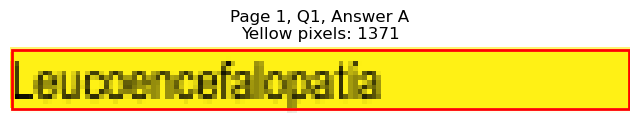

Page 1, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=131.5, y1=114.7
Page 1, Q1, B: Yellow pixels: 0
Page 1, Q1, B: Total non-white pixels: 423
Page 1, Q1, B: Yellow percentage: 0.0%


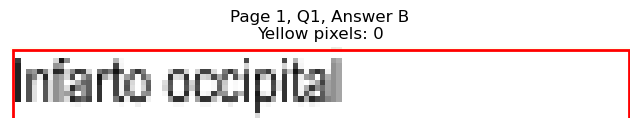

Page 1, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=424.4, y1=102.1
Page 1, Q1, C: Yellow pixels: 0
Page 1, Q1, C: Total non-white pixels: 500
Page 1, Q1, C: Yellow percentage: 0.0%


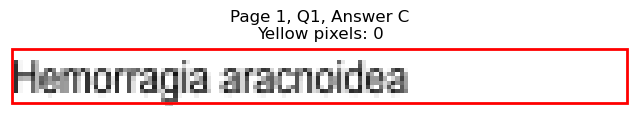

Page 1, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=418.9, y1=114.7
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 460
Page 1, Q1, D: Yellow percentage: 0.0%


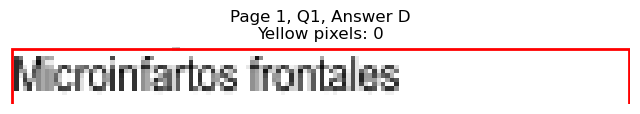


Page 1, Q1 - Selected Answer: A (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=116.4, y1=177.8
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 269
Page 1, Q2, A: Yellow percentage: 0.0%


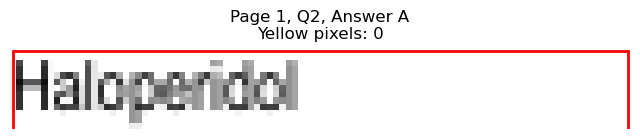

Page 1, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=87.4, y1=190.4
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 91
Page 1, Q2, B: Yellow percentage: 0.0%


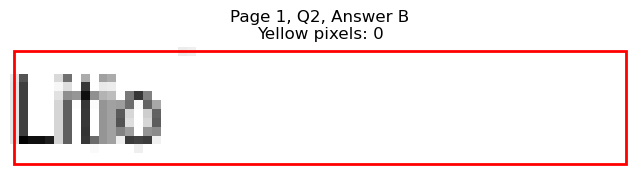

Page 1, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=373.1, y1=177.8
Page 1, Q2, C: Yellow pixels: 1102
Page 1, Q2, C: Total non-white pixels: 1261
Page 1, Q2, C: Yellow percentage: 87.4%


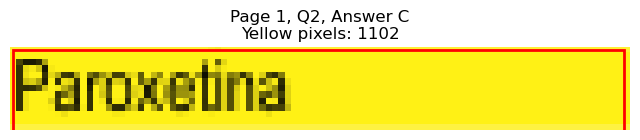

Page 1, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=370.6, y1=190.4
Page 1, Q2, D: Yellow pixels: 94
Page 1, Q2, D: Total non-white pixels: 312
Page 1, Q2, D: Yellow percentage: 30.1%


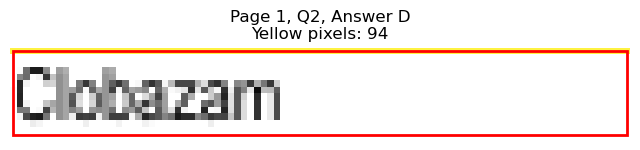


Page 1, Q2 - Selected Answer: C (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=124.0, y1=278.7
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 304
Page 1, Q3, A: Yellow percentage: 0.0%


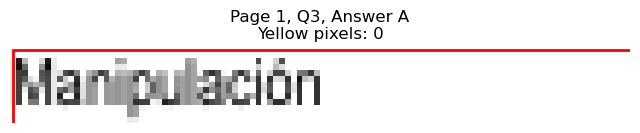

Page 1, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=125.5, y1=291.5
Page 1, Q3, B: Yellow pixels: 0
Page 1, Q3, B: Total non-white pixels: 315
Page 1, Q3, B: Yellow percentage: 0.0%


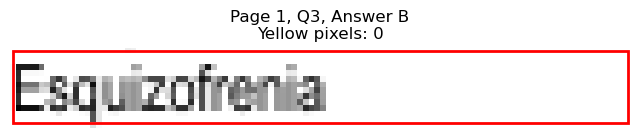

Page 1, Q3 - C: Detected box: x0=327.5, y0=266.1, x1=366.7, y1=278.7
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 203
Page 1, Q3, C: Yellow percentage: 0.0%


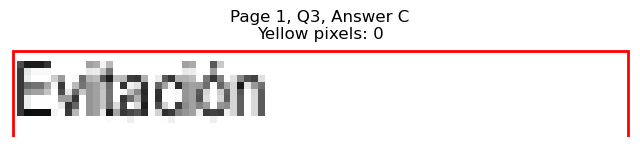

Page 1, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=373.7, y1=291.5
Page 1, Q3, D: Yellow pixels: 1069
Page 1, Q3, D: Total non-white pixels: 1358
Page 1, Q3, D: Yellow percentage: 78.7%


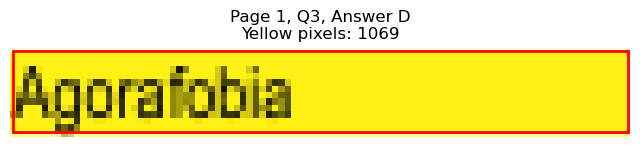


Page 1, Q3 - Selected Answer: D (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=126.5, y1=341.9
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 294
Page 1, Q4, A: Yellow percentage: 0.0%


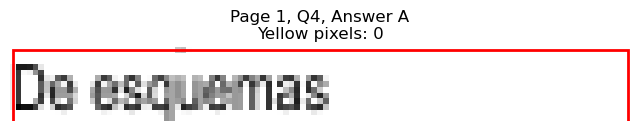

Page 1, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=154.6, y1=354.6
Page 1, Q4, B: Yellow pixels: 1426
Page 1, Q4, B: Total non-white pixels: 1918
Page 1, Q4, B: Yellow percentage: 74.3%


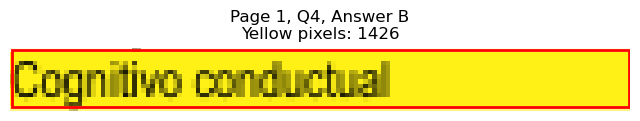

Page 1, Q4 - C: Detected box: x0=327.5, y0=329.2, x1=432.9, y1=341.9
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 570
Page 1, Q4, C: Yellow percentage: 0.0%


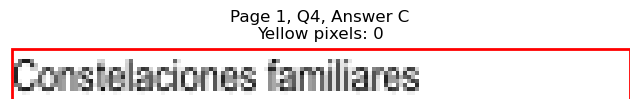

Page 1, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=382.3, y1=354.6
Page 1, Q4, D: Yellow pixels: 0
Page 1, Q4, D: Total non-white pixels: 293
Page 1, Q4, D: Yellow percentage: 0.0%


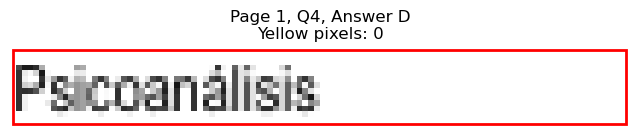


Page 1, Q4 - Selected Answer: B (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=165.1, x1=116.4, y1=177.8
Page 1, Q5, A: Yellow pixels: 0
Page 1, Q5, A: Total non-white pixels: 269
Page 1, Q5, A: Yellow percentage: 0.0%


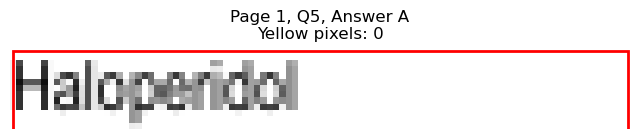

Page 1, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=114.5, y1=417.6
Page 1, Q5, B: Yellow pixels: 1076
Page 1, Q5, B: Total non-white pixels: 1358
Page 1, Q5, B: Yellow percentage: 79.2%


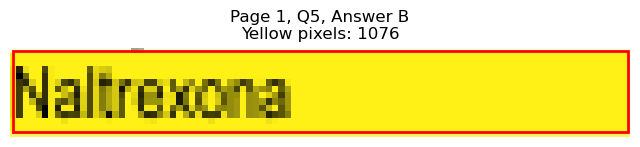

Page 1, Q5 - C: Detected box: x0=327.5, y0=392.3, x1=362.1, y1=405.0
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 170
Page 1, Q5, C: Yellow percentage: 0.0%


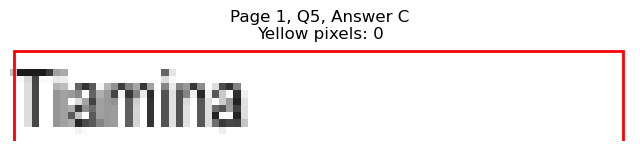

Page 1, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=372.7, y1=417.6
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 234
Page 1, Q5, D: Yellow percentage: 0.0%


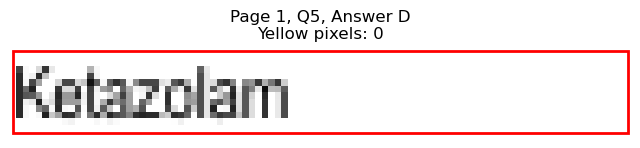


Page 1, Q5 - Selected Answer: B (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=493.4, x1=108.4, y1=506.0
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 202
Page 1, Q6, A: Yellow percentage: 0.0%


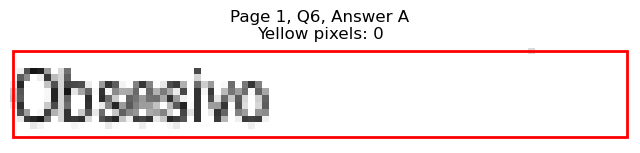

Page 1, Q6 - B: Detected box: x0=68.3, y0=506.0, x1=107.9, y1=518.6
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 211
Page 1, Q6, B: Yellow percentage: 0.0%


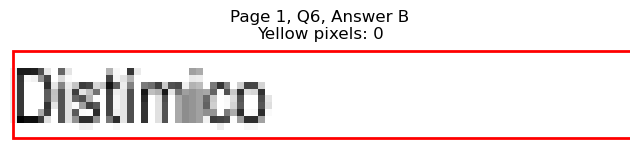

Page 1, Q6 - C: Detected box: x0=327.5, y0=493.4, x1=367.6, y1=506.0
Page 1, Q6, C: Yellow pixels: 91
Page 1, Q6, C: Total non-white pixels: 381
Page 1, Q6, C: Yellow percentage: 23.9%


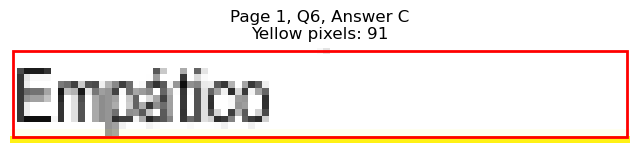

Page 1, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=369.7, y1=518.6
Page 1, Q6, D: Yellow pixels: 1026
Page 1, Q6, D: Total non-white pixels: 1302
Page 1, Q6, D: Yellow percentage: 78.8%


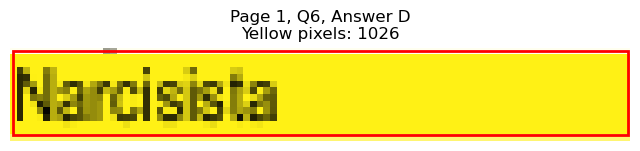


Page 1, Q6 - Selected Answer: D (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=594.3, x1=115.0, y1=607.0
Page 1, Q7, A: Yellow pixels: 0
Page 1, Q7, A: Total non-white pixels: 232
Page 1, Q7, A: Yellow percentage: 0.0%


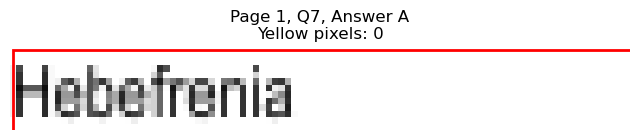

Page 1, Q7 - B: Detected box: x0=68.3, y0=606.9, x1=166.6, y1=619.6
Page 1, Q7, B: Yellow pixels: 0
Page 1, Q7, B: Total non-white pixels: 501
Page 1, Q7, B: Yellow percentage: 0.0%


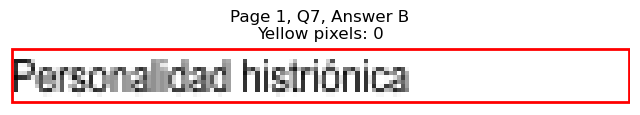

Page 1, Q7 - C: Detected box: x0=327.5, y0=594.3, x1=390.8, y1=607.0
Page 1, Q7, C: Yellow pixels: 0
Page 1, Q7, C: Total non-white pixels: 438
Page 1, Q7, C: Yellow percentage: 0.0%


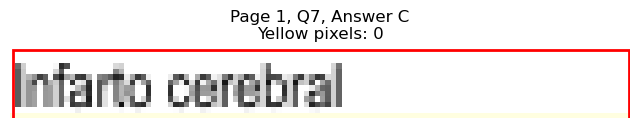

Page 1, Q7 - D: Detected box: x0=327.5, y0=606.9, x1=413.3, y1=619.6
Page 1, Q7, D: Yellow pixels: 1445
Page 1, Q7, D: Total non-white pixels: 1918
Page 1, Q7, D: Yellow percentage: 75.3%


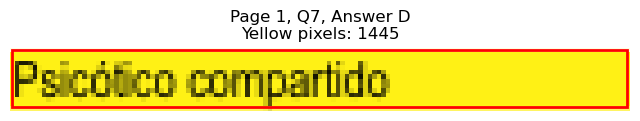


Page 1, Q7 - Selected Answer: D (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=657.5, x1=92.9, y1=670.1
Page 1, Q8, A: Yellow pixels: 0
Page 1, Q8, A: Total non-white pixels: 124
Page 1, Q8, A: Yellow percentage: 0.0%


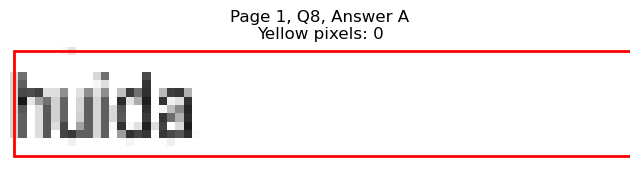

Page 1, Q8 - B: Detected box: x0=68.3, y0=670.1, x1=104.9, y1=682.7
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 186
Page 1, Q8, B: Yellow percentage: 0.0%


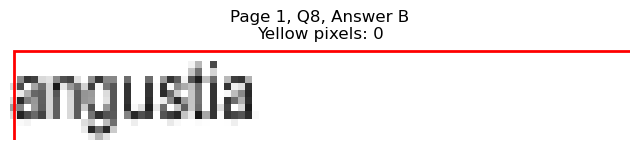

Page 1, Q8 - C: Detected box: x0=327.5, y0=657.5, x1=358.1, y1=670.1
Page 1, Q8, C: Yellow pixels: 82
Page 1, Q8, C: Total non-white pixels: 233
Page 1, Q8, C: Yellow percentage: 35.2%


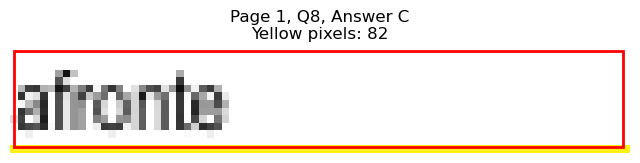

Page 1, Q8 - D: Detected box: x0=327.5, y0=670.1, x1=366.7, y1=682.7
Page 1, Q8, D: Yellow pixels: 1010
Page 1, Q8, D: Total non-white pixels: 1170
Page 1, Q8, D: Yellow percentage: 86.3%


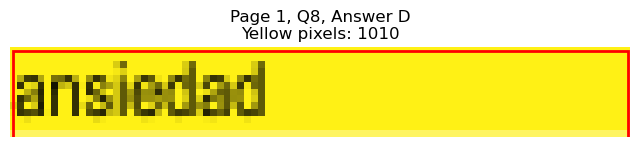


Page 1, Q8 - Selected Answer: D (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=68.3, y0=708.0, x1=105.4, y1=720.6
Page 1, Q9, A: Yellow pixels: 88
Page 1, Q9, A: Total non-white pixels: 253
Page 1, Q9, A: Yellow percentage: 34.8%


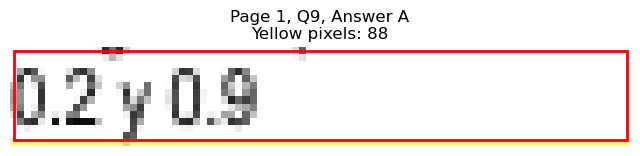

Page 1, Q9 - B: Detected box: x0=68.3, y0=720.6, x1=105.4, y1=733.2
Page 1, Q9, B: Yellow pixels: 1039
Page 1, Q9, B: Total non-white pixels: 1232
Page 1, Q9, B: Yellow percentage: 84.3%


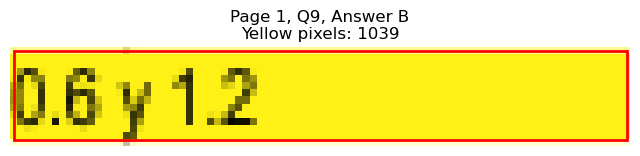

Page 1, Q9 - C: Detected box: x0=327.5, y0=708.0, x1=364.6, y1=720.6
Page 1, Q9, C: Yellow pixels: 0
Page 1, Q9, C: Total non-white pixels: 139
Page 1, Q9, C: Yellow percentage: 0.0%


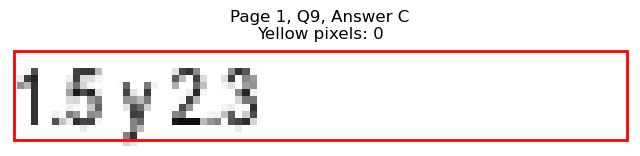

Page 1, Q9 - D: Detected box: x0=327.5, y0=720.6, x1=364.6, y1=733.2
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 124
Page 1, Q9, D: Yellow percentage: 0.0%


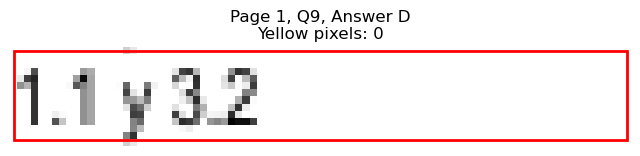


Page 1, Q9 - Selected Answer: B (based on yellow pixel count)





Page 2: Found 10 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=153.6, y1=102.1
Page 2, Q1, A: Yellow pixels: 1468
Page 2, Q1, A: Total non-white pixels: 1904
Page 2, Q1, A: Yellow percentage: 77.1%


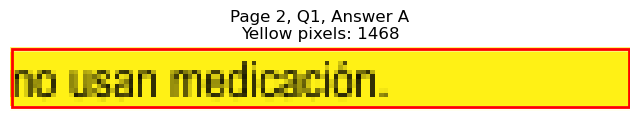

Page 2, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=120.5, y1=114.7
Page 2, Q1, B: Yellow pixels: 0
Page 2, Q1, B: Total non-white pixels: 341
Page 2, Q1, B: Yellow percentage: 0.0%


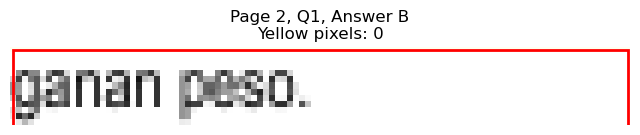

Page 2, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=406.3, y1=102.1
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 408
Page 2, Q1, C: Yellow percentage: 0.0%


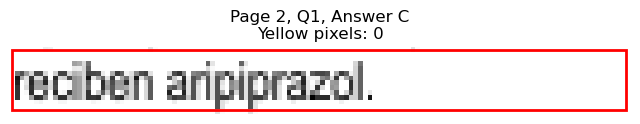

Page 2, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=377.2, y1=114.7
Page 2, Q1, D: Yellow pixels: 0
Page 2, Q1, D: Total non-white pixels: 227
Page 2, Q1, D: Yellow percentage: 0.0%


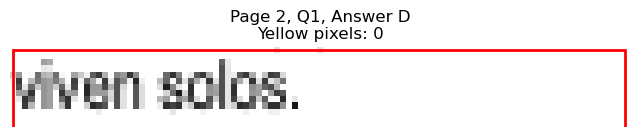


Page 2, Q1 - Selected Answer: A (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=105.9, y1=165.2
Page 2, Q2, A: Yellow pixels: 0
Page 2, Q2, A: Total non-white pixels: 199
Page 2, Q2, A: Yellow percentage: 0.0%


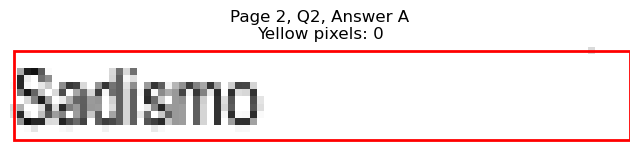

Page 2, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=101.9, y1=177.8
Page 2, Q2, B: Yellow pixels: 0
Page 2, Q2, B: Total non-white pixels: 165
Page 2, Q2, B: Yellow percentage: 0.0%


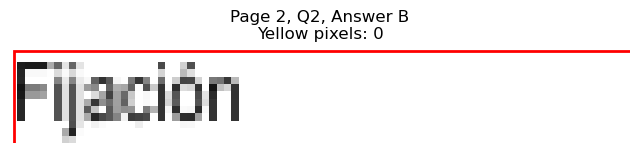

Page 2, Q2 - C: Detected box: x0=327.5, y0=152.5, x1=372.7, y1=165.2
Page 2, Q2, C: Yellow pixels: 96
Page 2, Q2, C: Total non-white pixels: 320
Page 2, Q2, C: Yellow percentage: 30.0%


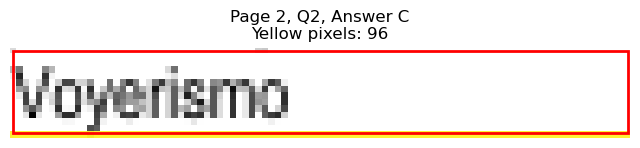

Page 2, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=381.3, y1=177.8
Page 2, Q2, D: Yellow pixels: 1155
Page 2, Q2, D: Total non-white pixels: 1365
Page 2, Q2, D: Yellow percentage: 84.6%


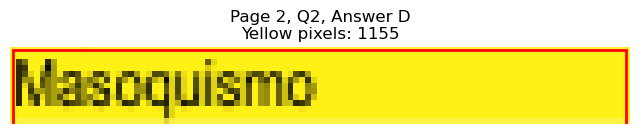


Page 2, Q2 - Selected Answer: D (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=102.9, y1=253.5
Page 2, Q3, A: Yellow pixels: 85
Page 2, Q3, A: Total non-white pixels: 266
Page 2, Q3, A: Yellow percentage: 32.0%


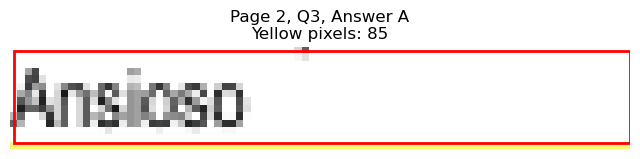

Page 2, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=124.5, y1=266.1
Page 2, Q3, B: Yellow pixels: 1181
Page 2, Q3, B: Total non-white pixels: 1498
Page 2, Q3, B: Yellow percentage: 78.8%


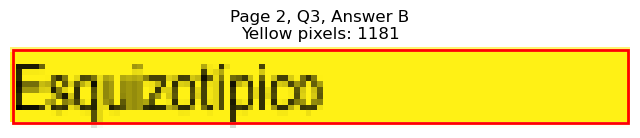

Page 2, Q3 - C: Detected box: x0=327.5, y0=240.9, x1=371.2, y1=253.5
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 207
Page 2, Q3, C: Yellow percentage: 0.0%


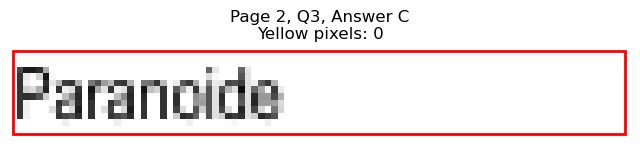

Page 2, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=383.2, y1=266.1
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 286
Page 2, Q3, D: Yellow percentage: 0.0%


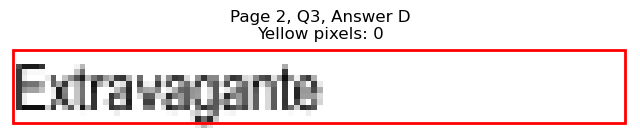


Page 2, Q3 - Selected Answer: B (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=113.4, y1=329.3
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 232
Page 2, Q4, A: Yellow percentage: 0.0%


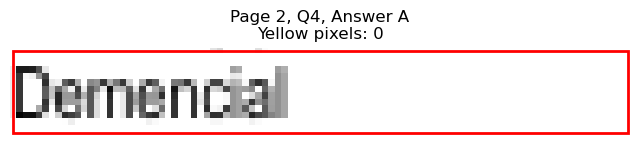

Page 2, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=107.4, y1=341.9
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 188
Page 2, Q4, B: Yellow percentage: 0.0%


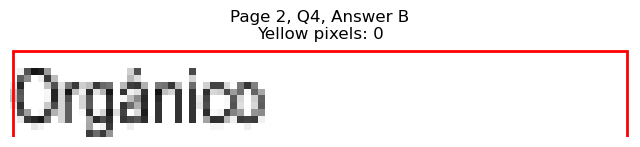

Page 2, Q4 - C: Detected box: x0=327.5, y0=316.6, x1=358.1, y1=329.3
Page 2, Q4, C: Yellow pixels: 875
Page 2, Q4, C: Total non-white pixels: 1148
Page 2, Q4, C: Yellow percentage: 76.2%


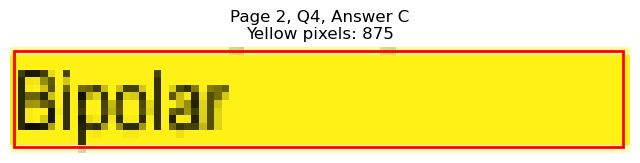

Page 2, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=414.3, y1=341.9
Page 2, Q4, D: Yellow pixels: 0
Page 2, Q4, D: Total non-white pixels: 570
Page 2, Q4, D: Yellow percentage: 0.0%


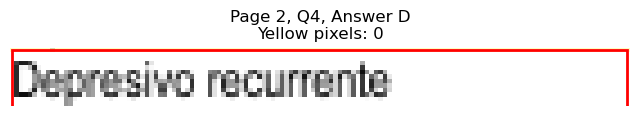


Page 2, Q4 - Selected Answer: C (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=140.5, y1=417.6
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 379
Page 2, Q5, A: Yellow percentage: 0.0%


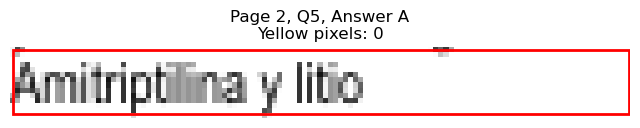

Page 2, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=163.1, y1=430.3
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 480
Page 2, Q5, B: Yellow percentage: 0.0%


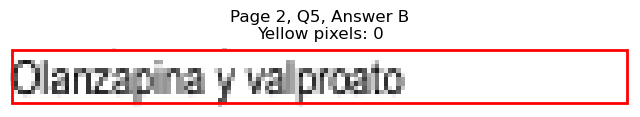

Page 2, Q5 - C: Detected box: x0=327.5, y0=404.9, x1=433.9, y1=417.6
Page 2, Q5, C: Yellow pixels: 0
Page 2, Q5, C: Total non-white pixels: 553
Page 2, Q5, C: Yellow percentage: 0.0%


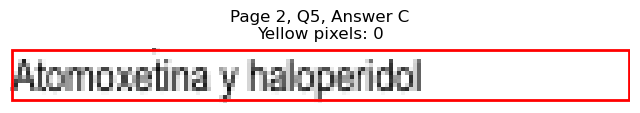

Page 2, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=424.4, y1=430.3
Page 2, Q5, D: Yellow pixels: 1427
Page 2, Q5, D: Total non-white pixels: 2072
Page 2, Q5, D: Yellow percentage: 68.9%


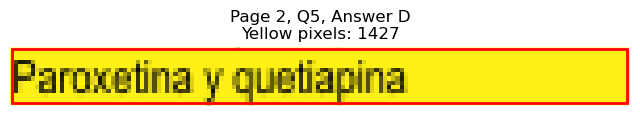


Page 2, Q5 - Selected Answer: D (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=117.5, y1=480.7
Page 2, Q6, A: Yellow pixels: 0
Page 2, Q6, A: Total non-white pixels: 279
Page 2, Q6, A: Yellow percentage: 0.0%


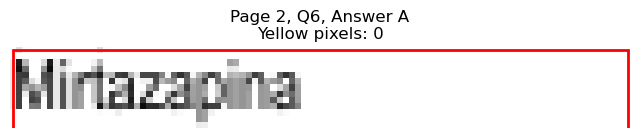

Page 2, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=109.5, y1=493.4
Page 2, Q6, B: Yellow pixels: 919
Page 2, Q6, B: Total non-white pixels: 1288
Page 2, Q6, B: Yellow percentage: 71.4%


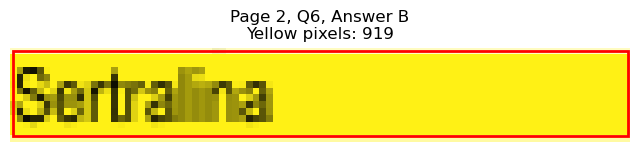

Page 2, Q6 - C: Detected box: x0=327.5, y0=468.1, x1=375.7, y1=480.7
Page 2, Q6, C: Yellow pixels: 0
Page 2, Q6, C: Total non-white pixels: 243
Page 2, Q6, C: Yellow percentage: 0.0%


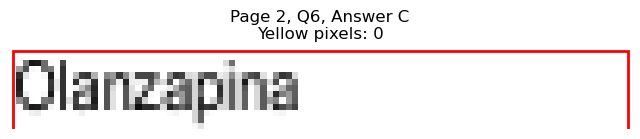

Page 2, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=372.7, y1=493.4
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 218
Page 2, Q6, D: Yellow percentage: 0.0%


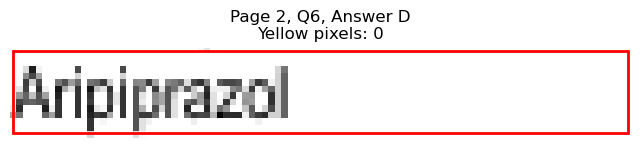


Page 2, Q6 - Selected Answer: B (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=150.5, y1=569.2
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 428
Page 2, Q7, A: Yellow percentage: 0.0%


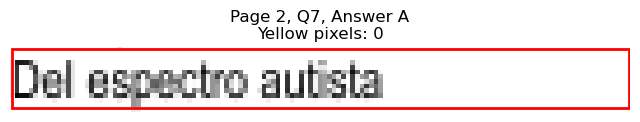

Page 2, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=159.6, y1=581.8
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 495
Page 2, Q7, B: Yellow percentage: 0.0%


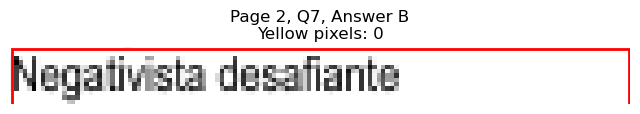

Page 2, Q7 - C: Detected box: x0=327.5, y0=556.5, x1=479.6, y1=569.2
Page 2, Q7, C: Yellow pixels: 2030
Page 2, Q7, C: Total non-white pixels: 2842
Page 2, Q7, C: Yellow percentage: 71.4%


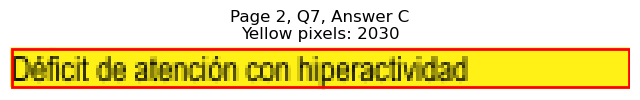

Page 2, Q7 - D: Detected box: x0=327.5, y0=569.1, x1=418.4, y1=581.8
Page 2, Q7, D: Yellow pixels: 0
Page 2, Q7, D: Total non-white pixels: 619
Page 2, Q7, D: Yellow percentage: 0.0%


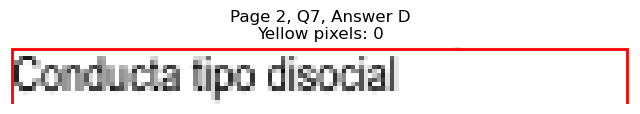


Page 2, Q7 - Selected Answer: C (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=93.9, y1=632.3
Page 2, Q8, A: Yellow pixels: 76
Page 2, Q8, A: Total non-white pixels: 202
Page 2, Q8, A: Yellow percentage: 37.6%


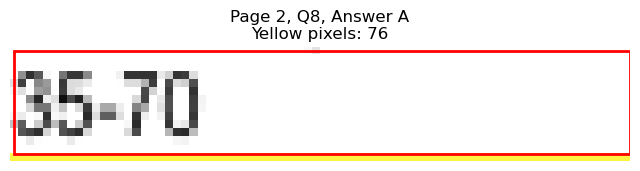

Page 2, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=106.0, y1=644.9
Page 2, Q8, B: Yellow pixels: 1021
Page 2, Q8, B: Total non-white pixels: 1144
Page 2, Q8, B: Yellow percentage: 89.2%


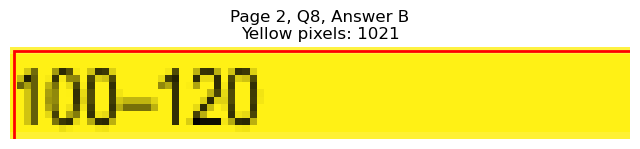

Page 2, Q8 - C: Detected box: x0=327.5, y0=619.6, x1=363.2, y1=632.3
Page 2, Q8, C: Yellow pixels: 0
Page 2, Q8, C: Total non-white pixels: 175
Page 2, Q8, C: Yellow percentage: 0.0%


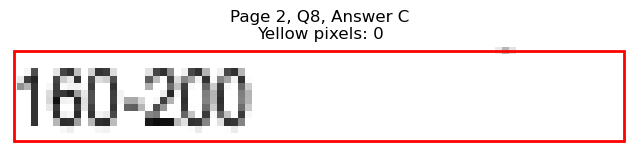

Page 2, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=355.6, y1=644.9
Page 2, Q8, D: Yellow pixels: 0
Page 2, Q8, D: Total non-white pixels: 134
Page 2, Q8, D: Yellow percentage: 0.0%


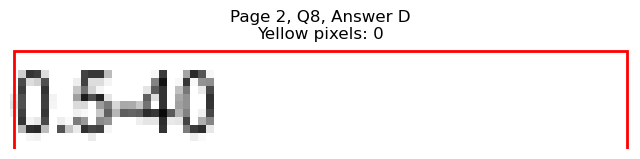


Page 2, Q8 - Selected Answer: B (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=68.3, y0=670.1, x1=119.9, y1=682.7
Page 2, Q9, A: Yellow pixels: 0
Page 2, Q9, A: Total non-white pixels: 253
Page 2, Q9, A: Yellow percentage: 0.0%


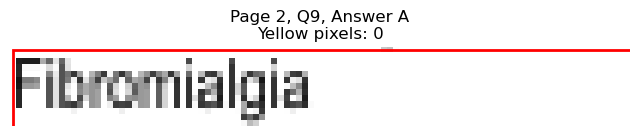

Page 2, Q9 - B: Detected box: x0=68.3, y0=682.7, x1=144.0, y1=695.3
Page 2, Q9, B: Yellow pixels: 0
Page 2, Q9, B: Total non-white pixels: 378
Page 2, Q9, B: Yellow percentage: 0.0%


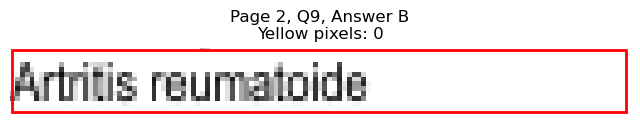

Page 2, Q9 - C: Detected box: x0=327.5, y0=670.1, x1=402.3, y1=682.7
Page 2, Q9, C: Yellow pixels: 0
Page 2, Q9, C: Total non-white pixels: 508
Page 2, Q9, C: Yellow percentage: 0.0%


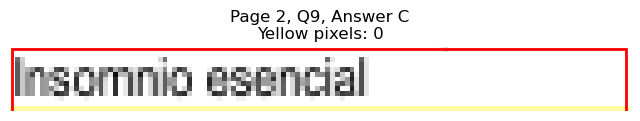

Page 2, Q9 - D: Detected box: x0=327.5, y0=682.7, x1=395.2, y1=695.3
Page 2, Q9, D: Yellow pixels: 1140
Page 2, Q9, D: Total non-white pixels: 1666
Page 2, Q9, D: Yellow percentage: 68.4%


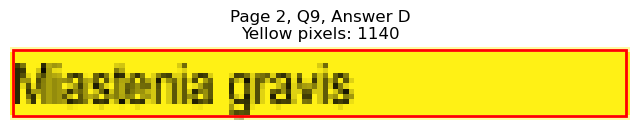


Page 2, Q9 - Selected Answer: D (based on yellow pixel count)




Page 2, Q10 - A: Detected box: x0=68.3, y0=733.2, x1=119.9, y1=745.8
Page 2, Q10, A: Yellow pixels: 1118
Page 2, Q10, A: Total non-white pixels: 1326
Page 2, Q10, A: Yellow percentage: 84.3%


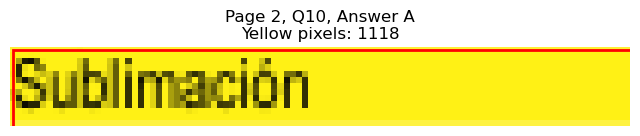

Page 2, Q10 - B: Detected box: x0=68.3, y0=745.8, x1=110.9, y1=758.4
Page 2, Q10, B: Yellow pixels: 93
Page 2, Q10, B: Total non-white pixels: 300
Page 2, Q10, B: Yellow percentage: 31.0%


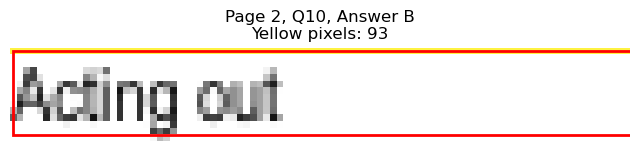

Page 2, Q10 - C: Detected box: x0=327.5, y0=733.2, x1=377.7, y1=745.8
Page 2, Q10, C: Yellow pixels: 0
Page 2, Q10, C: Total non-white pixels: 249
Page 2, Q10, C: Yellow percentage: 0.0%


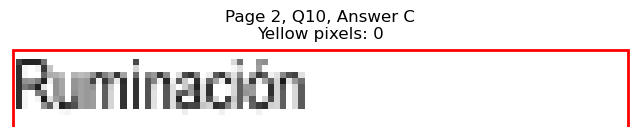

Page 2, Q10 - D: Detected box: x0=327.5, y0=745.8, x1=393.2, y1=758.4
Page 2, Q10, D: Yellow pixels: 0
Page 2, Q10, D: Total non-white pixels: 347
Page 2, Q10, D: Yellow percentage: 0.0%


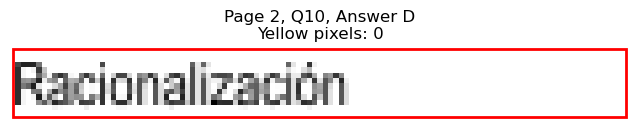


Page 2, Q10 - Selected Answer: A (based on yellow pixel count)





Page 3: Found 9 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=124.0, y1=127.3
Page 3, Q1, A: Yellow pixels: 0
Page 3, Q1, A: Total non-white pixels: 272
Page 3, Q1, A: Yellow percentage: 0.0%


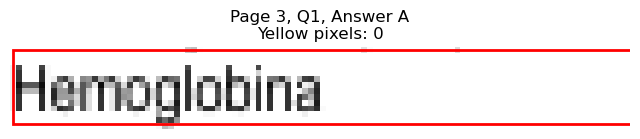

Page 3, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=110.9, y1=139.9
Page 3, Q1, B: Yellow pixels: 0
Page 3, Q1, B: Total non-white pixels: 204
Page 3, Q1, B: Yellow percentage: 0.0%


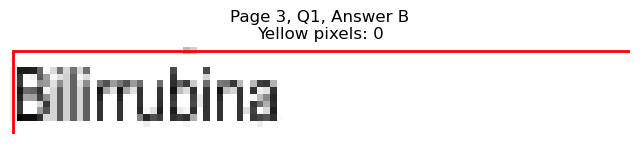

Page 3, Q1 - C: Detected box: x0=327.5, y0=114.6, x1=359.1, y1=127.3
Page 3, Q1, C: Yellow pixels: 83
Page 3, Q1, C: Total non-white pixels: 231
Page 3, Q1, C: Yellow percentage: 35.9%


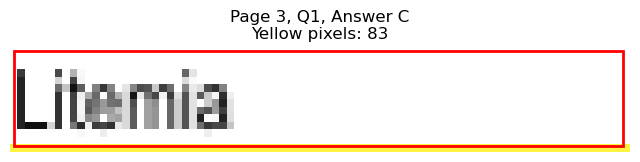

Page 3, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=382.7, y1=139.9
Page 3, Q1, D: Yellow pixels: 1146
Page 3, Q1, D: Total non-white pixels: 1378
Page 3, Q1, D: Yellow percentage: 83.2%


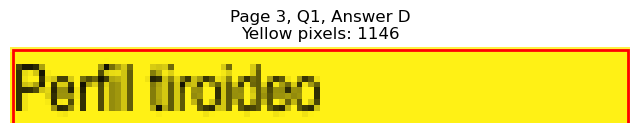


Page 3, Q1 - Selected Answer: D (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=162.6, y1=215.6
Page 3, Q2, A: Yellow pixels: 1490
Page 3, Q2, A: Total non-white pixels: 2030
Page 3, Q2, A: Yellow percentage: 73.4%


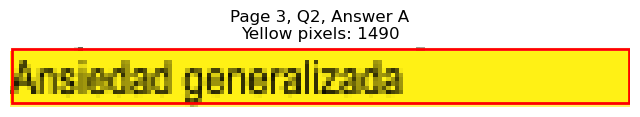

Page 3, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=157.6, y1=228.3
Page 3, Q2, B: Yellow pixels: 138
Page 3, Q2, B: Total non-white pixels: 606
Page 3, Q2, B: Yellow percentage: 22.8%


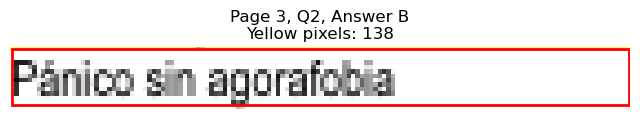

Page 3, Q2 - C: Detected box: x0=327.5, y0=202.9, x1=420.8, y1=215.6
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 504
Page 3, Q2, C: Yellow percentage: 0.0%


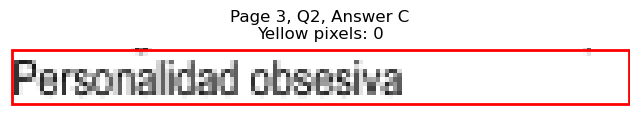

Page 3, Q2 - D: Detected box: x0=327.5, y0=215.7, x1=432.4, y1=228.3
Page 3, Q2, D: Yellow pixels: 0
Page 3, Q2, D: Total non-white pixels: 534
Page 3, Q2, D: Yellow percentage: 0.0%


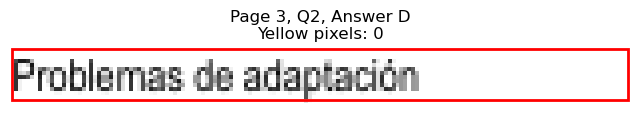


Page 3, Q2 - Selected Answer: A (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=304.0, x1=143.5, y1=316.7
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 522
Page 3, Q3, A: Yellow percentage: 0.0%


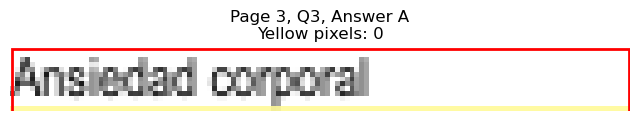

Page 3, Q3 - B: Detected box: x0=68.3, y0=316.6, x1=148.5, y1=329.3
Page 3, Q3, B: Yellow pixels: 1253
Page 3, Q3, B: Total non-white pixels: 1834
Page 3, Q3, B: Yellow percentage: 68.3%


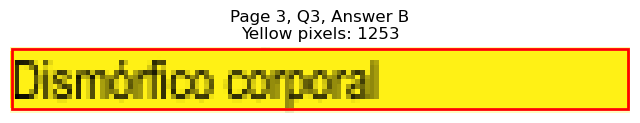

Page 3, Q3 - C: Detected box: x0=327.5, y0=304.0, x1=381.2, y1=316.7
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 282
Page 3, Q3, C: Yellow percentage: 0.0%


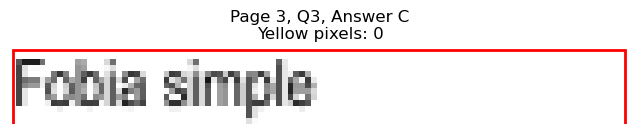

Page 3, Q3 - D: Detected box: x0=327.5, y0=316.6, x1=377.2, y1=329.3
Page 3, Q3, D: Yellow pixels: 0
Page 3, Q3, D: Total non-white pixels: 241
Page 3, Q3, D: Yellow percentage: 0.0%


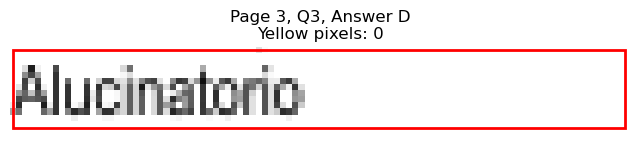


Page 3, Q3 - Selected Answer: B (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=367.1, x1=130.0, y1=379.8
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 424
Page 3, Q4, A: Yellow percentage: 0.0%


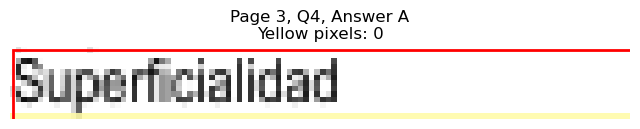

Page 3, Q4 - B: Detected box: x0=68.3, y0=379.7, x1=132.0, y1=392.4
Page 3, Q4, B: Yellow pixels: 1130
Page 3, Q4, B: Total non-white pixels: 1610
Page 3, Q4, B: Yellow percentage: 70.2%


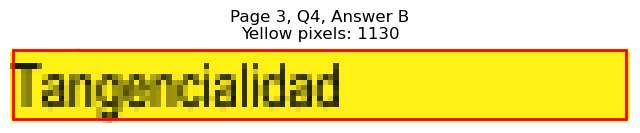

Page 3, Q4 - C: Detected box: x0=327.5, y0=367.1, x1=405.8, y1=379.8
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 397
Page 3, Q4, C: Yellow percentage: 0.0%


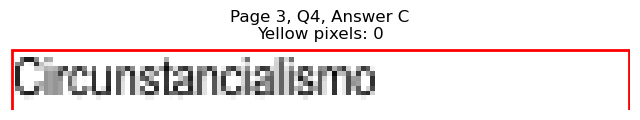

Page 3, Q4 - D: Detected box: x0=327.5, y0=379.7, x1=366.2, y1=392.4
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 178
Page 3, Q4, D: Yellow percentage: 0.0%


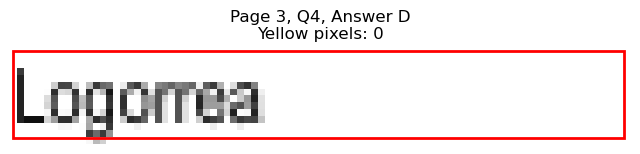


Page 3, Q4 - Selected Answer: B (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=118.0, y1=430.3
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 233
Page 3, Q5, A: Yellow percentage: 0.0%


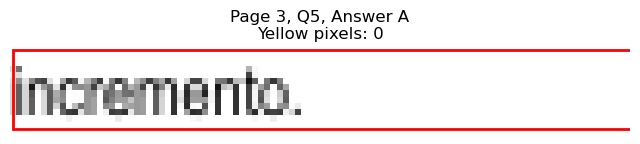

Page 3, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=130.0, y1=442.9
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 301
Page 3, Q5, B: Yellow percentage: 0.0%


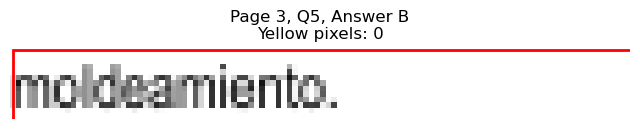

Page 3, Q5 - C: Detected box: x0=327.5, y0=417.6, x1=380.7, y1=430.3
Page 3, Q5, C: Yellow pixels: 104
Page 3, Q5, C: Total non-white pixels: 379
Page 3, Q5, C: Yellow percentage: 27.4%


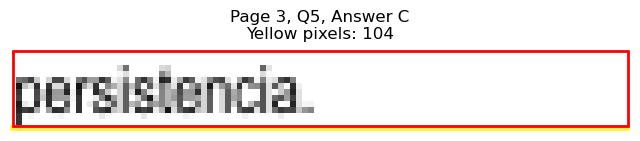

Page 3, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=375.2, y1=442.9
Page 3, Q5, D: Yellow pixels: 1108
Page 3, Q5, D: Total non-white pixels: 1287
Page 3, Q5, D: Yellow percentage: 86.1%


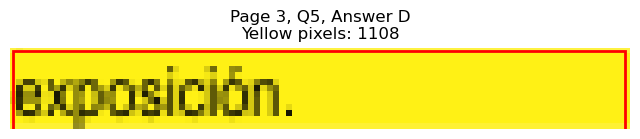


Page 3, Q5 - Selected Answer: D (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=506.0, x1=154.1, y1=518.6
Page 3, Q6, A: Yellow pixels: 137
Page 3, Q6, A: Total non-white pixels: 596
Page 3, Q6, A: Yellow percentage: 23.0%


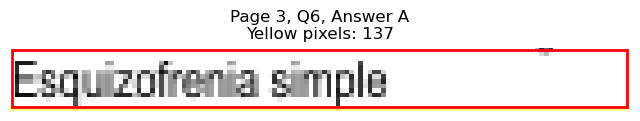

Page 3, Q6 - B: Detected box: x0=68.3, y0=518.6, x1=159.1, y1=531.2
Page 3, Q6, B: Yellow pixels: 1449
Page 3, Q6, B: Total non-white pixels: 1988
Page 3, Q6, B: Yellow percentage: 72.9%


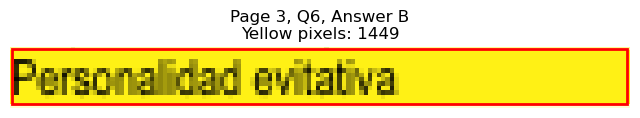

Page 3, Q6 - C: Detected box: x0=327.5, y0=506.0, x1=391.7, y1=518.6
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 323
Page 3, Q6, C: Yellow percentage: 0.0%


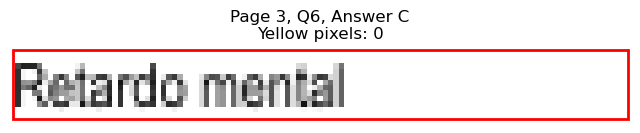

Page 3, Q6 - D: Detected box: x0=327.5, y0=518.6, x1=448.4, y1=531.2
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 616
Page 3, Q6, D: Yellow percentage: 0.0%


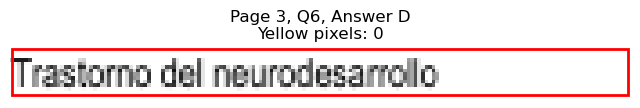


Page 3, Q6 - Selected Answer: B (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=113.9, y1=581.8
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 337
Page 3, Q7, A: Yellow percentage: 0.0%


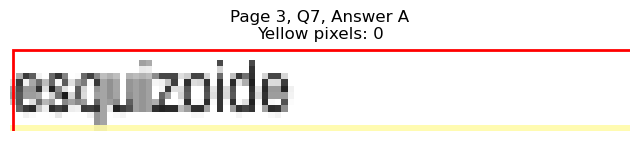

Page 3, Q7 - B: Detected box: x0=68.3, y0=581.7, x1=120.5, y1=594.4
Page 3, Q7, B: Yellow pixels: 1031
Page 3, Q7, B: Total non-white pixels: 1442
Page 3, Q7, B: Yellow percentage: 71.5%


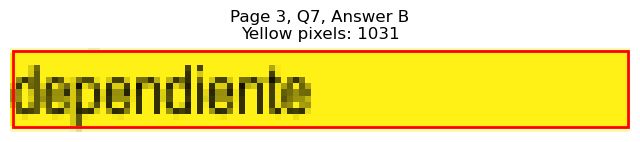

Page 3, Q7 - C: Detected box: x0=327.5, y0=569.1, x1=370.6, y1=581.8
Page 3, Q7, C: Yellow pixels: 0
Page 3, Q7, C: Total non-white pixels: 203
Page 3, Q7, C: Yellow percentage: 0.0%


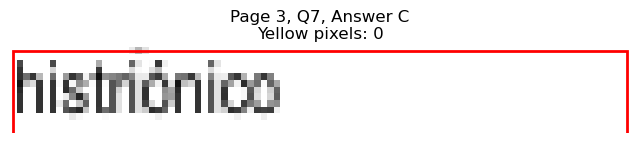

Page 3, Q7 - D: Detected box: x0=327.5, y0=581.7, x1=378.2, y1=594.4
Page 3, Q7, D: Yellow pixels: 0
Page 3, Q7, D: Total non-white pixels: 250
Page 3, Q7, D: Yellow percentage: 0.0%


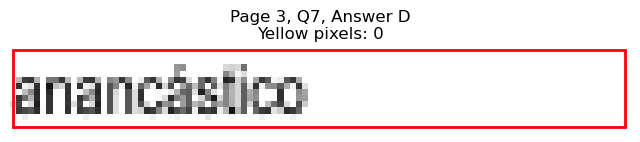


Page 3, Q7 - Selected Answer: B (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=68.3, y0=644.9, x1=116.4, y1=657.5
Page 3, Q8, A: Yellow pixels: 99
Page 3, Q8, A: Total non-white pixels: 352
Page 3, Q8, A: Yellow percentage: 28.1%


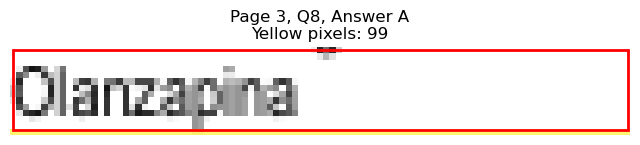

Page 3, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=118.0, y1=670.1
Page 3, Q8, B: Yellow pixels: 1111
Page 3, Q8, B: Total non-white pixels: 1400
Page 3, Q8, B: Yellow percentage: 79.4%


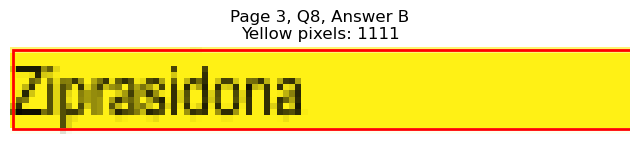

Page 3, Q8 - C: Detected box: x0=327.5, y0=644.9, x1=370.6, y1=657.5
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 225
Page 3, Q8, C: Yellow percentage: 0.0%


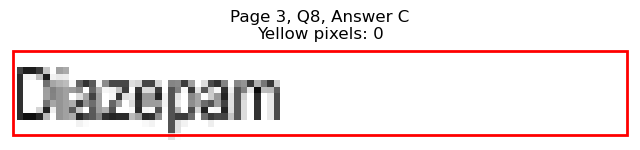

Page 3, Q8 - D: Detected box: x0=327.5, y0=657.5, x1=405.3, y1=670.1
Page 3, Q8, D: Yellow pixels: 0
Page 3, Q8, D: Total non-white pixels: 374
Page 3, Q8, D: Yellow percentage: 0.0%


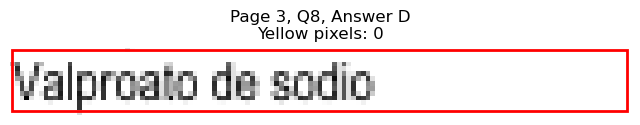


Page 3, Q8 - Selected Answer: B (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=130.5, y1=708.0
Page 3, Q9, A: Yellow pixels: 1241
Page 3, Q9, A: Total non-white pixels: 1469
Page 3, Q9, A: Yellow percentage: 84.5%


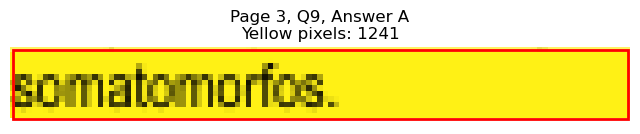

Page 3, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=109.9, y1=720.6
Page 3, Q9, B: Yellow pixels: 92
Page 3, Q9, B: Total non-white pixels: 301
Page 3, Q9, B: Yellow percentage: 30.6%


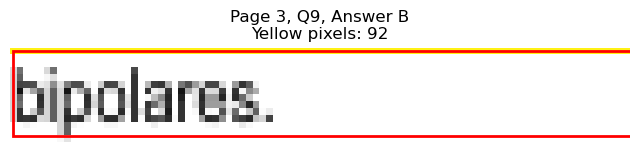

Page 3, Q9 - C: Detected box: x0=327.5, y0=695.4, x1=377.7, y1=708.0
Page 3, Q9, C: Yellow pixels: 0
Page 3, Q9, C: Total non-white pixels: 232
Page 3, Q9, C: Yellow percentage: 0.0%


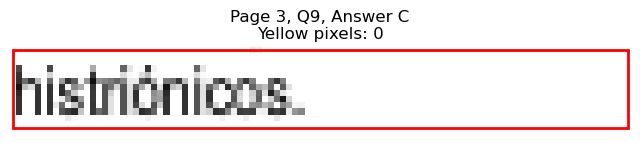

Page 3, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=373.7, y1=720.6
Page 3, Q9, D: Yellow pixels: 0
Page 3, Q9, D: Total non-white pixels: 233
Page 3, Q9, D: Yellow percentage: 0.0%


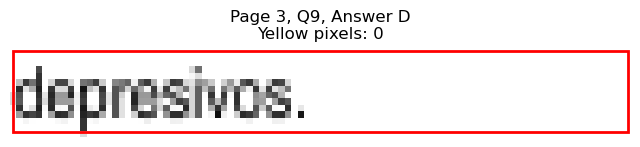


Page 3, Q9 - Selected Answer: A (based on yellow pixel count)





Page 4: Found 10 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=127.2, x1=153.6, y1=139.9
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 420
Page 4, Q1, A: Yellow percentage: 0.0%


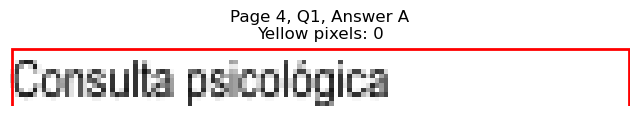

Page 4, Q1 - B: Detected box: x0=68.3, y0=139.9, x1=160.1, y1=152.6
Page 4, Q1, B: Yellow pixels: 0
Page 4, Q1, B: Total non-white pixels: 487
Page 4, Q1, B: Yellow percentage: 0.0%


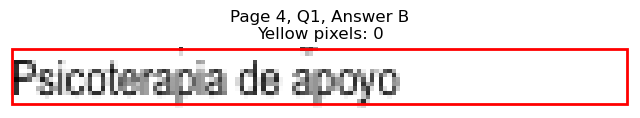

Page 4, Q1 - C: Detected box: x0=327.5, y0=127.2, x1=390.8, y1=139.9
Page 4, Q1, C: Yellow pixels: 1219
Page 4, Q1, C: Total non-white pixels: 1482
Page 4, Q1, C: Yellow percentage: 82.3%


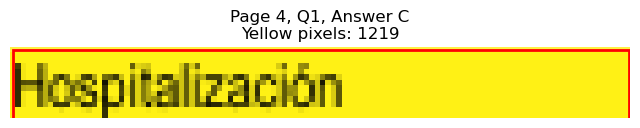

Page 4, Q1 - D: Detected box: x0=327.5, y0=139.9, x1=410.8, y1=152.6
Page 4, Q1, D: Yellow pixels: 133
Page 4, Q1, D: Total non-white pixels: 540
Page 4, Q1, D: Yellow percentage: 24.6%


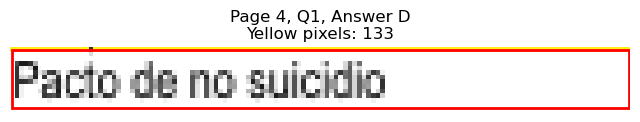


Page 4, Q1 - Selected Answer: C (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=100.5, y1=190.4
Page 4, Q2, A: Yellow pixels: 0
Page 4, Q2, A: Total non-white pixels: 165
Page 4, Q2, A: Yellow percentage: 0.0%


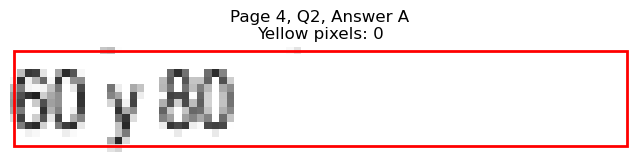

Page 4, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=100.5, y1=203.0
Page 4, Q2, B: Yellow pixels: 0
Page 4, Q2, B: Total non-white pixels: 159
Page 4, Q2, B: Yellow percentage: 0.0%


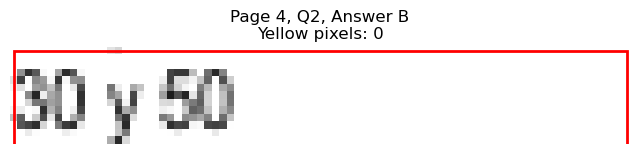

Page 4, Q2 - C: Detected box: x0=327.5, y0=177.7, x1=359.7, y1=190.4
Page 4, Q2, C: Yellow pixels: 898
Page 4, Q2, C: Total non-white pixels: 1162
Page 4, Q2, C: Yellow percentage: 77.3%


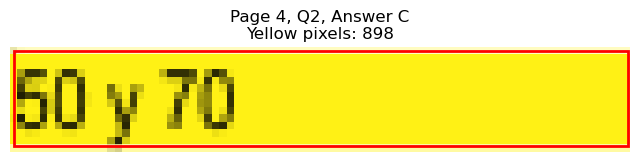

Page 4, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=359.7, y1=203.0
Page 4, Q2, D: Yellow pixels: 2
Page 4, Q2, D: Total non-white pixels: 228
Page 4, Q2, D: Yellow percentage: 0.9%


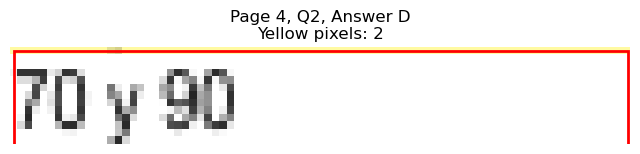


Page 4, Q2 - Selected Answer: C (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=133.5, y1=240.9
Page 4, Q3, A: Yellow pixels: 1246
Page 4, Q3, A: Total non-white pixels: 1508
Page 4, Q3, A: Yellow percentage: 82.6%


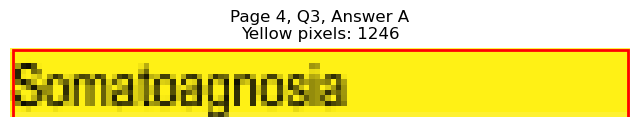

Page 4, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=105.9, y1=253.5
Page 4, Q3, B: Yellow pixels: 84
Page 4, Q3, B: Total non-white pixels: 274
Page 4, Q3, B: Yellow percentage: 30.7%


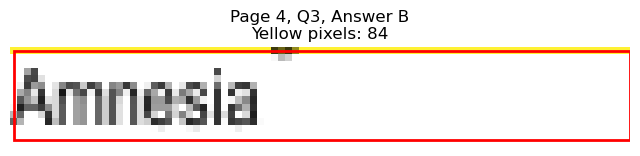

Page 4, Q3 - C: Detected box: x0=327.5, y0=228.3, x1=375.2, y1=240.9
Page 4, Q3, C: Yellow pixels: 0
Page 4, Q3, C: Total non-white pixels: 270
Page 4, Q3, C: Yellow percentage: 0.0%


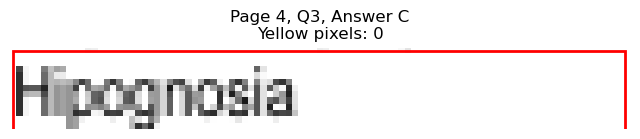

Page 4, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=388.7, y1=253.5
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 341
Page 4, Q3, D: Yellow percentage: 0.0%


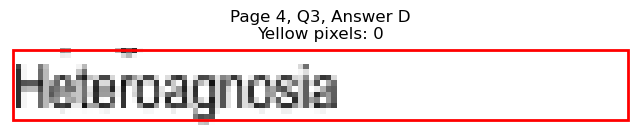


Page 4, Q3 - Selected Answer: A (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=133.0, y1=304.1
Page 4, Q4, A: Yellow pixels: 0
Page 4, Q4, A: Total non-white pixels: 319
Page 4, Q4, A: Yellow percentage: 0.0%


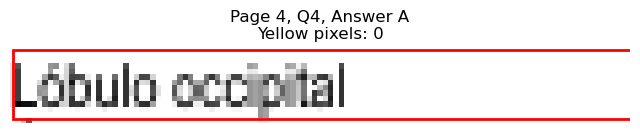

Page 4, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=128.5, y1=316.7
Page 4, Q4, B: Yellow pixels: 0
Page 4, Q4, B: Total non-white pixels: 293
Page 4, Q4, B: Yellow percentage: 0.0%


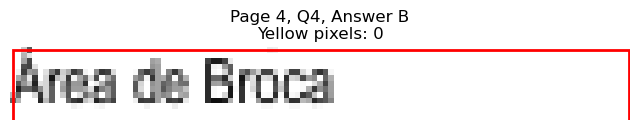

Page 4, Q4 - C: Detected box: x0=327.5, y0=291.4, x1=375.7, y1=304.1
Page 4, Q4, C: Yellow pixels: 1087
Page 4, Q4, C: Total non-white pixels: 1386
Page 4, Q4, C: Yellow percentage: 78.4%


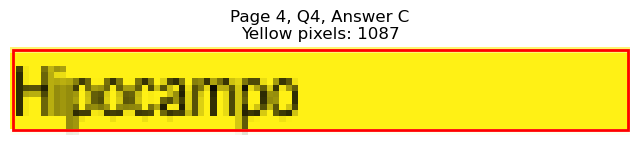

Page 4, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=401.2, y1=316.7
Page 4, Q4, D: Yellow pixels: 0
Page 4, Q4, D: Total non-white pixels: 493
Page 4, Q4, D: Yellow percentage: 0.0%


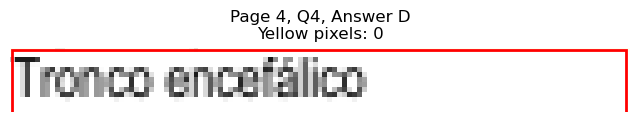


Page 4, Q4 - Selected Answer: C (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=341.9, x1=117.6, y1=354.6
Page 4, Q5, A: Yellow pixels: 100
Page 4, Q5, A: Total non-white pixels: 357
Page 4, Q5, A: Yellow percentage: 28.0%


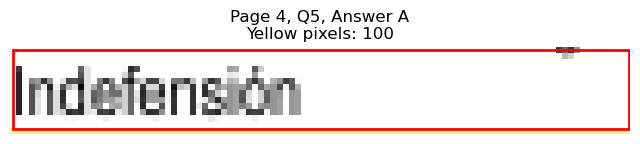

Page 4, Q5 - B: Detected box: x0=68.3, y0=354.5, x1=134.5, y1=367.2
Page 4, Q5, B: Yellow pixels: 1239
Page 4, Q5, B: Total non-white pixels: 1638
Page 4, Q5, B: Yellow percentage: 75.6%


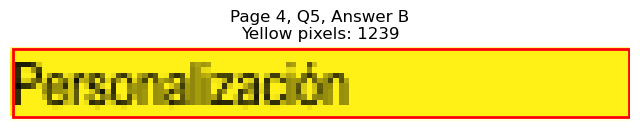

Page 4, Q5 - C: Detected box: x0=327.5, y0=341.9, x1=370.1, y1=354.6
Page 4, Q5, C: Yellow pixels: 0
Page 4, Q5, C: Total non-white pixels: 193
Page 4, Q5, C: Yellow percentage: 0.0%


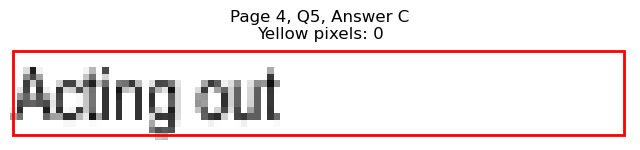

Page 4, Q5 - D: Detected box: x0=327.5, y0=354.5, x1=373.1, y1=367.2
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 220
Page 4, Q5, D: Yellow percentage: 0.0%


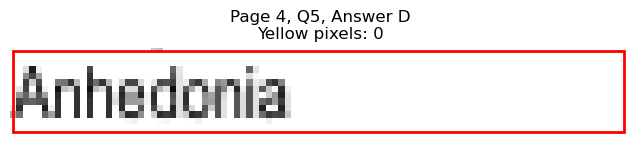


Page 4, Q5 - Selected Answer: B (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=109.5, y1=455.5
Page 4, Q6, A: Yellow pixels: 1028
Page 4, Q6, A: Total non-white pixels: 1288
Page 4, Q6, A: Yellow percentage: 79.8%


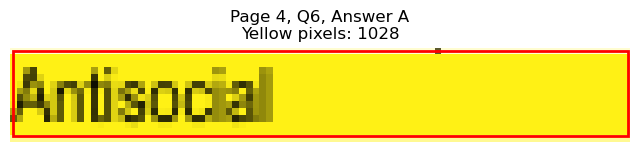

Page 4, Q6 - B: Detected box: x0=68.3, y0=455.5, x1=112.0, y1=468.1
Page 4, Q6, B: Yellow pixels: 0
Page 4, Q6, B: Total non-white pixels: 212
Page 4, Q6, B: Yellow percentage: 0.0%


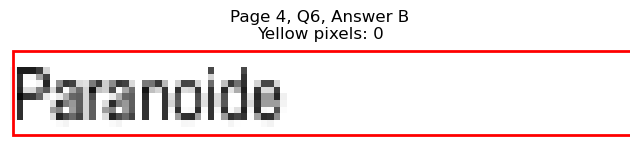

Page 4, Q6 - C: Detected box: x0=327.5, y0=442.8, x1=358.1, y1=455.5
Page 4, Q6, C: Yellow pixels: 0
Page 4, Q6, C: Total non-white pixels: 147
Page 4, Q6, C: Yellow percentage: 0.0%


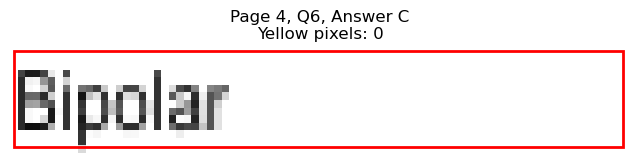

Page 4, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=366.7, y1=468.1
Page 4, Q6, D: Yellow pixels: 0
Page 4, Q6, D: Total non-white pixels: 217
Page 4, Q6, D: Yellow percentage: 0.0%


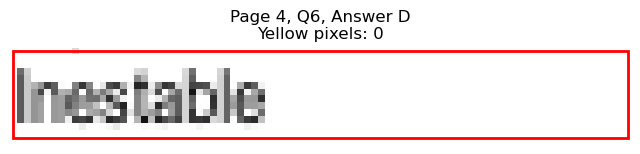


Page 4, Q6 - Selected Answer: A (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=518.6, x1=106.0, y1=531.2
Page 4, Q7, A: Yellow pixels: 0
Page 4, Q7, A: Total non-white pixels: 179
Page 4, Q7, A: Yellow percentage: 0.0%


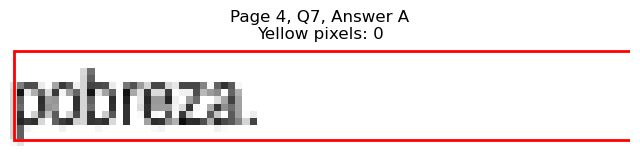

Page 4, Q7 - B: Detected box: x0=68.3, y0=531.2, x1=168.1, y1=543.8
Page 4, Q7, B: Yellow pixels: 0
Page 4, Q7, B: Total non-white pixels: 503
Page 4, Q7, B: Yellow percentage: 0.0%


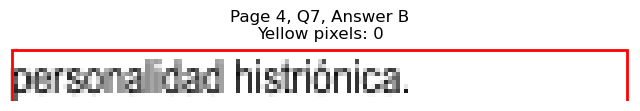

Page 4, Q7 - C: Detected box: x0=327.5, y0=518.6, x1=394.7, y1=531.2
Page 4, Q7, C: Yellow pixels: 118
Page 4, Q7, C: Total non-white pixels: 436
Page 4, Q7, C: Yellow percentage: 27.1%


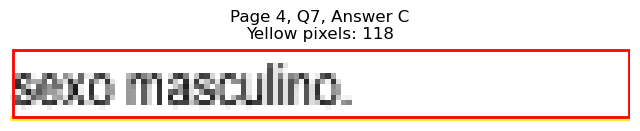

Page 4, Q7 - D: Detected box: x0=327.5, y0=531.2, x1=389.2, y1=543.8
Page 4, Q7, D: Yellow pixels: 1225
Page 4, Q7, D: Total non-white pixels: 1469
Page 4, Q7, D: Yellow percentage: 83.4%


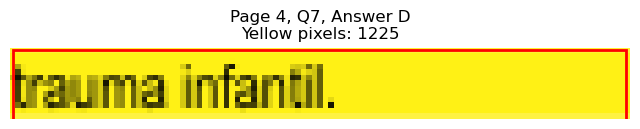


Page 4, Q7 - Selected Answer: D (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=68.3, y0=569.1, x1=143.5, y1=581.8
Page 4, Q8, A: Yellow pixels: 1363
Page 4, Q8, A: Total non-white pixels: 1638
Page 4, Q8, A: Yellow percentage: 83.2%


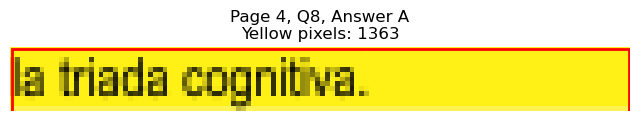

Page 4, Q8 - B: Detected box: x0=68.3, y0=581.7, x1=168.1, y1=594.4
Page 4, Q8, B: Yellow pixels: 149
Page 4, Q8, B: Total non-white pixels: 641
Page 4, Q8, B: Yellow percentage: 23.2%


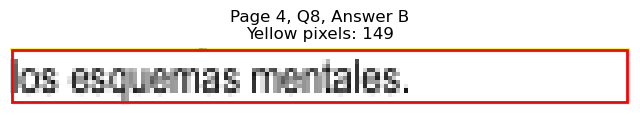

Page 4, Q8 - C: Detected box: x0=327.5, y0=569.1, x1=409.9, y1=581.8
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 385
Page 4, Q8, C: Yellow percentage: 0.0%


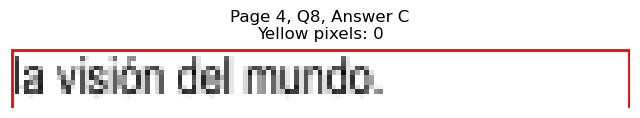

Page 4, Q8 - D: Detected box: x0=327.5, y0=581.7, x1=416.3, y1=594.4
Page 4, Q8, D: Yellow pixels: 0
Page 4, Q8, D: Total non-white pixels: 442
Page 4, Q8, D: Yellow percentage: 0.0%


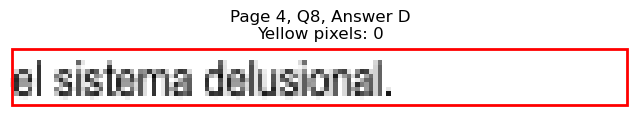


Page 4, Q8 - Selected Answer: A (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=68.3, y0=644.9, x1=113.4, y1=657.5
Page 4, Q9, A: Yellow pixels: 96
Page 4, Q9, A: Total non-white pixels: 327
Page 4, Q9, A: Yellow percentage: 29.4%


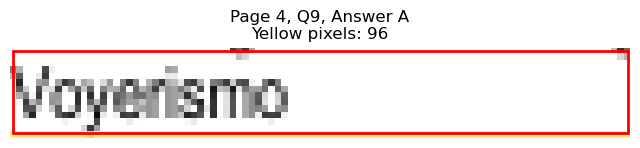

Page 4, Q9 - B: Detected box: x0=68.3, y0=657.5, x1=114.4, y1=670.1
Page 4, Q9, B: Yellow pixels: 1075
Page 4, Q9, B: Total non-white pixels: 1358
Page 4, Q9, B: Yellow percentage: 79.2%


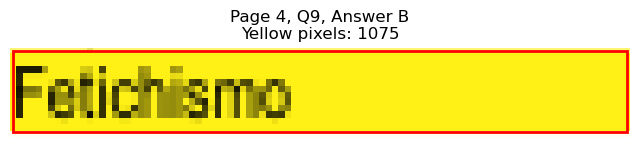

Page 4, Q9 - C: Detected box: x0=327.5, y0=644.9, x1=379.1, y1=657.5
Page 4, Q9, C: Yellow pixels: 0
Page 4, Q9, C: Total non-white pixels: 252
Page 4, Q9, C: Yellow percentage: 0.0%


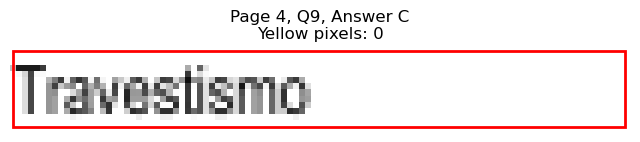

Page 4, Q9 - D: Detected box: x0=327.5, y0=657.5, x1=365.1, y1=670.1
Page 4, Q9, D: Yellow pixels: 0
Page 4, Q9, D: Total non-white pixels: 189
Page 4, Q9, D: Yellow percentage: 0.0%


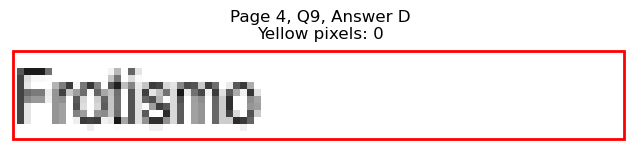


Page 4, Q9 - Selected Answer: B (based on yellow pixel count)




Page 4, Q10 - A: Detected box: x0=68.3, y0=733.2, x1=162.6, y1=745.8
Page 4, Q10, A: Yellow pixels: 1
Page 4, Q10, A: Total non-white pixels: 633
Page 4, Q10, A: Yellow percentage: 0.2%


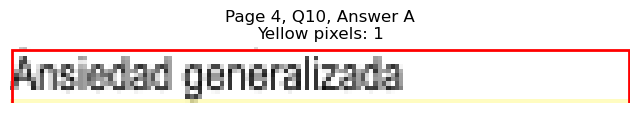

Page 4, Q10 - B: Detected box: x0=68.3, y0=745.8, x1=141.0, y1=758.4
Page 4, Q10, B: Yellow pixels: 1325
Page 4, Q10, B: Total non-white pixels: 1736
Page 4, Q10, B: Yellow percentage: 76.3%


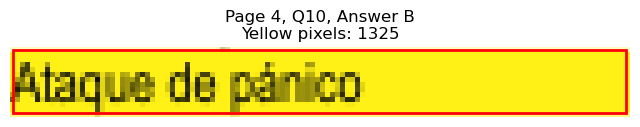

Page 4, Q10 - C: Detected box: x0=327.5, y0=733.2, x1=399.3, y1=745.8
Page 4, Q10, C: Yellow pixels: 0
Page 4, Q10, C: Total non-white pixels: 363
Page 4, Q10, C: Yellow percentage: 0.0%


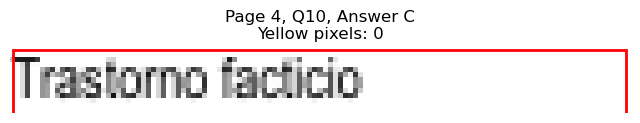

Page 4, Q10 - D: Detected box: x0=327.5, y0=745.8, x1=384.2, y1=758.4
Page 4, Q10, D: Yellow pixels: 0
Page 4, Q10, D: Total non-white pixels: 290
Page 4, Q10, D: Yellow percentage: 0.0%


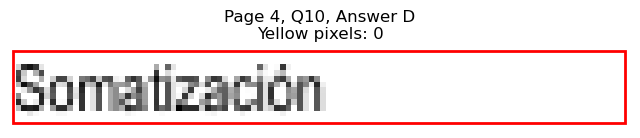


Page 4, Q10 - Selected Answer: B (based on yellow pixel count)





Page 5: Found 10 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=122.4, y1=102.1
Page 5, Q1, A: Yellow pixels: 0
Page 5, Q1, A: Total non-white pixels: 268
Page 5, Q1, A: Yellow percentage: 0.0%


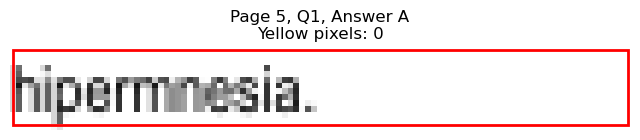

Page 5, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=127.5, y1=114.7
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 302
Page 5, Q1, B: Yellow percentage: 0.0%


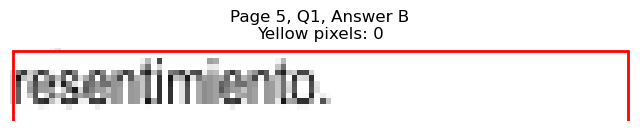

Page 5, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=362.7, y1=102.1
Page 5, Q1, C: Yellow pixels: 86
Page 5, Q1, C: Total non-white pixels: 259
Page 5, Q1, C: Yellow percentage: 33.2%


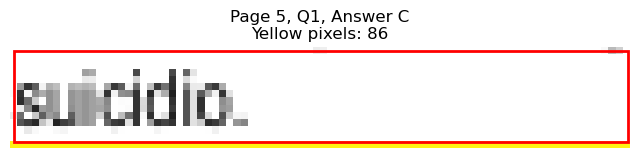

Page 5, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=382.3, y1=114.7
Page 5, Q1, D: Yellow pixels: 1167
Page 5, Q1, D: Total non-white pixels: 1378
Page 5, Q1, D: Yellow percentage: 84.7%


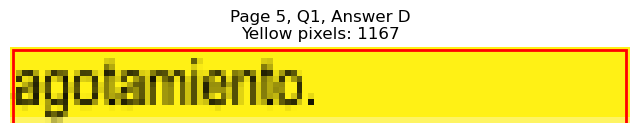


Page 5, Q1 - Selected Answer: D (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=107.4, y1=165.2
Page 5, Q2, A: Yellow pixels: 0
Page 5, Q2, A: Total non-white pixels: 224
Page 5, Q2, A: Yellow percentage: 0.0%


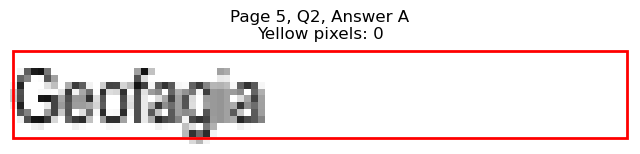

Page 5, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=112.9, y1=177.8
Page 5, Q2, B: Yellow pixels: 0
Page 5, Q2, B: Total non-white pixels: 242
Page 5, Q2, B: Yellow percentage: 0.0%


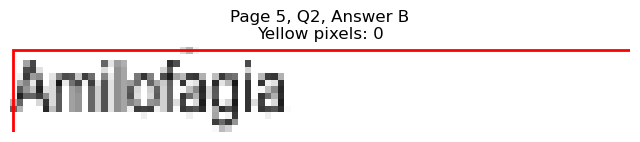

Page 5, Q2 - C: Detected box: x0=327.5, y0=152.5, x1=390.2, y1=165.2
Page 5, Q2, C: Yellow pixels: 114
Page 5, Q2, C: Total non-white pixels: 445
Page 5, Q2, C: Yellow percentage: 25.6%


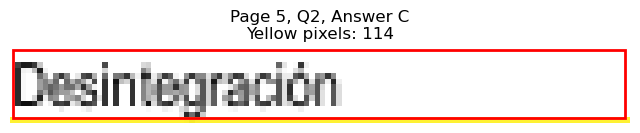

Page 5, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=347.6, y1=177.8
Page 5, Q2, D: Yellow pixels: 855
Page 5, Q2, D: Total non-white pixels: 923
Page 5, Q2, D: Yellow percentage: 92.6%


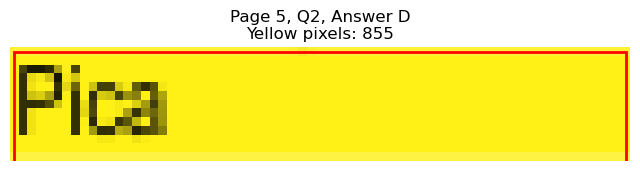


Page 5, Q2 - Selected Answer: D (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=109.5, y1=253.5
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 231
Page 5, Q3, A: Yellow percentage: 0.0%


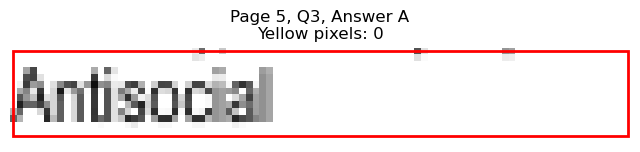

Page 5, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=112.0, y1=266.1
Page 5, Q3, B: Yellow pixels: 0
Page 5, Q3, B: Total non-white pixels: 212
Page 5, Q3, B: Yellow percentage: 0.0%


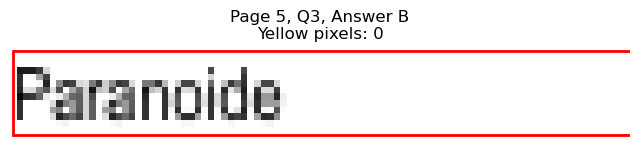

Page 5, Q3 - C: Detected box: x0=327.5, y0=240.9, x1=364.1, y1=253.5
Page 5, Q3, C: Yellow pixels: 88
Page 5, Q3, C: Total non-white pixels: 280
Page 5, Q3, C: Yellow percentage: 31.4%


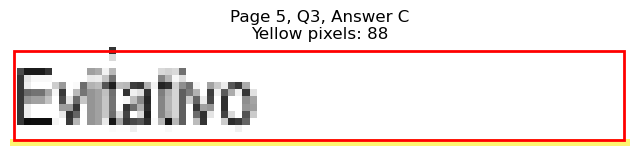

Page 5, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=354.7, y1=266.1
Page 5, Q3, D: Yellow pixels: 910
Page 5, Q3, D: Total non-white pixels: 1092
Page 5, Q3, D: Yellow percentage: 83.3%


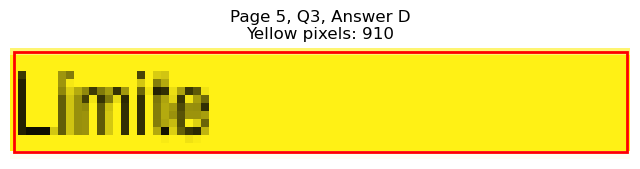


Page 5, Q3 - Selected Answer: D (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=129.5, y1=304.1
Page 5, Q4, A: Yellow pixels: 0
Page 5, Q4, A: Total non-white pixels: 314
Page 5, Q4, A: Yellow percentage: 0.0%


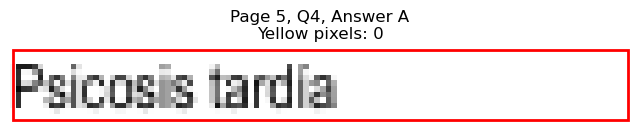

Page 5, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=96.4, y1=316.7
Page 5, Q4, B: Yellow pixels: 0
Page 5, Q4, B: Total non-white pixels: 154
Page 5, Q4, B: Yellow percentage: 0.0%


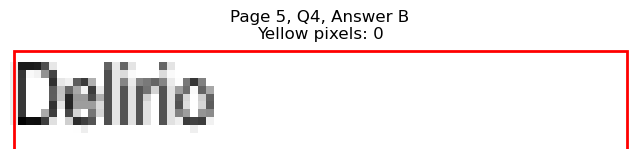

Page 5, Q4 - C: Detected box: x0=327.5, y0=291.4, x1=400.3, y1=304.1
Page 5, Q4, C: Yellow pixels: 124
Page 5, Q4, C: Total non-white pixels: 509
Page 5, Q4, C: Yellow percentage: 24.4%


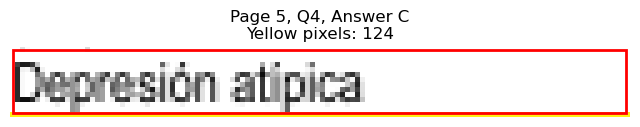

Page 5, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=371.7, y1=316.7
Page 5, Q4, D: Yellow pixels: 1065
Page 5, Q4, D: Total non-white pixels: 1235
Page 5, Q4, D: Yellow percentage: 86.2%


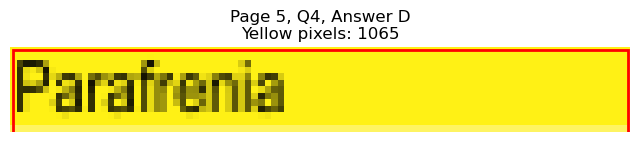


Page 5, Q4 - Selected Answer: D (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=354.5, x1=150.5, y1=367.2
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 399
Page 5, Q5, A: Yellow percentage: 0.0%


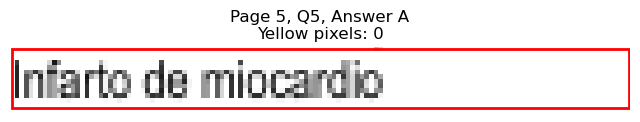

Page 5, Q5 - B: Detected box: x0=68.3, y0=367.1, x1=109.0, y1=379.8
Page 5, Q5, B: Yellow pixels: 0
Page 5, Q5, B: Total non-white pixels: 197
Page 5, Q5, B: Yellow percentage: 0.0%


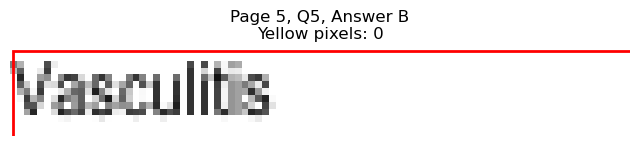

Page 5, Q5 - C: Detected box: x0=327.5, y0=354.5, x1=386.2, y1=367.2
Page 5, Q5, C: Yellow pixels: 1184
Page 5, Q5, C: Total non-white pixels: 1540
Page 5, Q5, C: Yellow percentage: 76.9%


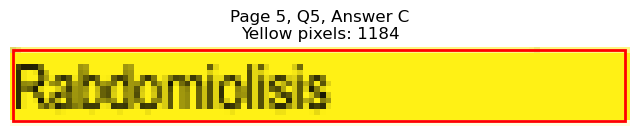

Page 5, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=394.3, y1=379.8
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 483
Page 5, Q5, D: Yellow percentage: 0.0%


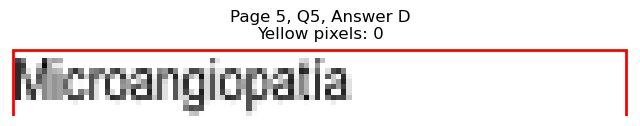


Page 5, Q5 - Selected Answer: C (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=134.1, y1=455.5
Page 5, Q6, A: Yellow pixels: 1251
Page 5, Q6, A: Total non-white pixels: 1638
Page 5, Q6, A: Yellow percentage: 76.4%


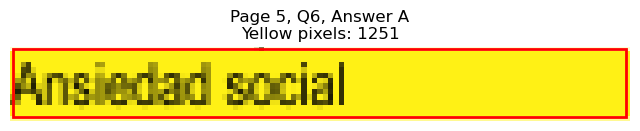

Page 5, Q6 - B: Detected box: x0=68.3, y0=455.5, x1=175.7, y1=468.1
Page 5, Q6, B: Yellow pixels: 0
Page 5, Q6, B: Total non-white pixels: 572
Page 5, Q6, B: Yellow percentage: 0.0%


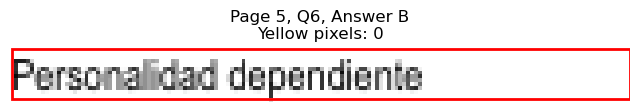

Page 5, Q6 - C: Detected box: x0=327.5, y0=442.8, x1=362.1, y1=455.5
Page 5, Q6, C: Yellow pixels: 0
Page 5, Q6, C: Total non-white pixels: 186
Page 5, Q6, C: Yellow percentage: 0.0%


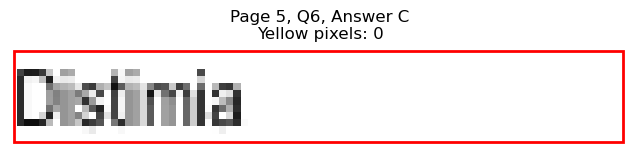

Page 5, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=414.3, y1=468.1
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 454
Page 5, Q6, D: Yellow percentage: 0.0%


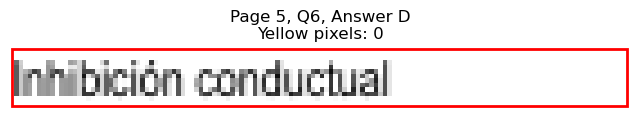


Page 5, Q6 - Selected Answer: A (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=171.1, y1=543.8
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 530
Page 5, Q7, A: Yellow percentage: 0.0%


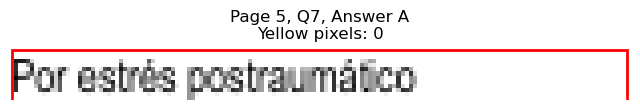

Page 5, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=129.0, y1=556.4
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 304
Page 5, Q7, B: Yellow percentage: 0.0%


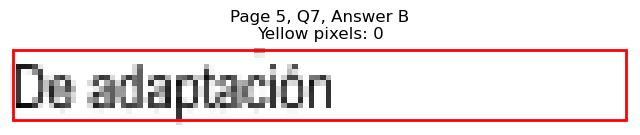

Page 5, Q7 - C: Detected box: x0=327.5, y0=531.2, x1=380.7, y1=543.8
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 369
Page 5, Q7, C: Yellow percentage: 0.0%


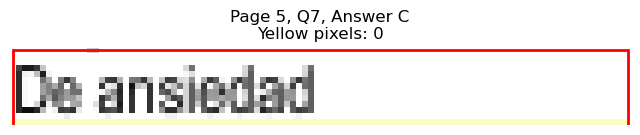

Page 5, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=398.8, y1=556.4
Page 5, Q7, D: Yellow pixels: 1303
Page 5, Q7, D: Total non-white pixels: 1708
Page 5, Q7, D: Yellow percentage: 76.3%


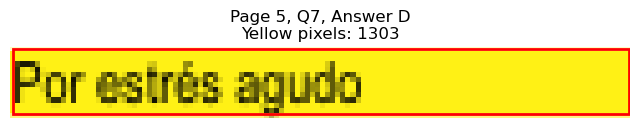


Page 5, Q7 - Selected Answer: D (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=581.7, x1=112.0, y1=594.4
Page 5, Q8, A: Yellow pixels: 94
Page 5, Q8, A: Total non-white pixels: 307
Page 5, Q8, A: Yellow percentage: 30.6%


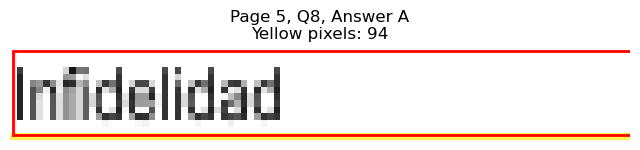

Page 5, Q8 - B: Detected box: x0=68.3, y0=594.3, x1=103.5, y1=607.0
Page 5, Q8, B: Yellow pixels: 975
Page 5, Q8, B: Total non-white pixels: 1118
Page 5, Q8, B: Yellow percentage: 87.2%


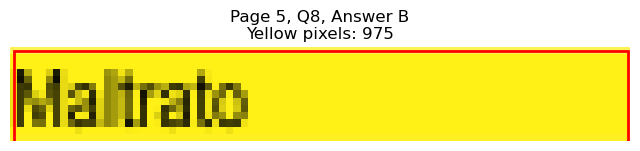

Page 5, Q8 - C: Detected box: x0=327.5, y0=581.7, x1=384.8, y1=594.4
Page 5, Q8, C: Yellow pixels: 0
Page 5, Q8, C: Total non-white pixels: 318
Page 5, Q8, C: Yellow percentage: 0.0%


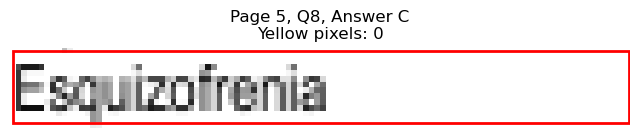

Page 5, Q8 - D: Detected box: x0=327.5, y0=594.3, x1=375.7, y1=607.0
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 248
Page 5, Q8, D: Yellow percentage: 0.0%


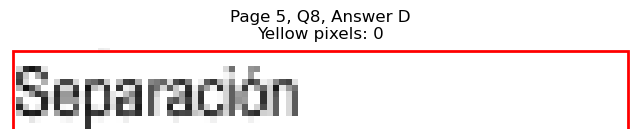


Page 5, Q8 - Selected Answer: B (based on yellow pixel count)




Page 5, Q9 - A: Detected box: x0=68.3, y0=632.2, x1=83.4, y1=644.9
Page 5, Q9, A: Yellow pixels: 0
Page 5, Q9, A: Total non-white pixels: 68
Page 5, Q9, A: Yellow percentage: 0.0%


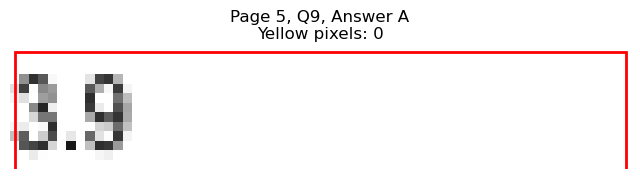

Page 5, Q9 - B: Detected box: x0=68.3, y0=644.9, x1=83.4, y1=657.5
Page 5, Q9, B: Yellow pixels: 0
Page 5, Q9, B: Total non-white pixels: 67
Page 5, Q9, B: Yellow percentage: 0.0%


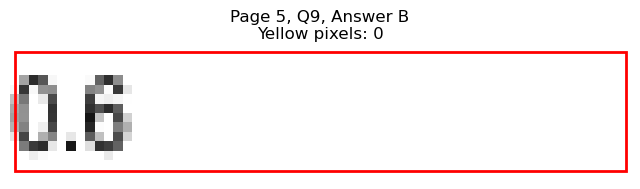

Page 5, Q9 - C: Detected box: x0=327.5, y0=632.2, x1=342.7, y1=644.9
Page 5, Q9, C: Yellow pixels: 0
Page 5, Q9, C: Total non-white pixels: 129
Page 5, Q9, C: Yellow percentage: 0.0%


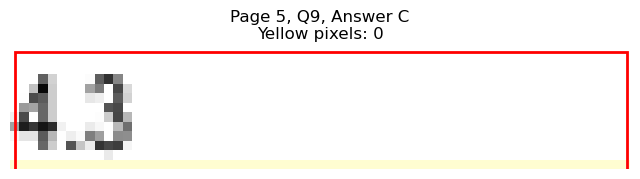

Page 5, Q9 - D: Detected box: x0=327.5, y0=644.9, x1=342.7, y1=657.5
Page 5, Q9, D: Yellow pixels: 822
Page 5, Q9, D: Total non-white pixels: 924
Page 5, Q9, D: Yellow percentage: 89.0%


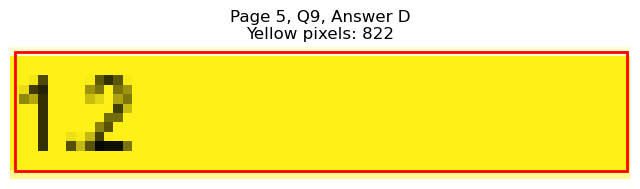


Page 5, Q9 - Selected Answer: D (based on yellow pixel count)




Page 5, Q10 - A: Detected box: x0=68.3, y0=720.6, x1=113.9, y1=733.2
Page 5, Q10, A: Yellow pixels: 0
Page 5, Q10, A: Total non-white pixels: 246
Page 5, Q10, A: Yellow percentage: 0.0%


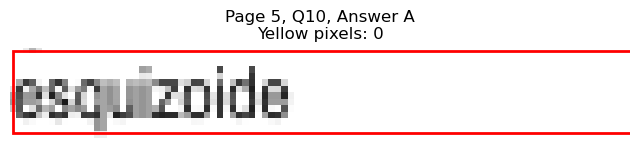

Page 5, Q10 - B: Detected box: x0=68.3, y0=733.2, x1=103.9, y1=745.8
Page 5, Q10, B: Yellow pixels: 0
Page 5, Q10, B: Total non-white pixels: 184
Page 5, Q10, B: Yellow percentage: 0.0%


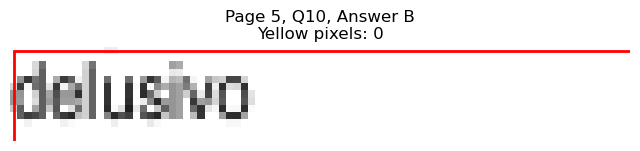

Page 5, Q10 - C: Detected box: x0=327.5, y0=720.6, x1=370.1, y1=733.2
Page 5, Q10, C: Yellow pixels: 1074
Page 5, Q10, C: Total non-white pixels: 1316
Page 5, Q10, C: Yellow percentage: 81.6%


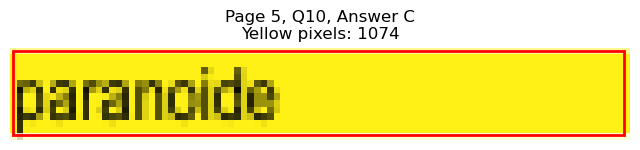

Page 5, Q10 - D: Detected box: x0=327.5, y0=733.2, x1=375.2, y1=745.8
Page 5, Q10, D: Yellow pixels: 0
Page 5, Q10, D: Total non-white pixels: 356
Page 5, Q10, D: Yellow percentage: 0.0%


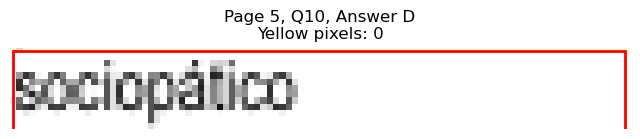


Page 5, Q10 - Selected Answer: C (based on yellow pixel count)





Page 6: Found 10 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=106.9, y1=102.1
Page 6, Q1, A: Yellow pixels: 89
Page 6, Q1, A: Total non-white pixels: 322
Page 6, Q1, A: Yellow percentage: 27.6%


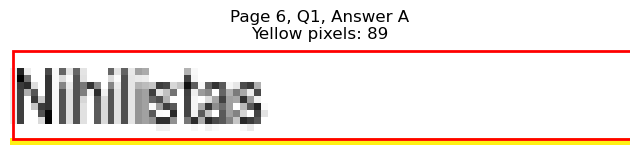

Page 6, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=124.9, y1=114.7
Page 6, Q1, B: Yellow pixels: 1166
Page 6, Q1, B: Total non-white pixels: 1391
Page 6, Q1, B: Yellow percentage: 83.8%


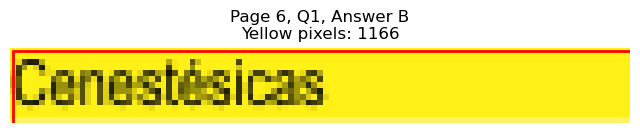

Page 6, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=365.1, y1=102.1
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 199
Page 6, Q1, C: Yellow percentage: 0.0%


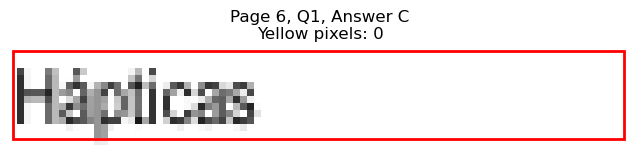

Page 6, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=361.1, y1=114.7
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 181
Page 6, Q1, D: Yellow percentage: 0.0%


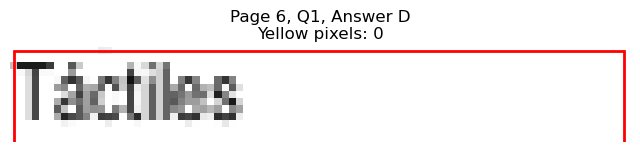


Page 6, Q1 - Selected Answer: B (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=101.4, y1=190.4
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 183
Page 6, Q2, A: Yellow percentage: 0.0%


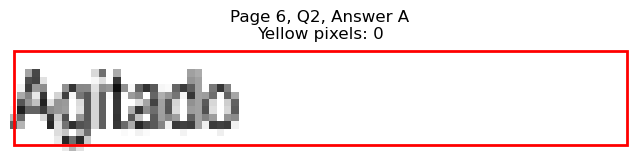

Page 6, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=143.5, y1=203.0
Page 6, Q2, B: Yellow pixels: 0
Page 6, Q2, B: Total non-white pixels: 405
Page 6, Q2, B: Yellow percentage: 0.0%


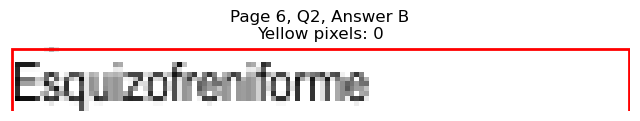

Page 6, Q2 - C: Detected box: x0=327.5, y0=177.7, x1=366.2, y1=190.4
Page 6, Q2, C: Yellow pixels: 907
Page 6, Q2, C: Total non-white pixels: 1260
Page 6, Q2, C: Yellow percentage: 72.0%


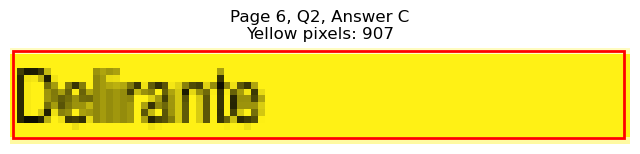

Page 6, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=367.6, y1=203.0
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 290
Page 6, Q2, D: Yellow percentage: 0.0%


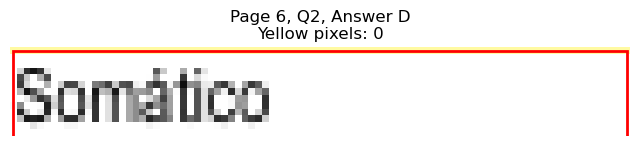


Page 6, Q2 - Selected Answer: C (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=143.1, y1=266.1
Page 6, Q3, A: Yellow pixels: 1356
Page 6, Q3, A: Total non-white pixels: 1764
Page 6, Q3, A: Yellow percentage: 76.9%


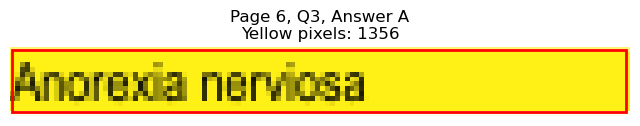

Page 6, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=111.4, y1=278.7
Page 6, Q3, B: Yellow pixels: 0
Page 6, Q3, B: Total non-white pixels: 301
Page 6, Q3, B: Yellow percentage: 0.0%


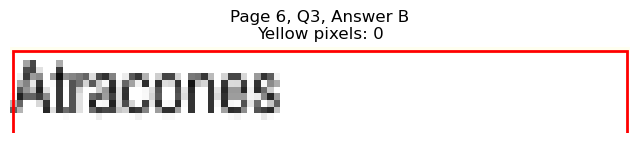

Page 6, Q3 - C: Detected box: x0=327.5, y0=253.5, x1=401.8, y1=266.1
Page 6, Q3, C: Yellow pixels: 0
Page 6, Q3, C: Total non-white pixels: 388
Page 6, Q3, C: Yellow percentage: 0.0%


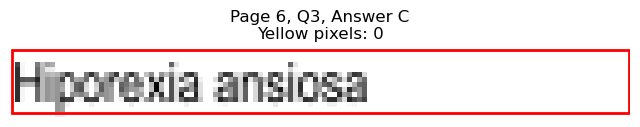

Page 6, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=385.7, y1=278.7
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 308
Page 6, Q3, D: Yellow percentage: 0.0%


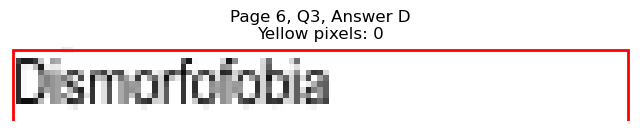


Page 6, Q3 - Selected Answer: A (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=126.5, y1=316.7
Page 6, Q4, A: Yellow pixels: 1185
Page 6, Q4, A: Total non-white pixels: 1417
Page 6, Q4, A: Yellow percentage: 83.6%


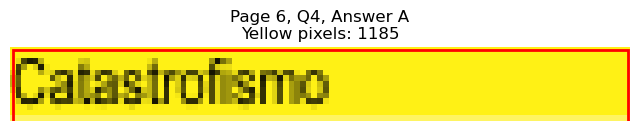

Page 6, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=133.5, y1=329.3
Page 6, Q4, B: Yellow pixels: 116
Page 6, Q4, B: Total non-white pixels: 485
Page 6, Q4, B: Yellow percentage: 23.9%


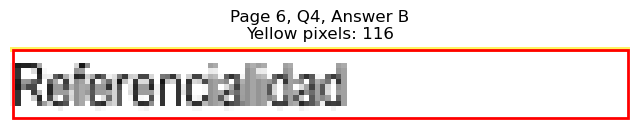

Page 6, Q4 - C: Detected box: x0=327.5, y0=304.0, x1=390.2, y1=316.7
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 335
Page 6, Q4, C: Yellow percentage: 0.0%


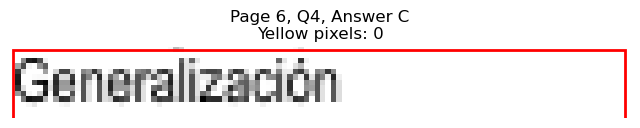

Page 6, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=391.3, y1=329.3
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 339
Page 6, Q4, D: Yellow percentage: 0.0%


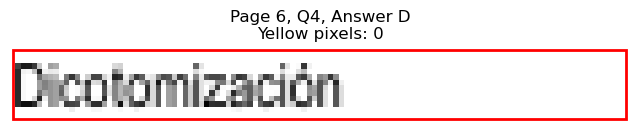


Page 6, Q4 - Selected Answer: A (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=101.4, y1=392.4
Page 6, Q5, A: Yellow pixels: 885
Page 6, Q5, A: Total non-white pixels: 1176
Page 6, Q5, A: Yellow percentage: 75.3%


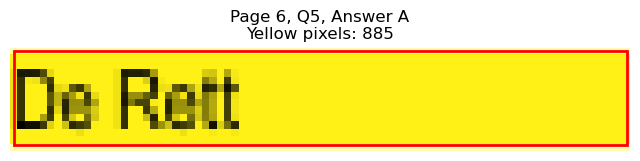

Page 6, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=107.4, y1=405.0
Page 6, Q5, B: Yellow pixels: 0
Page 6, Q5, B: Total non-white pixels: 296
Page 6, Q5, B: Yellow percentage: 0.0%


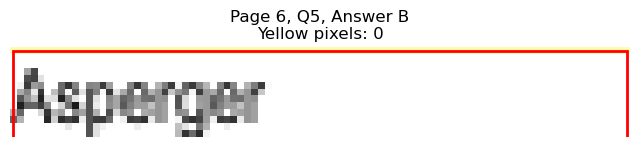

Page 6, Q5 - C: Detected box: x0=327.5, y0=379.7, x1=391.7, y1=392.4
Page 6, Q5, C: Yellow pixels: 0
Page 6, Q5, C: Total non-white pixels: 323
Page 6, Q5, C: Yellow percentage: 0.0%


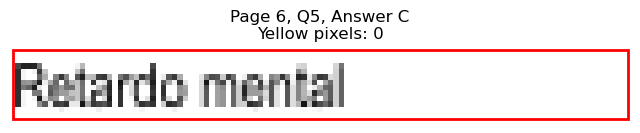

Page 6, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=356.6, y1=405.0
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 134
Page 6, Q5, D: Yellow percentage: 0.0%


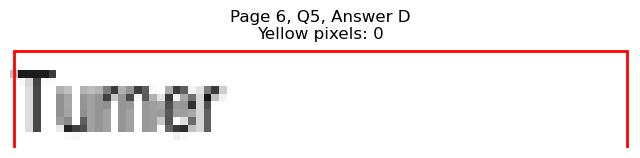


Page 6, Q5 - Selected Answer: A (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=117.4, y1=480.7
Page 6, Q6, A: Yellow pixels: 0
Page 6, Q6, A: Total non-white pixels: 267
Page 6, Q6, A: Yellow percentage: 0.0%


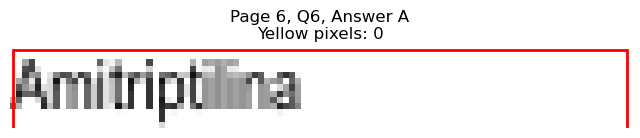

Page 6, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=116.4, y1=493.4
Page 6, Q6, B: Yellow pixels: 0
Page 6, Q6, B: Total non-white pixels: 270
Page 6, Q6, B: Yellow percentage: 0.0%


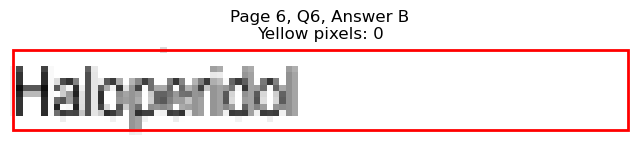

Page 6, Q6 - C: Detected box: x0=327.5, y0=468.1, x1=381.2, y1=480.7
Page 6, Q6, C: Yellow pixels: 1163
Page 6, Q6, C: Total non-white pixels: 1365
Page 6, Q6, C: Yellow percentage: 85.2%


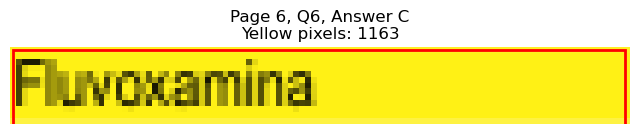

Page 6, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=393.8, y1=493.4
Page 6, Q6, D: Yellow pixels: 117
Page 6, Q6, D: Total non-white pixels: 469
Page 6, Q6, D: Yellow percentage: 24.9%


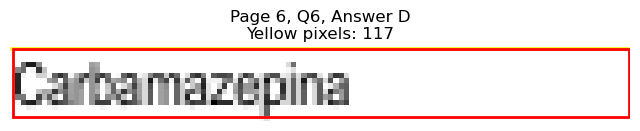


Page 6, Q6 - Selected Answer: C (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=518.6, x1=95.9, y1=531.2
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 147
Page 6, Q7, A: Yellow percentage: 0.0%


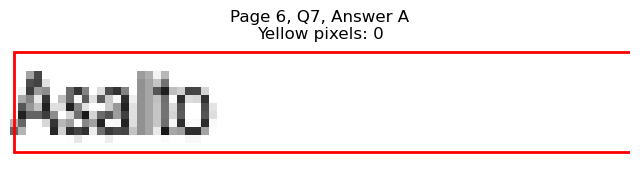

Page 6, Q7 - B: Detected box: x0=68.3, y0=531.2, x1=106.5, y1=543.8
Page 6, Q7, B: Yellow pixels: 0
Page 6, Q7, B: Total non-white pixels: 212
Page 6, Q7, B: Yellow percentage: 0.0%


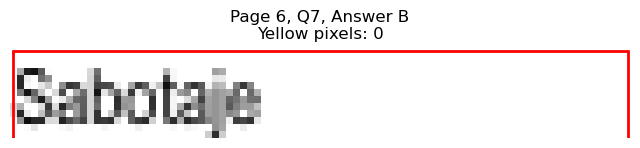

Page 6, Q7 - C: Detected box: x0=327.5, y0=518.6, x1=374.2, y1=531.2
Page 6, Q7, C: Yellow pixels: 98
Page 6, Q7, C: Total non-white pixels: 326
Page 6, Q7, C: Yellow percentage: 30.1%


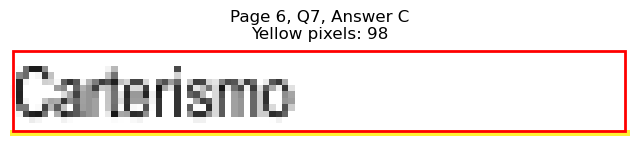

Page 6, Q7 - D: Detected box: x0=327.5, y0=531.2, x1=365.1, y1=543.8
Page 6, Q7, D: Yellow pixels: 999
Page 6, Q7, D: Total non-white pixels: 1157
Page 6, Q7, D: Yellow percentage: 86.3%


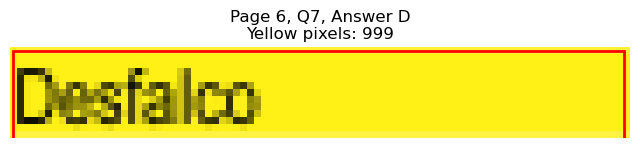


Page 6, Q7 - Selected Answer: D (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=569.1, x1=161.1, y1=581.8
Page 6, Q8, A: Yellow pixels: 1506
Page 6, Q8, A: Total non-white pixels: 1872
Page 6, Q8, A: Yellow percentage: 80.4%


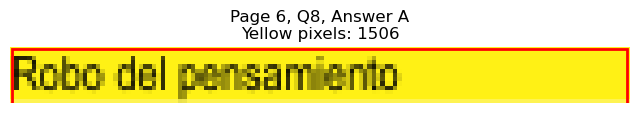

Page 6, Q8 - B: Detected box: x0=68.3, y0=581.7, x1=145.0, y1=594.4
Page 6, Q8, B: Yellow pixels: 127
Page 6, Q8, B: Total non-white pixels: 468
Page 6, Q8, B: Yellow percentage: 27.1%


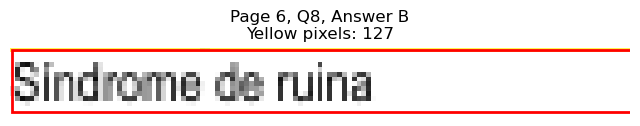

Page 6, Q8 - C: Detected box: x0=327.5, y0=569.1, x1=411.3, y1=581.8
Page 6, Q8, C: Yellow pixels: 0
Page 6, Q8, C: Total non-white pixels: 427
Page 6, Q8, C: Yellow percentage: 0.0%


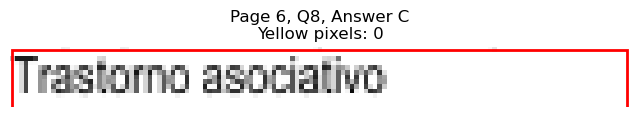

Page 6, Q8 - D: Detected box: x0=327.5, y0=581.7, x1=416.3, y1=594.4
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 469
Page 6, Q8, D: Yellow percentage: 0.0%


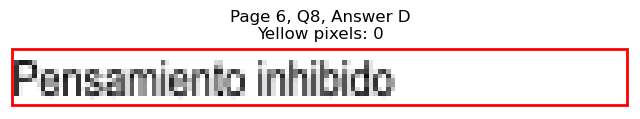


Page 6, Q8 - Selected Answer: A (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=68.3, y0=619.6, x1=131.5, y1=632.3
Page 6, Q9, A: Yellow pixels: 1141
Page 6, Q9, A: Total non-white pixels: 1596
Page 6, Q9, A: Yellow percentage: 71.5%


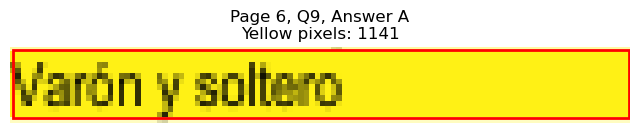

Page 6, Q9 - B: Detected box: x0=68.3, y0=632.2, x1=153.0, y1=644.9
Page 6, Q9, B: Yellow pixels: 0
Page 6, Q9, B: Total non-white pixels: 549
Page 6, Q9, B: Yellow percentage: 0.0%


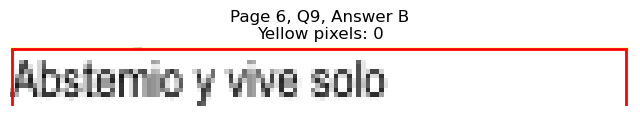

Page 6, Q9 - C: Detected box: x0=327.5, y0=619.6, x1=403.3, y1=632.3
Page 6, Q9, C: Yellow pixels: 0
Page 6, Q9, C: Total non-white pixels: 384
Page 6, Q9, C: Yellow percentage: 0.0%


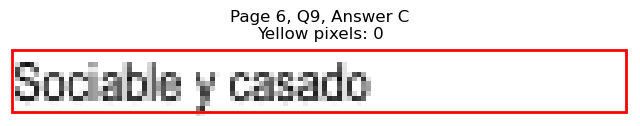

Page 6, Q9 - D: Detected box: x0=327.5, y0=632.2, x1=414.8, y1=644.9
Page 6, Q9, D: Yellow pixels: 0
Page 6, Q9, D: Total non-white pixels: 433
Page 6, Q9, D: Yellow percentage: 0.0%


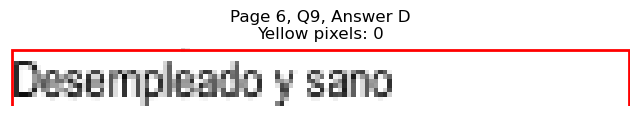


Page 6, Q9 - Selected Answer: A (based on yellow pixel count)




Page 6, Q10 - A: Detected box: x0=68.3, y0=708.0, x1=194.8, y1=720.6
Page 6, Q10, A: Yellow pixels: 0
Page 6, Q10, A: Total non-white pixels: 636
Page 6, Q10, A: Yellow percentage: 0.0%


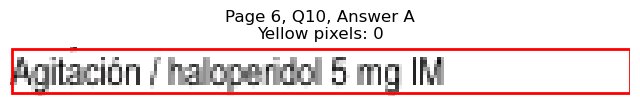

Page 6, Q10 - B: Detected box: x0=68.3, y0=720.6, x1=244.4, y1=733.2
Page 6, Q10, B: Yellow pixels: 0
Page 6, Q10, B: Total non-white pixels: 832
Page 6, Q10, B: Yellow percentage: 0.0%


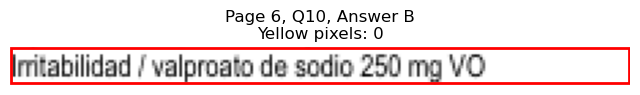

Page 6, Q10 - C: Detected box: x0=327.5, y0=708.0, x1=463.5, y1=720.6
Page 6, Q10, C: Yellow pixels: 1926
Page 6, Q10, C: Total non-white pixels: 2618
Page 6, Q10, C: Yellow percentage: 73.6%


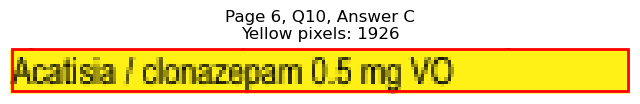

Page 6, Q10 - D: Detected box: x0=327.5, y0=720.6, x1=446.4, y1=733.2
Page 6, Q10, D: Yellow pixels: 169
Page 6, Q10, D: Total non-white pixels: 766
Page 6, Q10, D: Yellow percentage: 22.1%


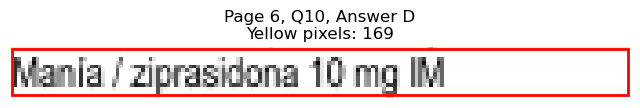


Page 6, Q10 - Selected Answer: C (based on yellow pixel count)





Page 7: Found 11 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=181.6, y1=102.1
Page 7, Q1, A: Yellow pixels: 1746
Page 7, Q1, A: Total non-white pixels: 2296
Page 7, Q1, A: Yellow percentage: 76.0%


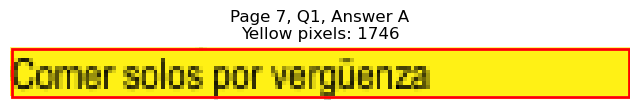

Page 7, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=189.1, y1=114.7
Page 7, Q1, B: Yellow pixels: 0
Page 7, Q1, B: Total non-white pixels: 773
Page 7, Q1, B: Yellow percentage: 0.0%


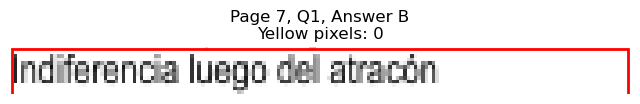

Page 7, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=403.7, y1=102.1
Page 7, Q1, C: Yellow pixels: 0
Page 7, Q1, C: Total non-white pixels: 408
Page 7, Q1, C: Yellow percentage: 0.0%


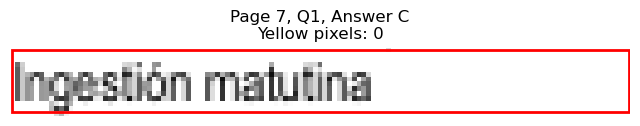

Page 7, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=432.3, y1=114.7
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 530
Page 7, Q1, D: Yellow percentage: 0.0%


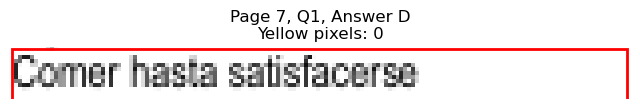


Page 7, Q1 - Selected Answer: A (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=139.5, y1=190.4
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 350
Page 7, Q2, A: Yellow percentage: 0.0%


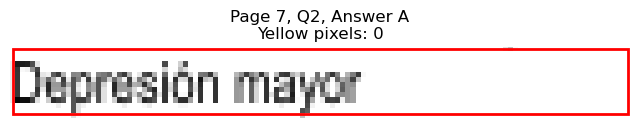

Page 7, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=125.5, y1=203.0
Page 7, Q2, B: Yellow pixels: 0
Page 7, Q2, B: Total non-white pixels: 315
Page 7, Q2, B: Yellow percentage: 0.0%


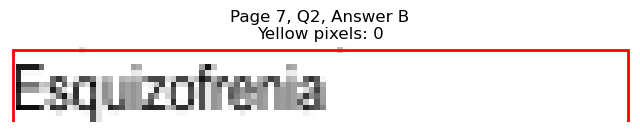

Page 7, Q2 - C: Detected box: x0=327.5, y0=177.7, x1=370.1, y1=190.4
Page 7, Q2, C: Yellow pixels: 950
Page 7, Q2, C: Total non-white pixels: 1316
Page 7, Q2, C: Yellow percentage: 72.2%


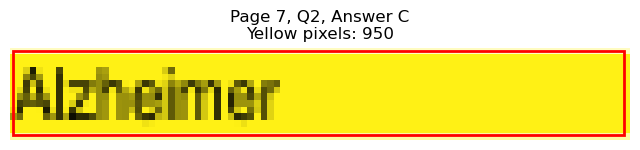

Page 7, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=425.3, y1=203.0
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 668
Page 7, Q2, D: Yellow percentage: 0.0%


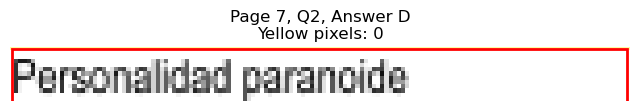


Page 7, Q2 - Selected Answer: C (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=156.1, y1=240.9
Page 7, Q3, A: Yellow pixels: 1491
Page 7, Q3, A: Total non-white pixels: 1807
Page 7, Q3, A: Yellow percentage: 82.5%


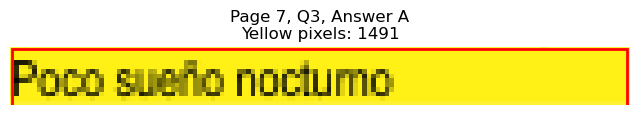

Page 7, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=149.1, y1=253.5
Page 7, Q3, B: Yellow pixels: 132
Page 7, Q3, B: Total non-white pixels: 552
Page 7, Q3, B: Yellow percentage: 23.9%


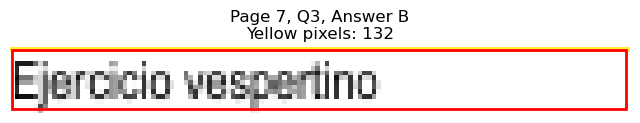

Page 7, Q3 - C: Detected box: x0=327.5, y0=228.3, x1=389.7, y1=240.9
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 308
Page 7, Q3, C: Yellow percentage: 0.0%


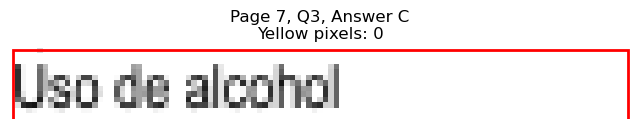

Page 7, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=405.3, y1=253.5
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 402
Page 7, Q3, D: Yellow percentage: 0.0%


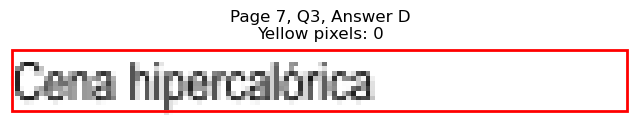


Page 7, Q3 - Selected Answer: A (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=108.4, y1=316.7
Page 7, Q4, A: Yellow pixels: 0
Page 7, Q4, A: Total non-white pixels: 296
Page 7, Q4, A: Yellow percentage: 0.0%


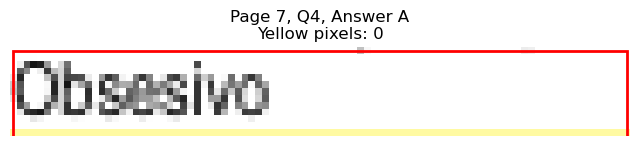

Page 7, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=112.9, y1=329.3
Page 7, Q4, B: Yellow pixels: 959
Page 7, Q4, B: Total non-white pixels: 1330
Page 7, Q4, B: Yellow percentage: 72.1%


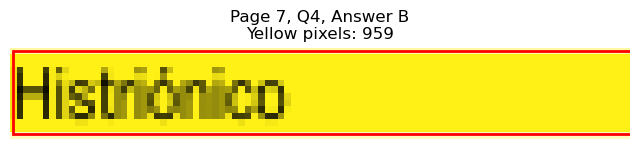

Page 7, Q4 - C: Detected box: x0=327.5, y0=304.0, x1=361.6, y1=316.7
Page 7, Q4, C: Yellow pixels: 0
Page 7, Q4, C: Total non-white pixels: 185
Page 7, Q4, C: Yellow percentage: 0.0%


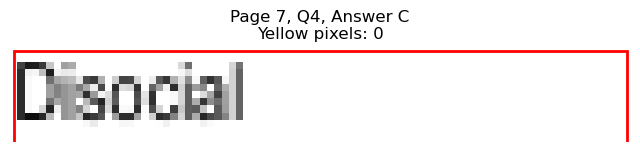

Page 7, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=381.2, y1=329.3
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 289
Page 7, Q4, D: Yellow percentage: 0.0%


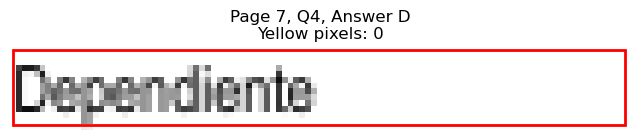


Page 7, Q4 - Selected Answer: B (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=354.5, x1=143.5, y1=367.2
Page 7, Q5, A: Yellow pixels: 1349
Page 7, Q5, A: Total non-white pixels: 1764
Page 7, Q5, A: Yellow percentage: 76.5%


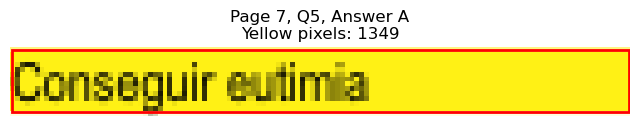

Page 7, Q5 - B: Detected box: x0=68.3, y0=367.1, x1=123.0, y1=379.8
Page 7, Q5, B: Yellow pixels: 0
Page 7, Q5, B: Total non-white pixels: 377
Page 7, Q5, B: Yellow percentage: 0.0%


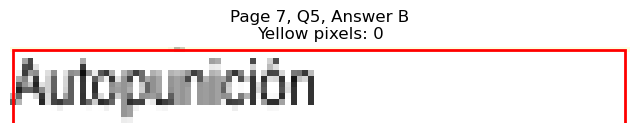

Page 7, Q5 - C: Detected box: x0=327.5, y0=354.5, x1=403.7, y1=367.2
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 350
Page 7, Q5, C: Yellow percentage: 0.0%


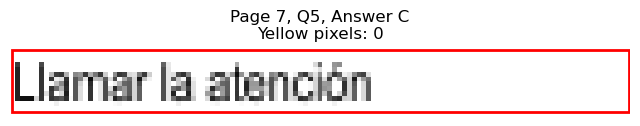

Page 7, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=388.7, y1=379.8
Page 7, Q5, D: Yellow pixels: 0
Page 7, Q5, D: Total non-white pixels: 311
Page 7, Q5, D: Yellow percentage: 0.0%


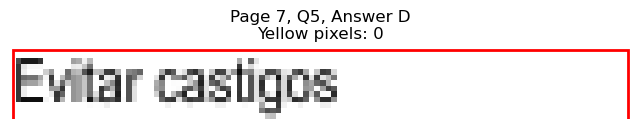


Page 7, Q5 - Selected Answer: A (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=404.9, x1=100.5, y1=417.6
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 129
Page 7, Q6, A: Yellow percentage: 0.0%


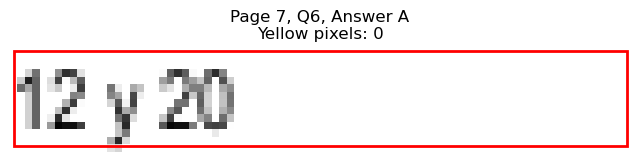

Page 7, Q6 - B: Detected box: x0=68.3, y0=417.6, x1=100.5, y1=430.3
Page 7, Q6, B: Yellow pixels: 0
Page 7, Q6, B: Total non-white pixels: 154
Page 7, Q6, B: Yellow percentage: 0.0%


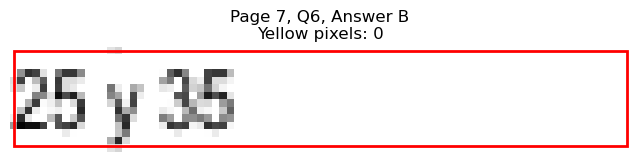

Page 7, Q6 - C: Detected box: x0=327.5, y0=404.9, x1=349.6, y1=417.6
Page 7, Q6, C: Yellow pixels: 0
Page 7, Q6, C: Total non-white pixels: 77
Page 7, Q6, C: Yellow percentage: 0.0%


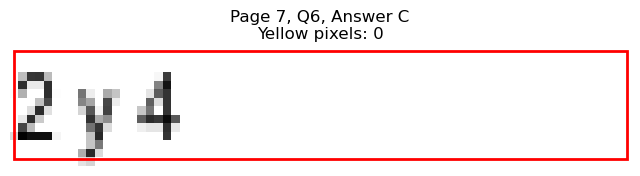

Page 7, Q6 - D: Detected box: x0=327.5, y0=417.6, x1=349.6, y1=430.3
Page 7, Q6, D: Yellow pixels: 813
Page 7, Q6, D: Total non-white pixels: 1022
Page 7, Q6, D: Yellow percentage: 79.5%


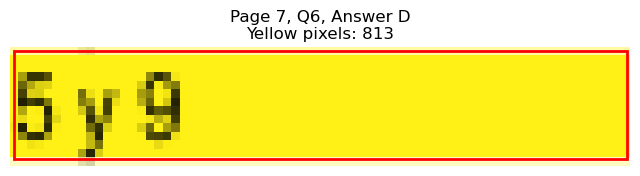


Page 7, Q6 - Selected Answer: D (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=468.1, x1=111.5, y1=480.7
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 237
Page 7, Q7, A: Yellow percentage: 0.0%


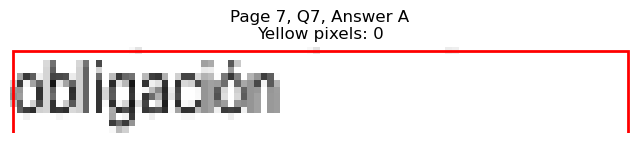

Page 7, Q7 - B: Detected box: x0=68.3, y0=480.8, x1=115.0, y1=493.4
Page 7, Q7, B: Yellow pixels: 0
Page 7, Q7, B: Total non-white pixels: 239
Page 7, Q7, B: Yellow percentage: 0.0%


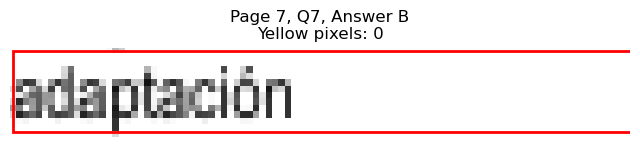

Page 7, Q7 - C: Detected box: x0=327.5, y0=468.1, x1=369.2, y1=480.7
Page 7, Q7, C: Yellow pixels: 0
Page 7, Q7, C: Total non-white pixels: 204
Page 7, Q7, C: Yellow percentage: 0.0%


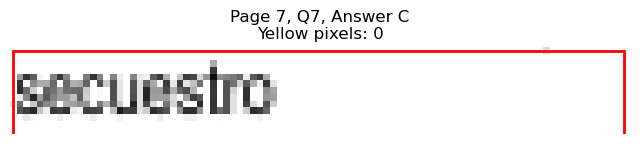

Page 7, Q7 - D: Detected box: x0=327.5, y0=480.8, x1=366.2, y1=493.4
Page 7, Q7, D: Yellow pixels: 939
Page 7, Q7, D: Total non-white pixels: 1260
Page 7, Q7, D: Yellow percentage: 74.5%


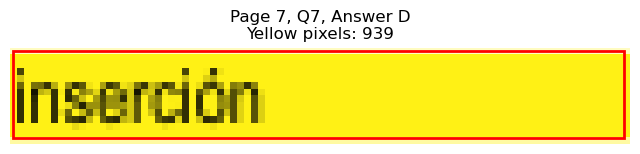


Page 7, Q7 - Selected Answer: D (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=556.5, x1=112.0, y1=569.2
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 216
Page 7, Q8, A: Yellow percentage: 0.0%


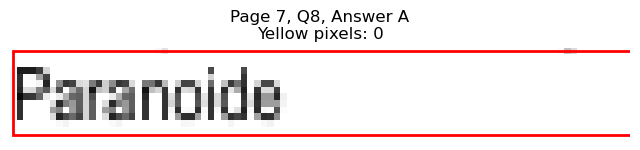

Page 7, Q8 - B: Detected box: x0=68.3, y0=569.1, x1=124.5, y1=581.8
Page 7, Q8, B: Yellow pixels: 0
Page 7, Q8, B: Total non-white pixels: 302
Page 7, Q8, B: Yellow percentage: 0.0%


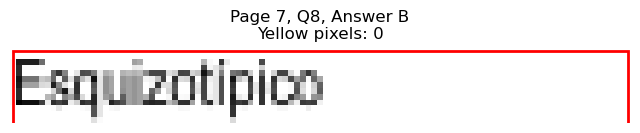

Page 7, Q8 - C: Detected box: x0=327.5, y0=556.5, x1=394.3, y1=569.2
Page 7, Q8, C: Yellow pixels: 118
Page 7, Q8, C: Total non-white pixels: 454
Page 7, Q8, C: Yellow percentage: 26.0%


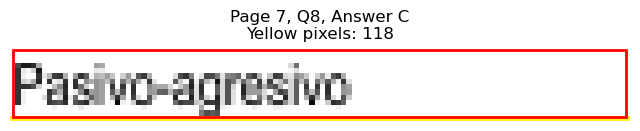

Page 7, Q8 - D: Detected box: x0=327.5, y0=569.1, x1=415.9, y1=581.8
Page 7, Q8, D: Yellow pixels: 1478
Page 7, Q8, D: Total non-white pixels: 1807
Page 7, Q8, D: Yellow percentage: 81.8%


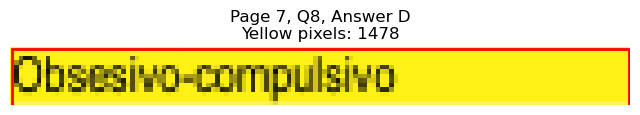


Page 7, Q8 - Selected Answer: D (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=68.3, y0=619.6, x1=115.0, y1=632.3
Page 7, Q9, A: Yellow pixels: 0
Page 7, Q9, A: Total non-white pixels: 245
Page 7, Q9, A: Yellow percentage: 0.0%


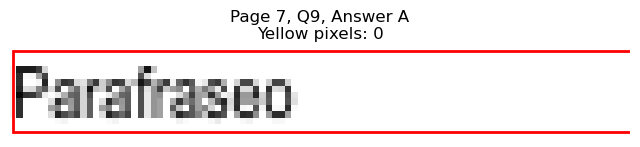

Page 7, Q9 - B: Detected box: x0=68.3, y0=632.2, x1=112.9, y1=644.9
Page 7, Q9, B: Yellow pixels: 0
Page 7, Q9, B: Total non-white pixels: 222
Page 7, Q9, B: Yellow percentage: 0.0%


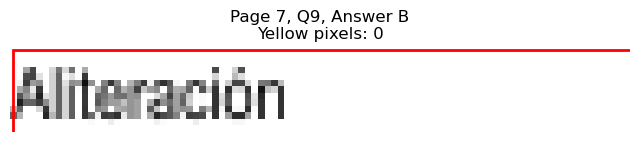

Page 7, Q9 - C: Detected box: x0=327.5, y0=619.6, x1=375.7, y1=632.3
Page 7, Q9, C: Yellow pixels: 99
Page 7, Q9, C: Total non-white pixels: 338
Page 7, Q9, C: Yellow percentage: 29.3%


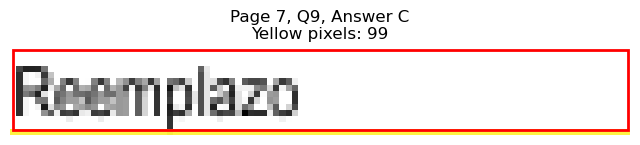

Page 7, Q9 - D: Detected box: x0=327.5, y0=632.2, x1=371.7, y1=644.9
Page 7, Q9, D: Yellow pixels: 1056
Page 7, Q9, D: Total non-white pixels: 1235
Page 7, Q9, D: Yellow percentage: 85.5%


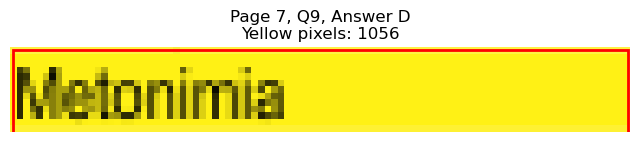


Page 7, Q9 - Selected Answer: D (based on yellow pixel count)




Page 7, Q10 - A: Detected box: x0=68.3, y0=695.4, x1=190.2, y1=708.0
Page 7, Q10, A: Yellow pixels: 0
Page 7, Q10, A: Total non-white pixels: 577
Page 7, Q10, A: Yellow percentage: 0.0%


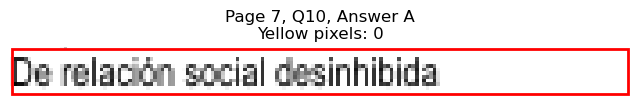

Page 7, Q10 - B: Detected box: x0=68.3, y0=708.0, x1=122.4, y1=720.6
Page 7, Q10, B: Yellow pixels: 0
Page 7, Q10, B: Total non-white pixels: 256
Page 7, Q10, B: Yellow percentage: 0.0%


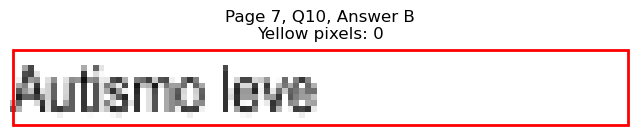

Page 7, Q10 - C: Detected box: x0=327.5, y0=695.4, x1=403.3, y1=708.0
Page 7, Q10, C: Yellow pixels: 1358
Page 7, Q10, C: Total non-white pixels: 1654
Page 7, Q10, C: Yellow percentage: 82.1%


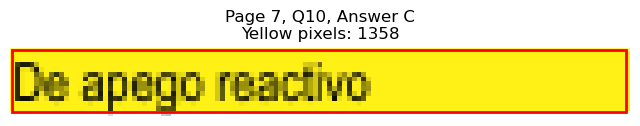

Page 7, Q10 - D: Detected box: x0=327.5, y0=708.0, x1=427.9, y1=720.6
Page 7, Q10, D: Yellow pixels: 146
Page 7, Q10, D: Total non-white pixels: 706
Page 7, Q10, D: Yellow percentage: 20.7%


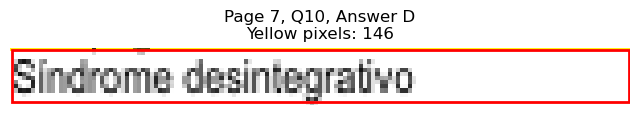


Page 7, Q10 - Selected Answer: C (based on yellow pixel count)




Page 7, Q11 - A: Detected box: x0=68.3, y0=745.8, x1=110.9, y1=758.4
Page 7, Q11, A: Yellow pixels: 1053
Page 7, Q11, A: Total non-white pixels: 1302
Page 7, Q11, A: Yellow percentage: 80.9%


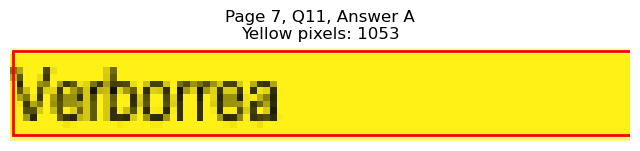

Page 7, Q11 - B: Detected box: x0=68.3, y0=758.5, x1=123.5, y1=771.2
Page 7, Q11, B: Yellow pixels: 106
Page 7, Q11, B: Total non-white pixels: 408
Page 7, Q11, B: Yellow percentage: 26.0%


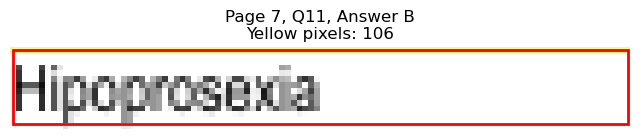

Page 7, Q11 - C: Detected box: x0=327.5, y0=745.8, x1=385.7, y1=758.4
Page 7, Q11, C: Yellow pixels: 0
Page 7, Q11, C: Total non-white pixels: 296
Page 7, Q11, C: Yellow percentage: 0.0%


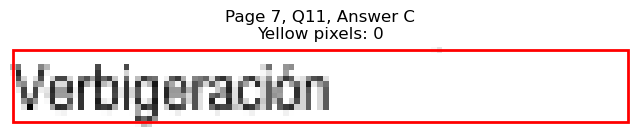

Page 7, Q11 - D: Detected box: x0=327.5, y0=758.5, x1=369.7, y1=771.2
Page 7, Q11, D: Yellow pixels: 0
Page 7, Q11, D: Total non-white pixels: 230
Page 7, Q11, D: Yellow percentage: 0.0%


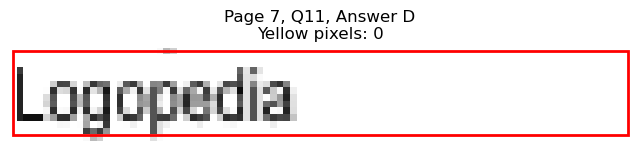


Page 7, Q11 - Selected Answer: A (based on yellow pixel count)





Page 8: Found 10 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=113.4, y1=127.3
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 236
Page 8, Q1, A: Yellow percentage: 0.0%


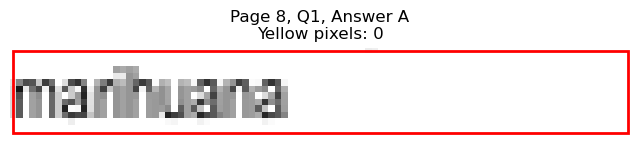

Page 8, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=109.5, y1=139.9
Page 8, Q1, B: Yellow pixels: 0
Page 8, Q1, B: Total non-white pixels: 219
Page 8, Q1, B: Yellow percentage: 0.0%


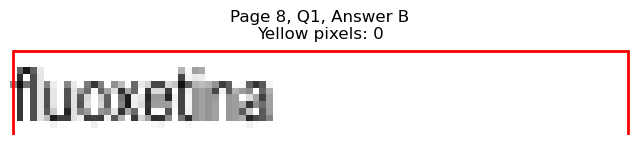

Page 8, Q1 - C: Detected box: x0=327.5, y0=114.6, x1=358.6, y1=127.3
Page 8, Q1, C: Yellow pixels: 865
Page 8, Q1, C: Total non-white pixels: 1148
Page 8, Q1, C: Yellow percentage: 75.3%


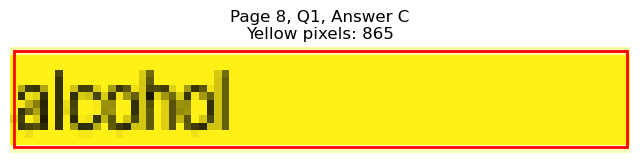

Page 8, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=374.2, y1=139.9
Page 8, Q1, D: Yellow pixels: 0
Page 8, Q1, D: Total non-white pixels: 326
Page 8, Q1, D: Yellow percentage: 0.0%


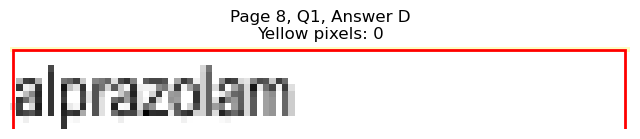


Page 8, Q1 - Selected Answer: C (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=95.9, y1=215.6
Page 8, Q2, A: Yellow pixels: 910
Page 8, Q2, A: Total non-white pixels: 1092
Page 8, Q2, A: Yellow percentage: 83.3%


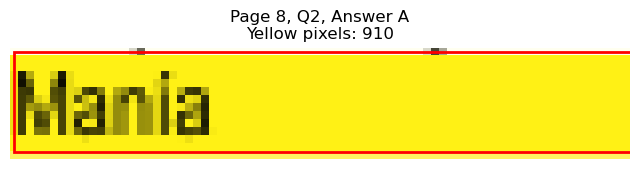

Page 8, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=103.9, y1=228.3
Page 8, Q2, B: Yellow pixels: 86
Page 8, Q2, B: Total non-white pixels: 277
Page 8, Q2, B: Yellow percentage: 31.0%


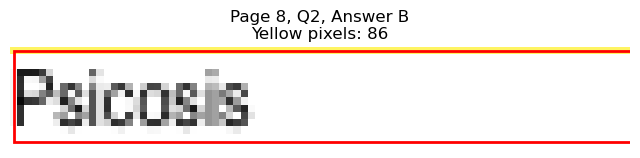

Page 8, Q2 - C: Detected box: x0=327.5, y0=202.9, x1=391.7, y1=215.6
Page 8, Q2, C: Yellow pixels: 0
Page 8, Q2, C: Total non-white pixels: 331
Page 8, Q2, C: Yellow percentage: 0.0%


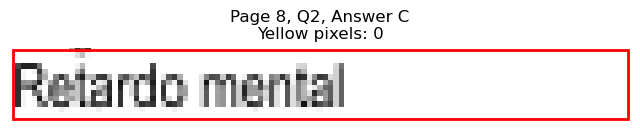

Page 8, Q2 - D: Detected box: x0=327.5, y0=215.7, x1=374.2, y1=228.3
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 250
Page 8, Q2, D: Yellow percentage: 0.0%


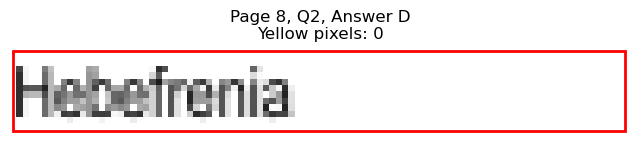


Page 8, Q2 - Selected Answer: A (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=161.5, y1=278.7
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 502
Page 8, Q3, A: Yellow percentage: 0.0%


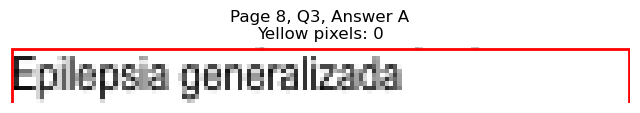

Page 8, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=190.7, y1=291.5
Page 8, Q3, B: Yellow pixels: 1741
Page 8, Q3, B: Total non-white pixels: 2422
Page 8, Q3, B: Yellow percentage: 71.9%


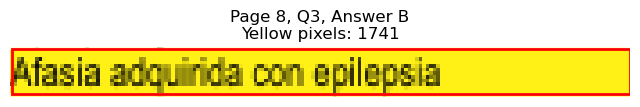

Page 8, Q3 - C: Detected box: x0=327.5, y0=266.1, x1=427.4, y1=278.7
Page 8, Q3, C: Yellow pixels: 0
Page 8, Q3, C: Total non-white pixels: 519
Page 8, Q3, C: Yellow percentage: 0.0%


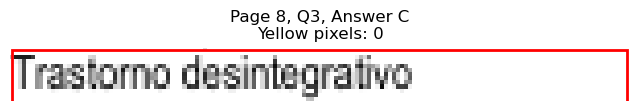

Page 8, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=411.8, y1=291.5
Page 8, Q3, D: Yellow pixels: 0
Page 8, Q3, D: Total non-white pixels: 435
Page 8, Q3, D: Yellow percentage: 0.0%


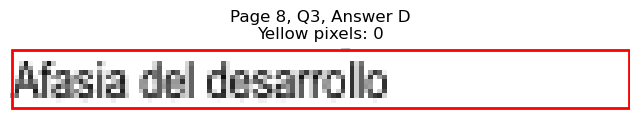


Page 8, Q3 - Selected Answer: B (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=126.0, y1=329.3
Page 8, Q4, A: Yellow pixels: 109
Page 8, Q4, A: Total non-white pixels: 414
Page 8, Q4, A: Yellow percentage: 26.3%


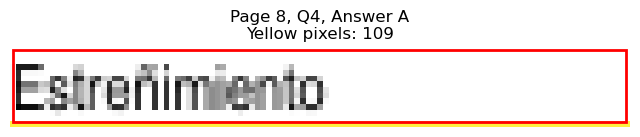

Page 8, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=100.9, y1=341.9
Page 8, Q4, B: Yellow pixels: 955
Page 8, Q4, B: Total non-white pixels: 1079
Page 8, Q4, B: Yellow percentage: 88.5%


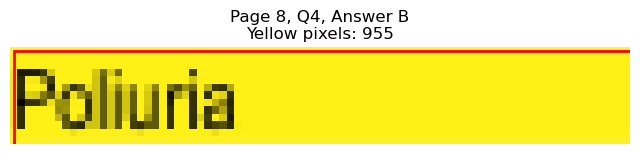

Page 8, Q4 - C: Detected box: x0=327.5, y0=316.6, x1=379.7, y1=329.3
Page 8, Q4, C: Yellow pixels: 0
Page 8, Q4, C: Total non-white pixels: 283
Page 8, Q4, C: Yellow percentage: 0.0%


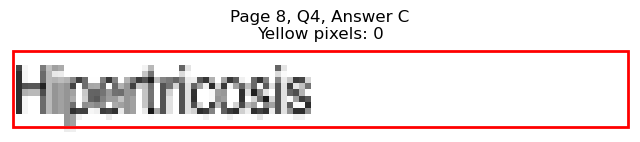

Page 8, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=382.7, y1=341.9
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 267
Page 8, Q4, D: Yellow percentage: 0.0%


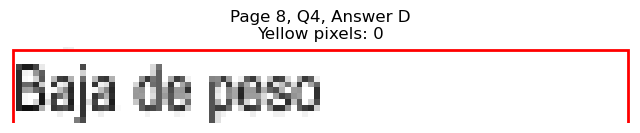


Page 8, Q4 - Selected Answer: B (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=117.5, y1=379.8
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 280
Page 8, Q5, A: Yellow percentage: 0.0%


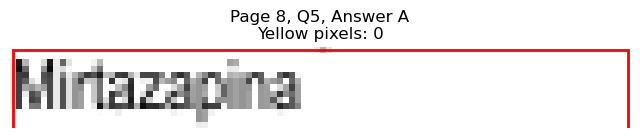

Page 8, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=134.5, y1=392.4
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 343
Page 8, Q5, B: Yellow percentage: 0.0%


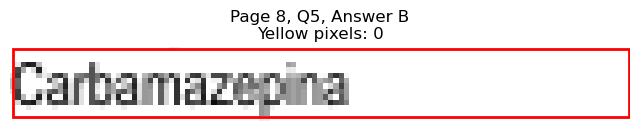

Page 8, Q5 - C: Detected box: x0=327.5, y0=367.1, x1=371.7, y1=379.8
Page 8, Q5, C: Yellow pixels: 1047
Page 8, Q5, C: Total non-white pixels: 1235
Page 8, Q5, C: Yellow percentage: 84.8%


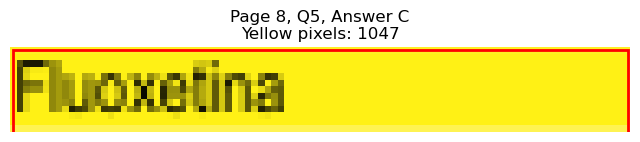

Page 8, Q5 - D: Detected box: x0=327.5, y0=379.7, x1=380.7, y1=392.4
Page 8, Q5, D: Yellow pixels: 104
Page 8, Q5, D: Total non-white pixels: 375
Page 8, Q5, D: Yellow percentage: 27.7%


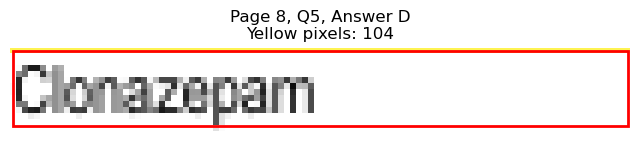


Page 8, Q5 - Selected Answer: C (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=68.3, y0=367.1, x1=117.5, y1=379.8
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 280
Page 8, Q6, A: Yellow percentage: 0.0%


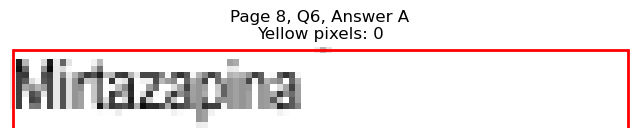

Page 8, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=105.9, y1=480.7
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 188
Page 8, Q6, B: Yellow percentage: 0.0%


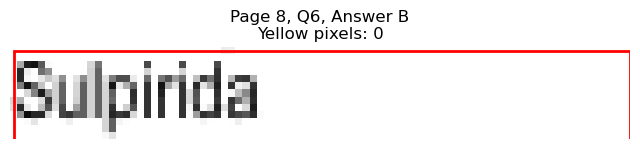

Page 8, Q6 - C: Detected box: x0=327.5, y0=367.1, x1=371.7, y1=379.8
Page 8, Q6, C: Yellow pixels: 1047
Page 8, Q6, C: Total non-white pixels: 1235
Page 8, Q6, C: Yellow percentage: 84.8%


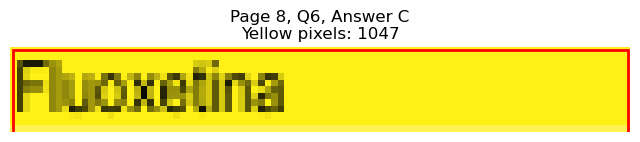

Page 8, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=377.2, y1=480.7
Page 8, Q6, D: Yellow pixels: 1128
Page 8, Q6, D: Total non-white pixels: 1313
Page 8, Q6, D: Yellow percentage: 85.9%


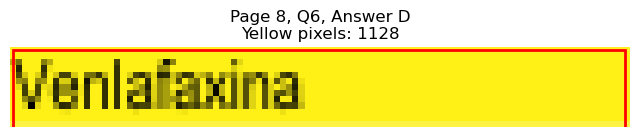


Page 8, Q6 - Selected Answer: D (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=518.6, x1=127.9, y1=531.2
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 292
Page 8, Q7, A: Yellow percentage: 0.0%


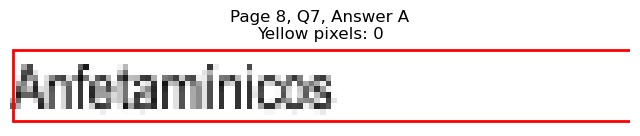

Page 8, Q7 - B: Detected box: x0=68.3, y0=531.2, x1=97.9, y1=543.8
Page 8, Q7, B: Yellow pixels: 0
Page 8, Q7, B: Total non-white pixels: 151
Page 8, Q7, B: Yellow percentage: 0.0%


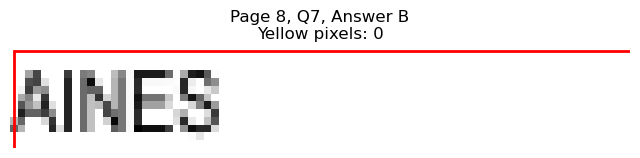

Page 8, Q7 - C: Detected box: x0=327.5, y0=518.6, x1=365.7, y1=531.2
Page 8, Q7, C: Yellow pixels: 1019
Page 8, Q7, C: Total non-white pixels: 1246
Page 8, Q7, C: Yellow percentage: 81.8%


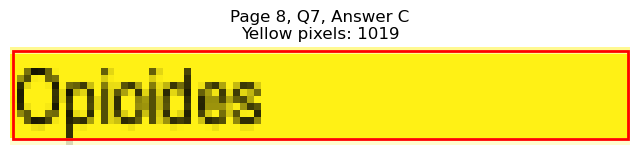

Page 8, Q7 - D: Detected box: x0=327.5, y0=531.2, x1=376.1, y1=543.8
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 353
Page 8, Q7, D: Yellow percentage: 0.0%


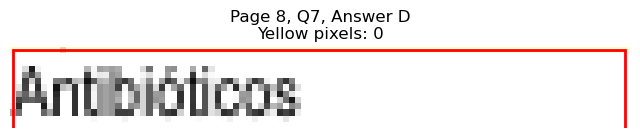


Page 8, Q7 - Selected Answer: C (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=581.7, x1=132.0, y1=594.4
Page 8, Q8, A: Yellow pixels: 115
Page 8, Q8, A: Total non-white pixels: 446
Page 8, Q8, A: Yellow percentage: 25.8%


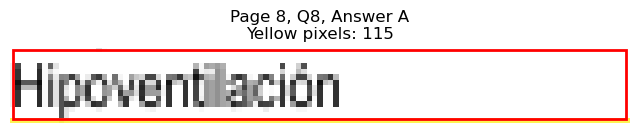

Page 8, Q8 - B: Detected box: x0=68.3, y0=594.3, x1=126.5, y1=607.0
Page 8, Q8, B: Yellow pixels: 1188
Page 8, Q8, B: Total non-white pixels: 1417
Page 8, Q8, B: Yellow percentage: 83.8%


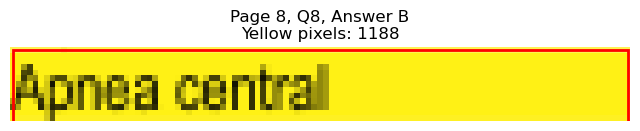

Page 8, Q8 - C: Detected box: x0=327.5, y0=581.7, x1=414.8, y1=594.4
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 455
Page 8, Q8, C: Yellow percentage: 0.0%


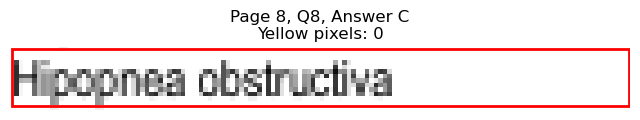

Page 8, Q8 - D: Detected box: x0=327.5, y0=594.3, x1=407.3, y1=607.0
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 412
Page 8, Q8, D: Yellow percentage: 0.0%


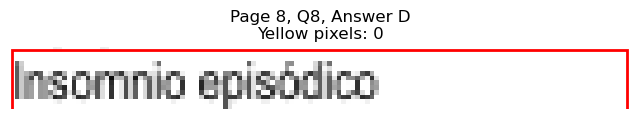


Page 8, Q8 - Selected Answer: B (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=56.6, y0=632.2, x1=65.2, y1=644.9
Page 8, Q9, A: Yellow pixels: 0
Page 8, Q9, A: Total non-white pixels: 126
Page 8, Q9, A: Yellow percentage: 0.0%


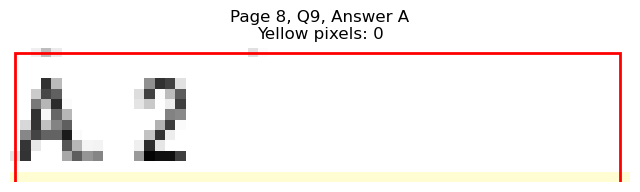

Page 8, Q9 - B: Detected box: x0=56.6, y0=644.9, x1=65.2, y1=657.5
Page 8, Q9, B: Yellow pixels: 726
Page 8, Q9, B: Total non-white pixels: 840
Page 8, Q9, B: Yellow percentage: 86.4%


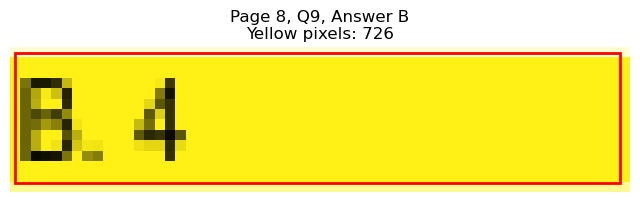

Page 8, Q9 - C: Detected box: x0=315.4, y0=632.2, x1=324.4, y1=644.9
Page 8, Q9, C: Yellow pixels: 0
Page 8, Q9, C: Total non-white pixels: 70
Page 8, Q9, C: Yellow percentage: 0.0%


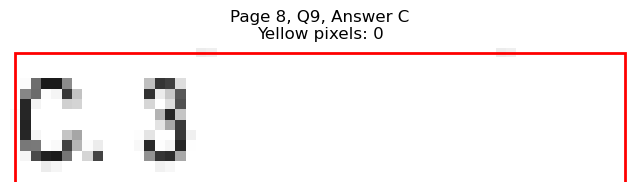

Page 8, Q9 - D: Detected box: x0=315.4, y0=644.9, x1=324.4, y1=657.5
Page 8, Q9, D: Yellow pixels: 0
Page 8, Q9, D: Total non-white pixels: 53
Page 8, Q9, D: Yellow percentage: 0.0%


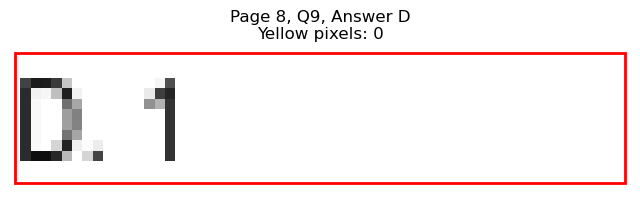


Page 8, Q9 - Selected Answer: B (based on yellow pixel count)




Page 8, Q10 - A: Detected box: x0=68.3, y0=720.6, x1=111.4, y1=733.2
Page 8, Q10, A: Yellow pixels: 94
Page 8, Q10, A: Total non-white pixels: 309
Page 8, Q10, A: Yellow percentage: 30.4%


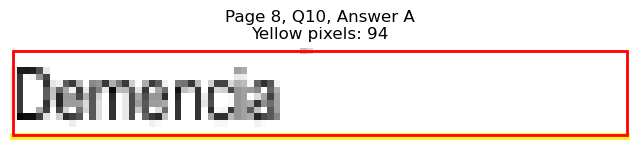

Page 8, Q10 - B: Detected box: x0=68.3, y0=733.2, x1=103.9, y1=745.8
Page 8, Q10, B: Yellow pixels: 982
Page 8, Q10, B: Total non-white pixels: 1118
Page 8, Q10, B: Yellow percentage: 87.8%


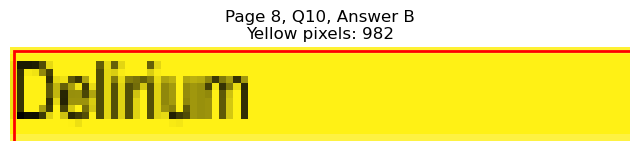

Page 8, Q10 - C: Detected box: x0=327.5, y0=720.6, x1=371.2, y1=733.2
Page 8, Q10, C: Yellow pixels: 0
Page 8, Q10, C: Total non-white pixels: 233
Page 8, Q10, C: Yellow percentage: 0.0%


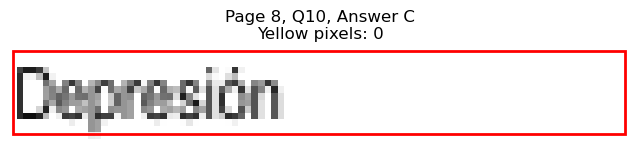

Page 8, Q10 - D: Detected box: x0=327.5, y0=733.2, x1=365.2, y1=745.8
Page 8, Q10, D: Yellow pixels: 0
Page 8, Q10, D: Total non-white pixels: 208
Page 8, Q10, D: Yellow percentage: 0.0%


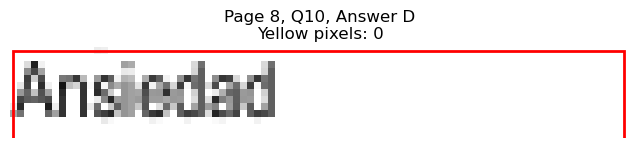


Page 8, Q10 - Selected Answer: B (based on yellow pixel count)





Page 9: Found 10 questions
Page 9, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=113.4, y1=114.7
Page 9, Q1, A: Yellow pixels: 1076
Page 9, Q1, A: Total non-white pixels: 1248
Page 9, Q1, A: Yellow percentage: 86.2%


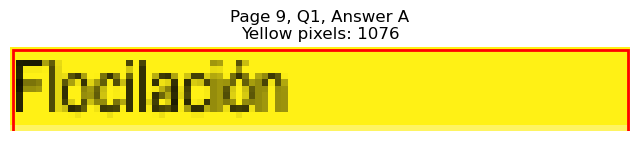

Page 9, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=116.9, y1=127.3
Page 9, Q1, B: Yellow pixels: 99
Page 9, Q1, B: Total non-white pixels: 319
Page 9, Q1, B: Yellow percentage: 31.0%


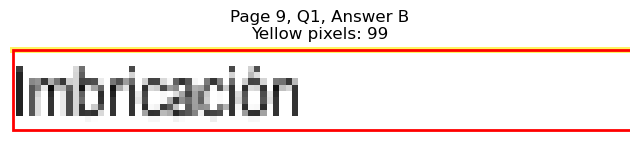

Page 9, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=387.2, y1=114.7
Page 9, Q1, C: Yellow pixels: 0
Page 9, Q1, C: Total non-white pixels: 331
Page 9, Q1, C: Yellow percentage: 0.0%


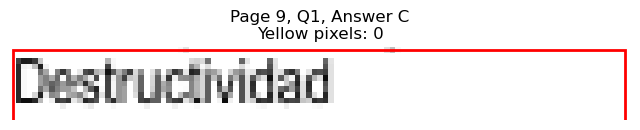

Page 9, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=370.6, y1=127.3
Page 9, Q1, D: Yellow pixels: 0
Page 9, Q1, D: Total non-white pixels: 212
Page 9, Q1, D: Yellow percentage: 0.0%


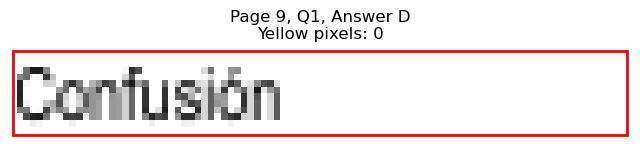


Page 9, Q1 - Selected Answer: A (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=163.1, y1=190.4
Page 9, Q2, A: Yellow pixels: 146
Page 9, Q2, A: Total non-white pixels: 626
Page 9, Q2, A: Yellow percentage: 23.3%


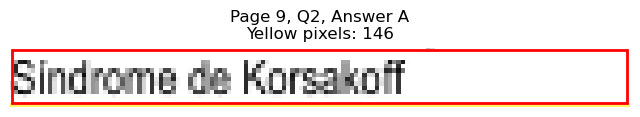

Page 9, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=178.7, y1=203.0
Page 9, Q2, B: Yellow pixels: 1652
Page 9, Q2, B: Total non-white pixels: 2093
Page 9, Q2, B: Yellow percentage: 78.9%


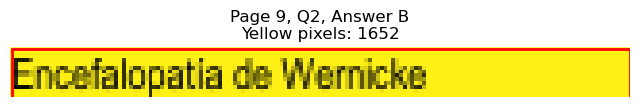

Page 9, Q2 - C: Detected box: x0=327.5, y0=177.7, x1=405.3, y1=190.4
Page 9, Q2, C: Yellow pixels: 0
Page 9, Q2, C: Total non-white pixels: 410
Page 9, Q2, C: Yellow percentage: 0.0%


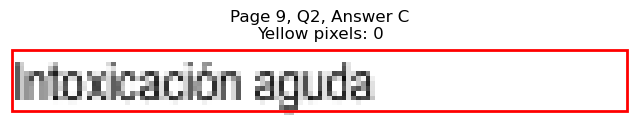

Page 9, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=404.3, y1=203.0
Page 9, Q2, D: Yellow pixels: 0
Page 9, Q2, D: Total non-white pixels: 405
Page 9, Q2, D: Yellow percentage: 0.0%


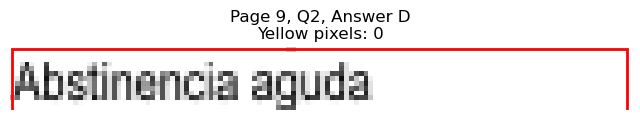


Page 9, Q2 - Selected Answer: B (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=80.9, y1=253.5
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 45
Page 9, Q3, A: Yellow percentage: 0.0%


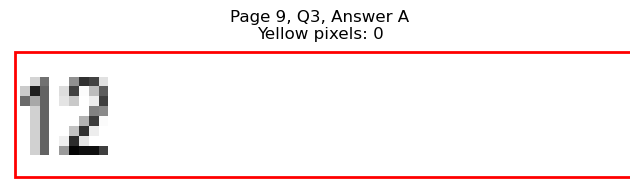

Page 9, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=80.9, y1=266.1
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 67
Page 9, Q3, B: Yellow percentage: 0.0%


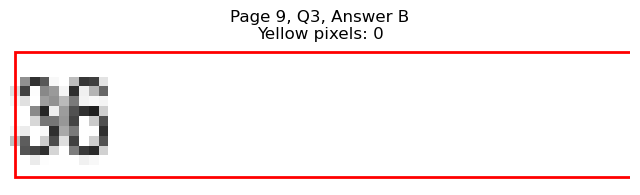

Page 9, Q3 - C: Detected box: x0=327.5, y0=240.9, x1=340.1, y1=253.5
Page 9, Q3, C: Yellow pixels: 64
Page 9, Q3, C: Total non-white pixels: 133
Page 9, Q3, C: Yellow percentage: 48.1%


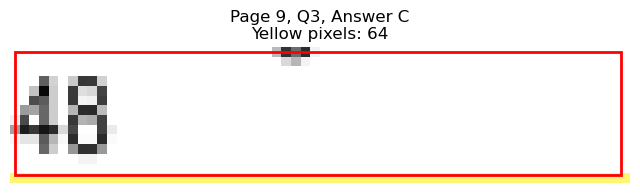

Page 9, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=340.1, y1=266.1
Page 9, Q3, D: Yellow pixels: 799
Page 9, Q3, D: Total non-white pixels: 896
Page 9, Q3, D: Yellow percentage: 89.2%


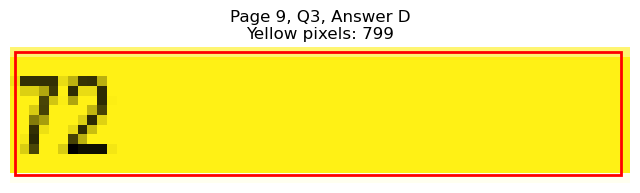


Page 9, Q3 - Selected Answer: D (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=123.5, y1=316.7
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 283
Page 9, Q4, A: Yellow percentage: 0.0%


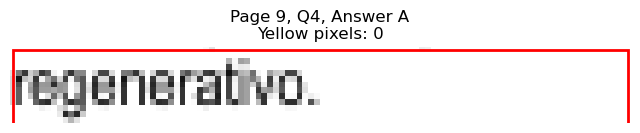

Page 9, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=104.4, y1=329.3
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 180
Page 9, Q4, B: Yellow percentage: 0.0%


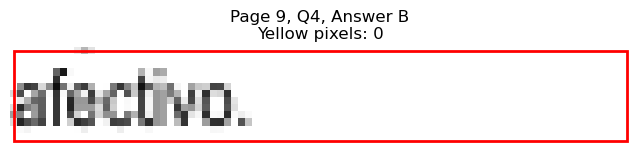

Page 9, Q4 - C: Detected box: x0=327.5, y0=304.0, x1=409.7, y1=316.7
Page 9, Q4, C: Yellow pixels: 1420
Page 9, Q4, C: Total non-white pixels: 1729
Page 9, Q4, C: Yellow percentage: 82.1%


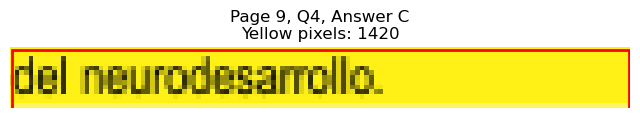

Page 9, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=393.2, y1=329.3
Page 9, Q4, D: Yellow pixels: 117
Page 9, Q4, D: Total non-white pixels: 436
Page 9, Q4, D: Yellow percentage: 26.8%


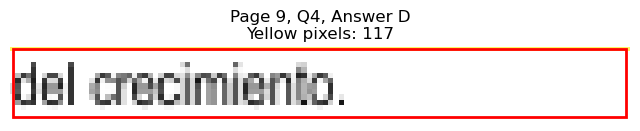


Page 9, Q4 - Selected Answer: C (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=147.5, y1=379.8
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 557
Page 9, Q5, A: Yellow percentage: 0.0%


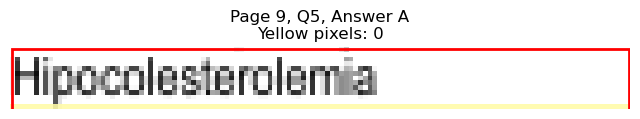

Page 9, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=120.5, y1=392.4
Page 9, Q5, B: Yellow pixels: 1028
Page 9, Q5, B: Total non-white pixels: 1442
Page 9, Q5, B: Yellow percentage: 71.3%


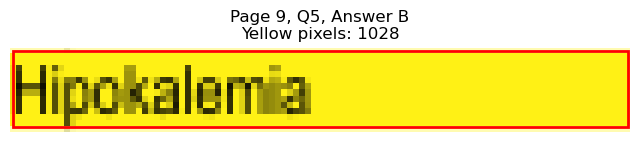

Page 9, Q5 - C: Detected box: x0=327.5, y0=367.1, x1=384.7, y1=379.8
Page 9, Q5, C: Yellow pixels: 0
Page 9, Q5, C: Total non-white pixels: 326
Page 9, Q5, C: Yellow percentage: 0.0%


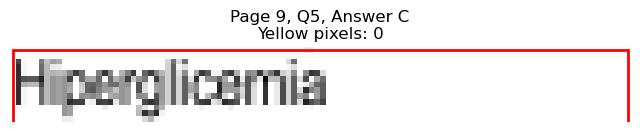

Page 9, Q5 - D: Detected box: x0=327.5, y0=379.7, x1=405.3, y1=392.4
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 438
Page 9, Q5, D: Yellow percentage: 0.0%


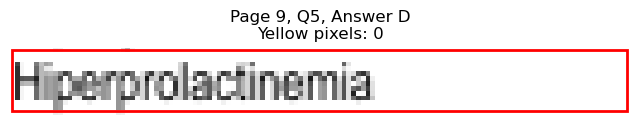


Page 9, Q5 - Selected Answer: B (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=103.5, y1=468.1
Page 9, Q6, A: Yellow pixels: 988
Page 9, Q6, A: Total non-white pixels: 1204
Page 9, Q6, A: Yellow percentage: 82.1%


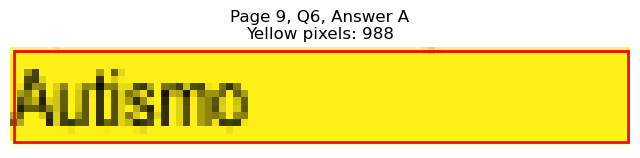

Page 9, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=102.9, y1=480.7
Page 9, Q6, B: Yellow pixels: 0
Page 9, Q6, B: Total non-white pixels: 256
Page 9, Q6, B: Yellow percentage: 0.0%


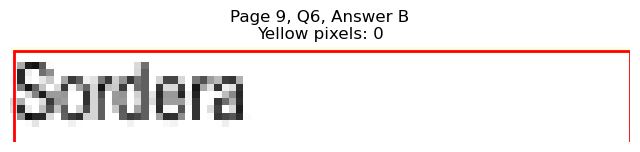

Page 9, Q6 - C: Detected box: x0=327.5, y0=455.5, x1=362.1, y1=468.1
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 168
Page 9, Q6, C: Yellow percentage: 0.0%


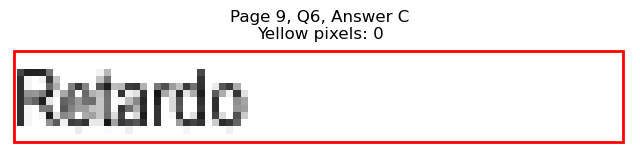

Page 9, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=363.2, y1=480.7
Page 9, Q6, D: Yellow pixels: 0
Page 9, Q6, D: Total non-white pixels: 185
Page 9, Q6, D: Yellow percentage: 0.0%


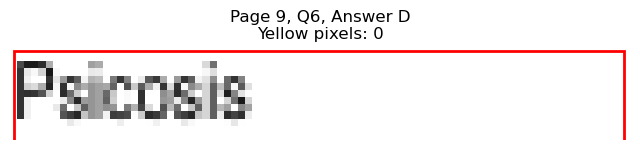


Page 9, Q6 - Selected Answer: A (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=185.7, y1=543.8
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 578
Page 9, Q7, A: Yellow percentage: 0.0%


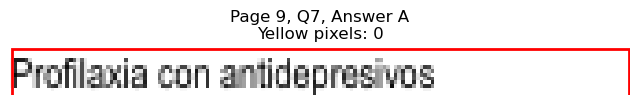

Page 9, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=142.6, y1=556.4
Page 9, Q7, B: Yellow pixels: 0
Page 9, Q7, B: Total non-white pixels: 349
Page 9, Q7, B: Yellow percentage: 0.0%


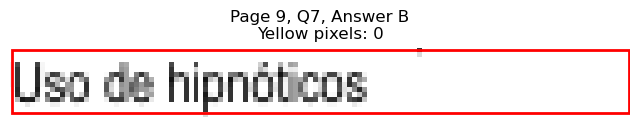

Page 9, Q7 - C: Detected box: x0=327.5, y0=531.2, x1=436.4, y1=543.8
Page 9, Q7, C: Yellow pixels: 1660
Page 9, Q7, C: Total non-white pixels: 2080
Page 9, Q7, C: Yellow percentage: 79.8%


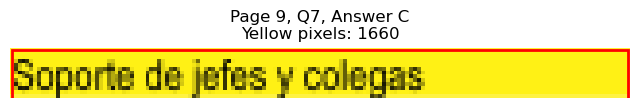

Page 9, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=409.7, y1=556.4
Page 9, Q7, D: Yellow pixels: 124
Page 9, Q7, D: Total non-white pixels: 533
Page 9, Q7, D: Yellow percentage: 23.3%


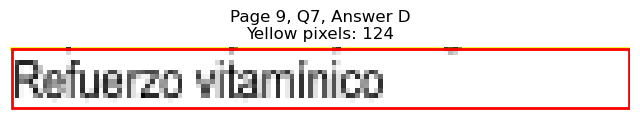


Page 9, Q7 - Selected Answer: C (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=68.3, y0=594.3, x1=118.0, y1=607.0
Page 9, Q8, A: Yellow pixels: 0
Page 9, Q8, A: Total non-white pixels: 236
Page 9, Q8, A: Yellow percentage: 0.0%


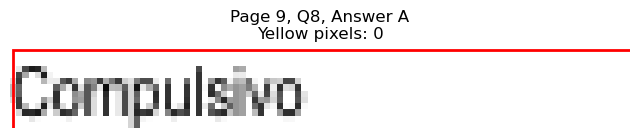

Page 9, Q8 - B: Detected box: x0=68.3, y0=606.9, x1=102.9, y1=619.6
Page 9, Q8, B: Yellow pixels: 0
Page 9, Q8, B: Total non-white pixels: 181
Page 9, Q8, B: Yellow percentage: 0.0%


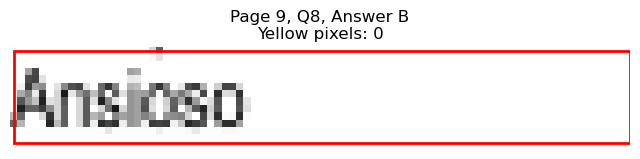

Page 9, Q8 - C: Detected box: x0=327.5, y0=594.3, x1=374.2, y1=607.0
Page 9, Q8, C: Yellow pixels: 1088
Page 9, Q8, C: Total non-white pixels: 1274
Page 9, Q8, C: Yellow percentage: 85.4%


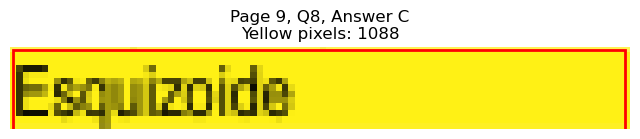

Page 9, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=366.2, y1=619.6
Page 9, Q8, D: Yellow pixels: 88
Page 9, Q8, D: Total non-white pixels: 296
Page 9, Q8, D: Yellow percentage: 29.7%


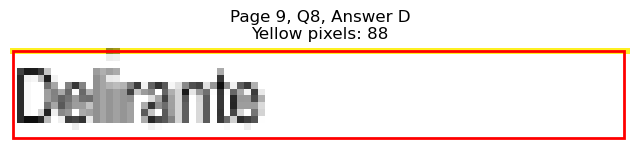


Page 9, Q8 - Selected Answer: C (based on yellow pixel count)




Page 9, Q9 - A: Detected box: x0=68.3, y0=644.9, x1=95.9, y1=657.5
Page 9, Q9, A: Yellow pixels: 78
Page 9, Q9, A: Total non-white pixels: 227
Page 9, Q9, A: Yellow percentage: 34.4%


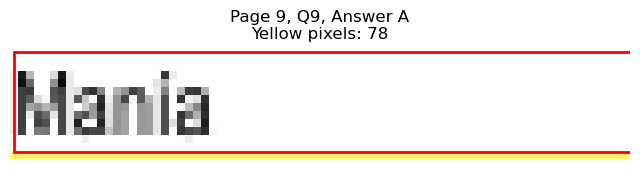

Page 9, Q9 - B: Detected box: x0=68.3, y0=657.5, x1=112.0, y1=670.1
Page 9, Q9, B: Yellow pixels: 1055
Page 9, Q9, B: Total non-white pixels: 1316
Page 9, Q9, B: Yellow percentage: 80.2%


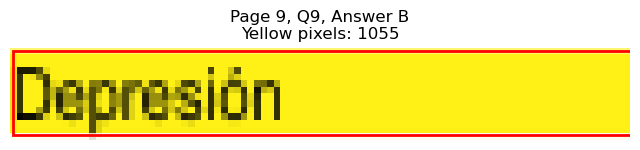

Page 9, Q9 - C: Detected box: x0=327.5, y0=644.9, x1=357.7, y1=657.5
Page 9, Q9, C: Yellow pixels: 0
Page 9, Q9, C: Total non-white pixels: 129
Page 9, Q9, C: Yellow percentage: 0.0%


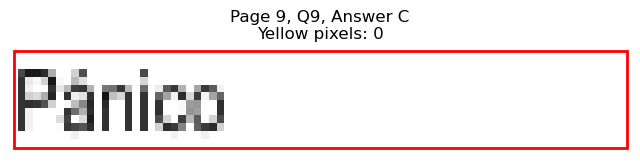

Page 9, Q9 - D: Detected box: x0=327.5, y0=657.5, x1=378.7, y1=670.1
Page 9, Q9, D: Yellow pixels: 0
Page 9, Q9, D: Total non-white pixels: 259
Page 9, Q9, D: Yellow percentage: 0.0%


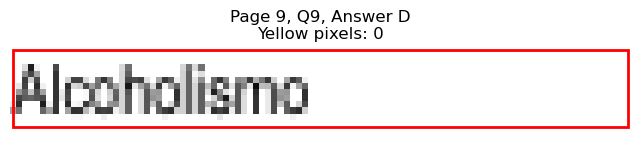


Page 9, Q9 - Selected Answer: B (based on yellow pixel count)




Page 9, Q10 - A: Detected box: x0=68.3, y0=720.6, x1=104.4, y1=733.2
Page 9, Q10, A: Yellow pixels: 981
Page 9, Q10, A: Total non-white pixels: 1218
Page 9, Q10, A: Yellow percentage: 80.5%


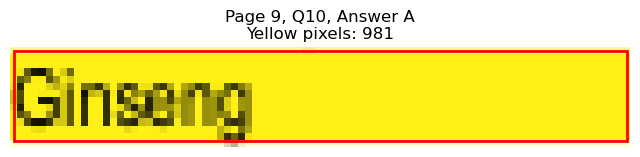

Page 9, Q10 - B: Detected box: x0=68.3, y0=733.2, x1=105.9, y1=745.8
Page 9, Q10, B: Yellow pixels: 0
Page 9, Q10, B: Total non-white pixels: 282
Page 9, Q10, B: Yellow percentage: 0.0%


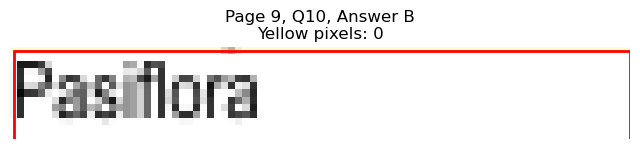

Page 9, Q10 - C: Detected box: x0=327.5, y0=720.6, x1=373.1, y1=733.2
Page 9, Q10, C: Yellow pixels: 0
Page 9, Q10, C: Total non-white pixels: 250
Page 9, Q10, C: Yellow percentage: 0.0%


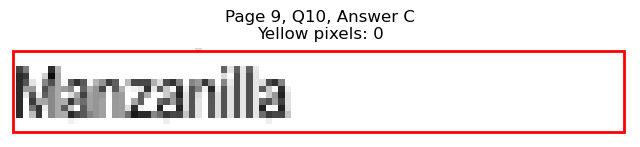

Page 9, Q10 - D: Detected box: x0=327.5, y0=733.2, x1=383.7, y1=745.8
Page 9, Q10, D: Yellow pixels: 0
Page 9, Q10, D: Total non-white pixels: 278
Page 9, Q10, D: Yellow percentage: 0.0%


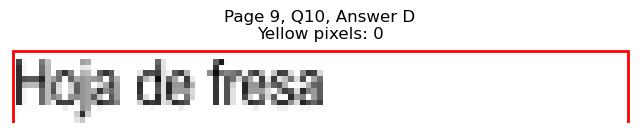


Page 9, Q10 - Selected Answer: A (based on yellow pixel count)





Page 10: Found 11 questions
Page 10, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=148.5, y1=102.1
Page 10, Q1, A: Yellow pixels: 1384
Page 10, Q1, A: Total non-white pixels: 1834
Page 10, Q1, A: Yellow percentage: 75.5%


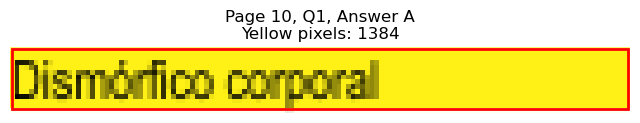

Page 10, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=162.6, y1=114.7
Page 10, Q1, B: Yellow pixels: 0
Page 10, Q1, B: Total non-white pixels: 633
Page 10, Q1, B: Yellow percentage: 0.0%


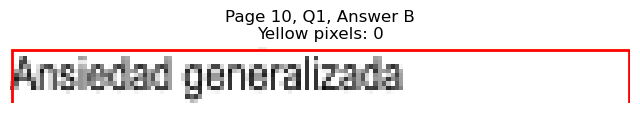

Page 10, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=418.3, y1=102.1
Page 10, Q1, C: Yellow pixels: 0
Page 10, Q1, C: Total non-white pixels: 476
Page 10, Q1, C: Yellow percentage: 0.0%


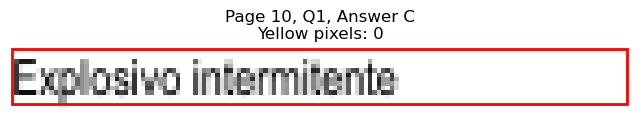

Page 10, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=422.8, y1=114.7
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 515
Page 10, Q1, D: Yellow percentage: 0.0%


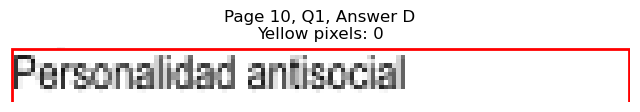


Page 10, Q1 - Selected Answer: A (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=68.3, y0=139.9, x1=109.9, y1=152.6
Page 10, Q2, A: Yellow pixels: 1031
Page 10, Q2, A: Total non-white pixels: 1288
Page 10, Q2, A: Yellow percentage: 80.0%


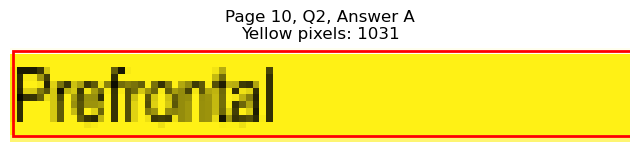

Page 10, Q2 - B: Detected box: x0=68.3, y0=152.5, x1=118.5, y1=165.2
Page 10, Q2, B: Yellow pixels: 101
Page 10, Q2, B: Total non-white pixels: 368
Page 10, Q2, B: Yellow percentage: 27.4%


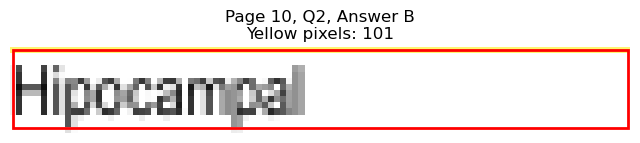

Page 10, Q2 - C: Detected box: x0=327.5, y0=139.9, x1=364.6, y1=152.6
Page 10, Q2, C: Yellow pixels: 0
Page 10, Q2, C: Total non-white pixels: 195
Page 10, Q2, C: Yellow percentage: 0.0%


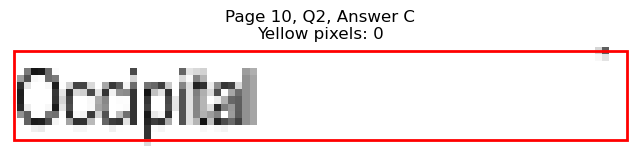

Page 10, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=360.7, y1=165.2
Page 10, Q2, D: Yellow pixels: 0
Page 10, Q2, D: Total non-white pixels: 168
Page 10, Q2, D: Yellow percentage: 0.0%


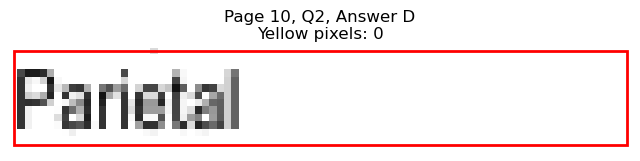


Page 10, Q2 - Selected Answer: A (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=68.3, y0=190.3, x1=147.5, y1=203.0
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 377
Page 10, Q3, A: Yellow percentage: 0.0%


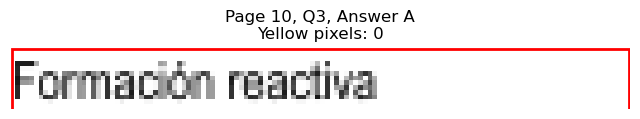

Page 10, Q3 - B: Detected box: x0=68.3, y0=202.9, x1=119.4, y1=215.6
Page 10, Q3, B: Yellow pixels: 0
Page 10, Q3, B: Total non-white pixels: 261
Page 10, Q3, B: Yellow percentage: 0.0%


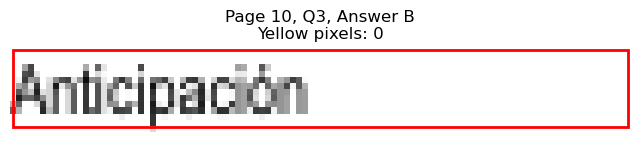

Page 10, Q3 - C: Detected box: x0=327.5, y0=190.3, x1=394.7, y1=203.0
Page 10, Q3, C: Yellow pixels: 0
Page 10, Q3, C: Total non-white pixels: 477
Page 10, Q3, C: Yellow percentage: 0.0%


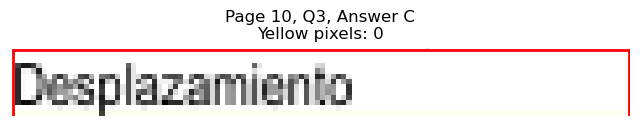

Page 10, Q3 - D: Detected box: x0=327.5, y0=202.9, x1=426.3, y1=215.6
Page 10, Q3, D: Yellow pixels: 1526
Page 10, Q3, D: Total non-white pixels: 2100
Page 10, Q3, D: Yellow percentage: 72.7%


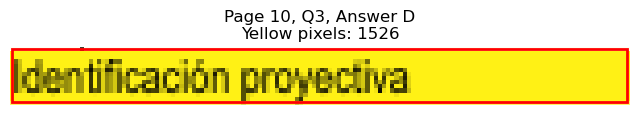


Page 10, Q3 - Selected Answer: D (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=68.3, y0=253.5, x1=119.4, y1=266.1
Page 10, Q4, A: Yellow pixels: 0
Page 10, Q4, A: Total non-white pixels: 247
Page 10, Q4, A: Yellow percentage: 0.0%


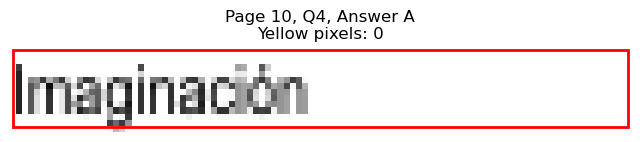

Page 10, Q4 - B: Detected box: x0=68.3, y0=266.1, x1=106.5, y1=278.7
Page 10, Q4, B: Yellow pixels: 0
Page 10, Q4, B: Total non-white pixels: 212
Page 10, Q4, B: Yellow percentage: 0.0%


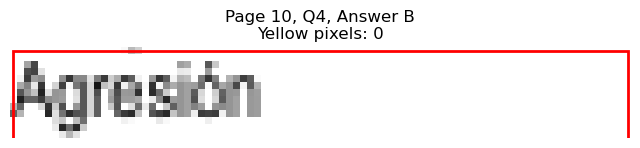

Page 10, Q4 - C: Detected box: x0=327.5, y0=253.5, x1=370.7, y1=266.1
Page 10, Q4, C: Yellow pixels: 94
Page 10, Q4, C: Total non-white pixels: 299
Page 10, Q4, C: Yellow percentage: 31.4%


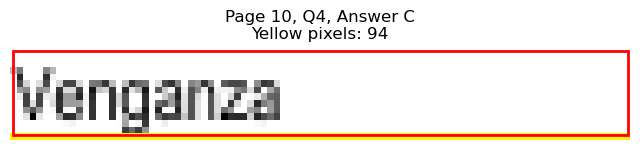

Page 10, Q4 - D: Detected box: x0=327.5, y0=266.1, x1=381.2, y1=278.7
Page 10, Q4, D: Yellow pixels: 1139
Page 10, Q4, D: Total non-white pixels: 1365
Page 10, Q4, D: Yellow percentage: 83.4%


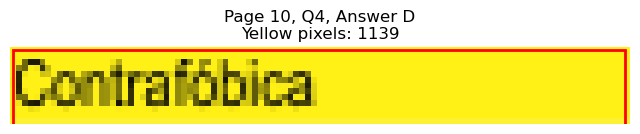


Page 10, Q4 - Selected Answer: D (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=68.3, y0=304.0, x1=134.1, y1=316.7
Page 10, Q5, A: Yellow pixels: 0
Page 10, Q5, A: Total non-white pixels: 368
Page 10, Q5, A: Yellow percentage: 0.0%


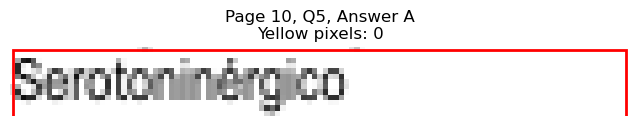

Page 10, Q5 - B: Detected box: x0=68.3, y0=316.6, x1=106.5, y1=329.3
Page 10, Q5, B: Yellow pixels: 0
Page 10, Q5, B: Total non-white pixels: 214
Page 10, Q5, B: Yellow percentage: 0.0%


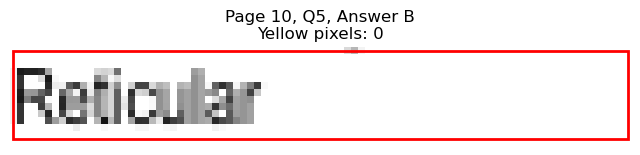

Page 10, Q5 - C: Detected box: x0=327.5, y0=304.0, x1=382.3, y1=316.7
Page 10, Q5, C: Yellow pixels: 0
Page 10, Q5, C: Total non-white pixels: 409
Page 10, Q5, C: Yellow percentage: 0.0%


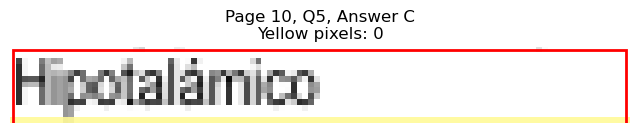

Page 10, Q5 - D: Detected box: x0=327.5, y0=316.6, x1=390.8, y1=329.3
Page 10, Q5, D: Yellow pixels: 1114
Page 10, Q5, D: Total non-white pixels: 1596
Page 10, Q5, D: Yellow percentage: 69.8%


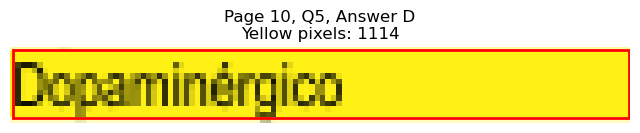


Page 10, Q5 - Selected Answer: D (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=68.3, y0=367.1, x1=104.4, y1=379.8
Page 10, Q6, A: Yellow pixels: 0
Page 10, Q6, A: Total non-white pixels: 174
Page 10, Q6, A: Yellow percentage: 0.0%


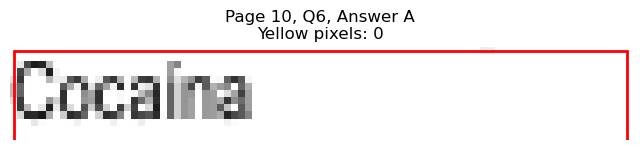

Page 10, Q6 - B: Detected box: x0=68.3, y0=379.7, x1=104.4, y1=392.4
Page 10, Q6, B: Yellow pixels: 0
Page 10, Q6, B: Total non-white pixels: 193
Page 10, Q6, B: Yellow percentage: 0.0%


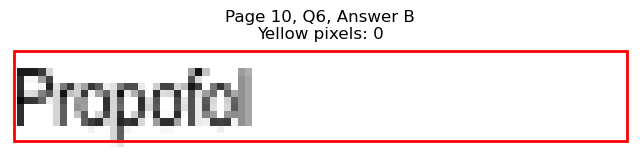

Page 10, Q6 - C: Detected box: x0=327.5, y0=367.1, x1=377.7, y1=379.8
Page 10, Q6, C: Yellow pixels: 1103
Page 10, Q6, C: Total non-white pixels: 1313
Page 10, Q6, C: Yellow percentage: 84.0%


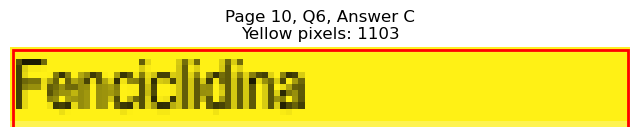

Page 10, Q6 - D: Detected box: x0=327.5, y0=379.7, x1=360.7, y1=392.4
Page 10, Q6, D: Yellow pixels: 84
Page 10, Q6, D: Total non-white pixels: 249
Page 10, Q6, D: Yellow percentage: 33.7%


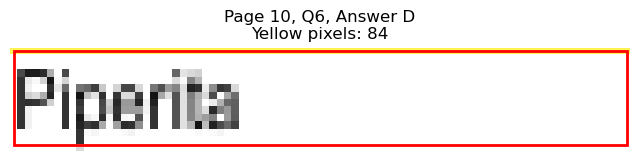


Page 10, Q6 - Selected Answer: C (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=68.3, y0=430.2, x1=153.0, y1=442.9
Page 10, Q7, A: Yellow pixels: 0
Page 10, Q7, A: Total non-white pixels: 617
Page 10, Q7, A: Yellow percentage: 0.0%


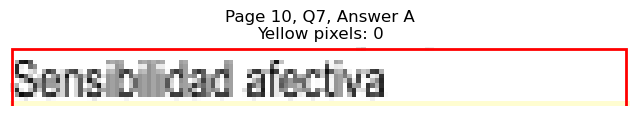

Page 10, Q7 - B: Detected box: x0=68.3, y0=442.8, x1=150.6, y1=455.5
Page 10, Q7, B: Yellow pixels: 1406
Page 10, Q7, B: Total non-white pixels: 1862
Page 10, Q7, B: Yellow percentage: 75.5%


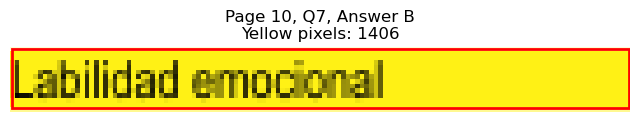

Page 10, Q7 - C: Detected box: x0=327.5, y0=430.2, x1=367.1, y1=442.9
Page 10, Q7, C: Yellow pixels: 0
Page 10, Q7, C: Total non-white pixels: 197
Page 10, Q7, C: Yellow percentage: 0.0%


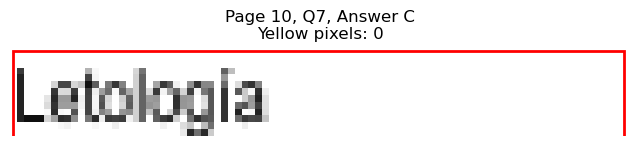

Page 10, Q7 - D: Detected box: x0=327.5, y0=442.8, x1=373.7, y1=455.5
Page 10, Q7, D: Yellow pixels: 0
Page 10, Q7, D: Total non-white pixels: 249
Page 10, Q7, D: Yellow percentage: 0.0%


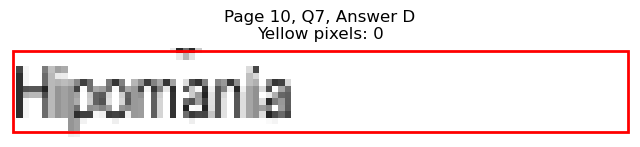


Page 10, Q7 - Selected Answer: B (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=68.3, y0=493.4, x1=112.0, y1=506.0
Page 10, Q8, A: Yellow pixels: 0
Page 10, Q8, A: Total non-white pixels: 255
Page 10, Q8, A: Yellow percentage: 0.0%


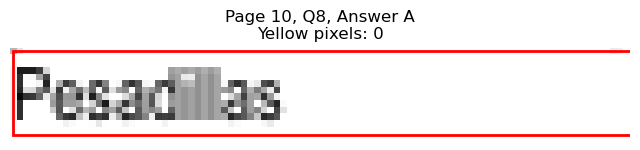

Page 10, Q8 - B: Detected box: x0=68.3, y0=506.0, x1=111.4, y1=518.6
Page 10, Q8, B: Yellow pixels: 0
Page 10, Q8, B: Total non-white pixels: 221
Page 10, Q8, B: Yellow percentage: 0.0%


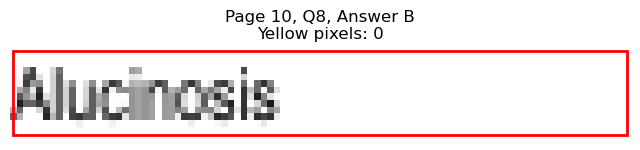

Page 10, Q8 - C: Detected box: x0=327.5, y0=493.4, x1=405.8, y1=506.0
Page 10, Q8, C: Yellow pixels: 1367
Page 10, Q8, C: Total non-white pixels: 1677
Page 10, Q8, C: Yellow percentage: 81.5%


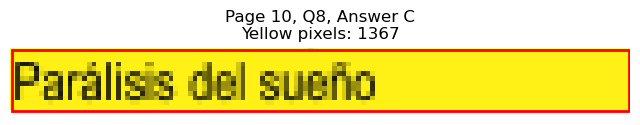

Page 10, Q8 - D: Detected box: x0=327.5, y0=506.0, x1=410.8, y1=518.6
Page 10, Q8, D: Yellow pixels: 134
Page 10, Q8, D: Total non-white pixels: 568
Page 10, Q8, D: Yellow percentage: 23.6%


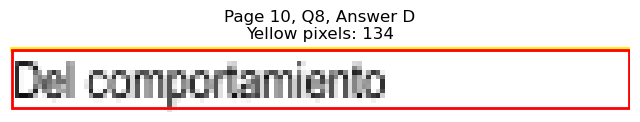


Page 10, Q8 - Selected Answer: C (based on yellow pixel count)




Page 10, Q9 - A: Detected box: x0=68.3, y0=569.1, x1=113.9, y1=581.8
Page 10, Q9, A: Yellow pixels: 1
Page 10, Q9, A: Total non-white pixels: 333
Page 10, Q9, A: Yellow percentage: 0.3%


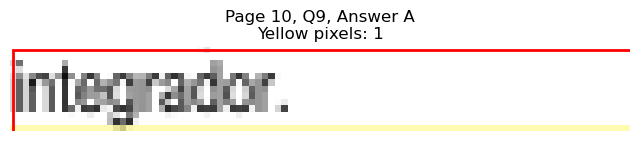

Page 10, Q9 - B: Detected box: x0=68.3, y0=581.7, x1=110.4, y1=594.4
Page 10, Q9, B: Yellow pixels: 959
Page 10, Q9, B: Total non-white pixels: 1302
Page 10, Q9, B: Yellow percentage: 73.7%


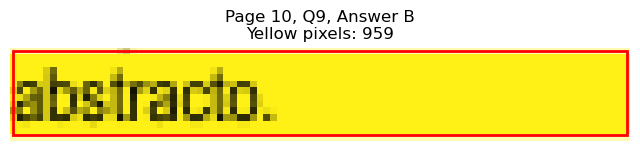

Page 10, Q9 - C: Detected box: x0=327.5, y0=569.1, x1=373.7, y1=581.8
Page 10, Q9, C: Yellow pixels: 0
Page 10, Q9, C: Total non-white pixels: 228
Page 10, Q9, C: Yellow percentage: 0.0%


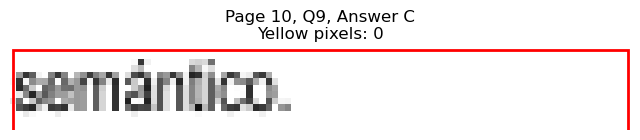

Page 10, Q9 - D: Detected box: x0=327.5, y0=581.7, x1=356.1, y1=594.4
Page 10, Q9, D: Yellow pixels: 0
Page 10, Q9, D: Total non-white pixels: 134
Page 10, Q9, D: Yellow percentage: 0.0%


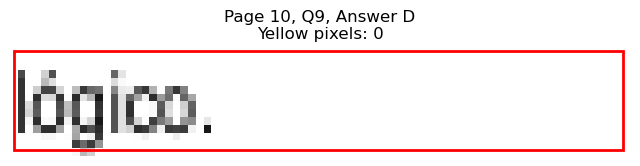


Page 10, Q9 - Selected Answer: B (based on yellow pixel count)




Page 10, Q10 - A: Detected box: x0=68.3, y0=619.6, x1=181.1, y1=632.3
Page 10, Q10, A: Yellow pixels: 164
Page 10, Q10, A: Total non-white pixels: 735
Page 10, Q10, A: Yellow percentage: 22.3%


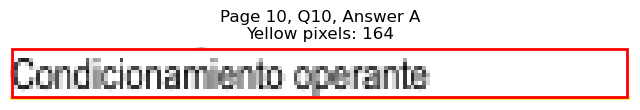

Page 10, Q10 - B: Detected box: x0=68.3, y0=632.2, x1=188.7, y1=644.9
Page 10, Q10, B: Yellow pixels: 1743
Page 10, Q10, B: Total non-white pixels: 2223
Page 10, Q10, B: Yellow percentage: 78.4%


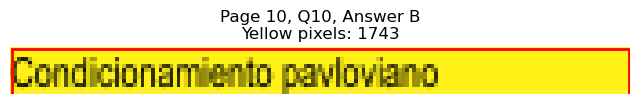

Page 10, Q10 - C: Detected box: x0=327.5, y0=619.6, x1=406.3, y1=632.3
Page 10, Q10, C: Yellow pixels: 0
Page 10, Q10, C: Total non-white pixels: 397
Page 10, Q10, C: Yellow percentage: 0.0%


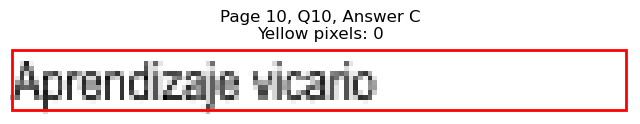

Page 10, Q10 - D: Detected box: x0=327.5, y0=632.2, x1=422.3, y1=644.9
Page 10, Q10, D: Yellow pixels: 0
Page 10, Q10, D: Total non-white pixels: 495
Page 10, Q10, D: Yellow percentage: 0.0%


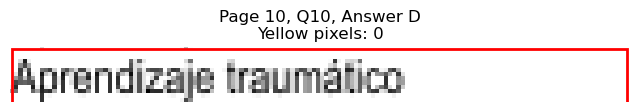


Page 10, Q10 - Selected Answer: B (based on yellow pixel count)




Page 10, Q11 - A: Detected box: x0=68.3, y0=708.0, x1=139.5, y1=720.6
Page 10, Q11, A: Yellow pixels: 122
Page 10, Q11, A: Total non-white pixels: 509
Page 10, Q11, A: Yellow percentage: 24.0%


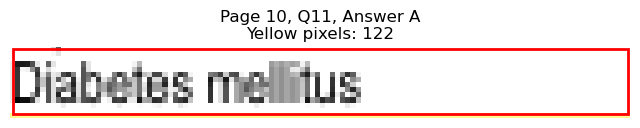

Page 10, Q11 - B: Detected box: x0=68.3, y0=720.6, x1=127.9, y1=733.2
Page 10, Q11, B: Yellow pixels: 1206
Page 10, Q11, B: Total non-white pixels: 1540
Page 10, Q11, B: Yellow percentage: 78.3%


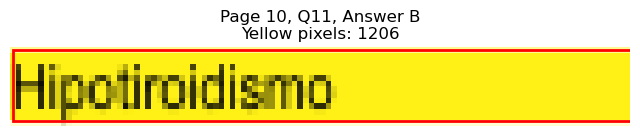

Page 10, Q11 - C: Detected box: x0=327.5, y0=708.0, x1=414.3, y1=720.6
Page 10, Q11, C: Yellow pixels: 0
Page 10, Q11, C: Total non-white pixels: 452
Page 10, Q11, C: Yellow percentage: 0.0%


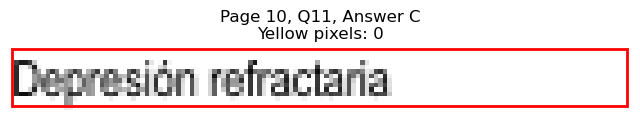

Page 10, Q11 - D: Detected box: x0=327.5, y0=720.6, x1=379.1, y1=733.2
Page 10, Q11, D: Yellow pixels: 0
Page 10, Q11, D: Total non-white pixels: 295
Page 10, Q11, D: Yellow percentage: 0.0%


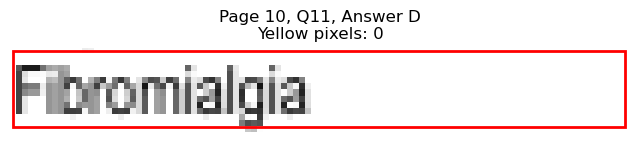


Page 10, Q11 - Selected Answer: B (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,¿Cuál es la lesión encefálica más frecuente en...
1,"Mujer de 24 años, que fue secuestrada y asalta..."
2,"Mujer de 31 años, que llega a terapia por disc..."
3,"De las siguientes técnicas psicoterapéuticas, ..."
4,¿Cuál es el fármaco usado para reducir el crav...
...,...
95,"Varón de 78 años, hipertenso, con antecedentes..."
96,"Mujer de 32 años, se despierta en la noche con..."
97,Varón de 18 años que siempre tuvo dificultades...
98,¿Cuál de los siguientes es el mecanismo clásic...


In [8]:
answers_df

,option_A,option_B,option_C,option_D
0,Leucoencefalopatía,Infarto occipital,Hemorragia aracnoidea,Microinfartos frontales
1,Haloperidol,Litio,Paroxetina,Clobazam
2,Manipulación,Esquizofrenia,Evitación,Agorafobia
3,De esquemas,Cognitivo conductual,Constelaciones familiares,Psicoanálisis
4,Haloperidol,Naltrexona,Tiamina,Ketazolam
...,...,...,...,...
95,Sensibilidad afectiva,Labilidad emocional,Letología,Hipomanía
96,Pesadillas,Alucinosis,Parálisis del sueño,Del comportamiento
97,integrador.,abstracto.,semántico.,lógico.
98,Condicionamiento operante,Condicionamiento pavloviano,Aprendizaje vicario,Aprendizaje traumático


In [9]:
correct_answers_df

,correct_answer
0,A
1,C
2,D
3,B
4,B
...,...
95,B
96,C
97,B
98,B


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,correct_answer
0,¿Cuál es la lesión encefálica más frecuente en...,Leucoencefalopatía,Infarto occipital,Hemorragia aracnoidea,Microinfartos frontales,A
1,"Mujer de 24 años, que fue secuestrada y asalta...",Haloperidol,Litio,Paroxetina,Clobazam,C
2,"Mujer de 31 años, que llega a terapia por disc...",Manipulación,Esquizofrenia,Evitación,Agorafobia,D
3,"De las siguientes técnicas psicoterapéuticas, ...",De esquemas,Cognitivo conductual,Constelaciones familiares,Psicoanálisis,B
4,¿Cuál es el fármaco usado para reducir el crav...,Haloperidol,Naltrexona,Tiamina,Ketazolam,B
...,...,...,...,...,...,...
95,"Varón de 78 años, hipertenso, con antecedentes...",Sensibilidad afectiva,Labilidad emocional,Letología,Hipomanía,B
96,"Mujer de 32 años, se despierta en la noche con...",Pesadillas,Alucinosis,Parálisis del sueño,Del comportamiento,C
97,Varón de 18 años que siempre tuvo dificultades...,integrador.,abstracto.,semántico.,lógico.,B
98,¿Cuál de los siguientes es el mecanismo clásic...,Condicionamiento operante,Condicionamiento pavloviano,Aprendizaje vicario,Aprendizaje traumático,B


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2023/PSIQUIATRÍA.csv
